# EBA 2025 stress test: credit losses by portfolio, per bank

**64 banks · projection years 2025 (Y1), 2026 (Y2), 2027 (Y3) · baseline and adverse · EUR millions**

For every bank in the 2025 EU-wide stress test, this notebook shows the **annual credit losses in
years 1, 2 and 3** of the projection, split by **credit portfolio** (regulatory exposure class), for the
baseline and the adverse scenario, plus the three-year total and the cumulative loss rate. Sections 5
and 6 compare baseline and adverse loss rates per portfolio across Nordic, Western, Eastern and Southern
banks and across bank size groups.

The EBA does not publish a per-portfolio impairment flow. It publishes, per portfolio and year, the
**stock of provisions by IFRS 9 stage** (IRB and Standardised approach templates) and the projected
**impairments on securitisations**. The annual credit loss of a portfolio is therefore measured as the
year-on-year change in its provision stock, starting from the restated end-2024 stock:

$$
L_{b,p,s,t} = \mathrm{Prov}_{b,p,s,t} - \mathrm{Prov}_{b,p,s,t-1}, \qquad \mathrm{Prov}_{b,p,s,2024} = \text{restated 2024 stock}
$$

A positive value is a loss (provision build-up); a negative value is a net release. The stress-test
methodology uses a static balance sheet, so stock changes are driven by impairment flows. As an
independent check, the sum over all portfolios is reconciled bank by bank to the separately disclosed
P&L line *Impairment or reversal of impairment on financial assets not measured at FVPL*
(section 3); it matches to the euro for most banks, and every difference is shown, not hidden.

**Run:** Python 3.10+, then **Restart Kernel and Run All**. Dependencies: `numpy`, `pandas`,
`openpyxl`, `matplotlib`, `IPython`. The five public source files are read from `data/eba_2025/`;
missing files are downloaded once from the EBA (about 140 MB) and every file is SHA-256 verified
against the pinned database release `763451` before use. Figures are hypothetical scenario
outcomes under the stress-test assumptions, not forecasts.

Companion to [eba_stresstest_2025_profit_drivers.ipynb](https://github.com/at621/snippets/blob/main/eba_stresstest_2025_profit_drivers.ipynb),
which decomposes the profit shortfall; its *credit impairments* driver is the total that this notebook splits by portfolio.

## 1. Sources and portfolio definitions

| Source | Used for |
|---|---|
| [EBA 2025 stress test page](https://www.eba.europa.eu/eu-wide-stress-test-2025/) | Database release `763451` |
| [TRA_CRE_IRB.csv](https://www.eba.europa.eu/assets/st25/full_database/763451/TRA_CRE_IRB.csv) | IRB exposures (`2532003`) and stock of provisions (`2532004`) by exposure class and IFRS 9 stage |
| [TRA_CRE_STA.csv](https://www.eba.europa.eu/assets/st25/full_database/763451/TRA_CRE_STA.csv) | SA exposures (`2533003`) and provisions (`2533004`); securitisation exposure (`2534001`) and impairments (`2534003`) |
| [TRA_OTH.csv](https://www.eba.europa.eu/assets/st25/full_database/763451/TRA_OTH.csv) | P&L impairment line (`2536010`) for the reconciliation; bank names |
| [Data dictionary](https://www.eba.europa.eu/assets/st25/full_database/763451/Data_Dictionary.xlsx), [Metadata](https://www.eba.europa.eu/assets/st25/full_database/763451/Metadata_TR.xlsx) | Item labels, exposure-class and scenario codes (checked below) |
| [CSV guide](https://www.eba.europa.eu/assets/st25/full_database/763451/CSV_guide.pdf) | File structure and dimensions |

Only the **country total** rows (`Country = 0`) are used; the top-10 country breakdown would double count.
Scenario codes: `11` restated 2024, `2` baseline, `3` adverse.

**Portfolios.** IRB and SA exposures are combined into eight portfolios following the regulatory
exposure classes. One asymmetry is inherent in the regulation: under the **SA**, exposures secured by
immovable property are a separate class (*Secured by real estate (SA)*), whereas under **IRB** retail
mortgages sit inside *Retail* and commercial real estate inside *Corporates*. Each bank report has a
drill-down by approach and sub-segment, so nothing is lost by the grouping.

| Portfolio | IRB exposure classes | SA exposure classes |
|---|---|---|
| Corporates | Specialised lending, SME, other corporates (incl. purchased receivables) | Specialised lending, SME, other corporates |
| Retail | Secured by real estate, qualifying revolving, other retail SME / non-SME, purchased receivables | Retail SME, other retail |
| Secured by real estate (SA) | – | Residential, commercial, land acquisition / development / construction (ADC) |
| Institutions | Institutions | Institutions |
| Central banks & governments | Central banks, central governments | Central banks, central governments |
| Other public sector | Regional governments, public sector entities | Regional governments, PSEs, MDBs, international organisations |
| Equity & other | Equity, other non-credit-obligation assets, CIUs | Equity, other exposures, covered bonds, short-term rated claims, CIUs, subordinated debt |
| Securitisations | Securitisation impairments (all approaches, not split by stage) | |

*Other corporates* is derived as the corporates total minus specialised lending and SME, and *Other retail (SA)*
as retail minus retail SME; the code checks that each derived residual is non-negative and that the
sub-segments add back exactly to each approach's reported total.

In [1]:
from pathlib import Path
from urllib.request import Request, urlopen
import hashlib
import html
import importlib.metadata
import platform
import re
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, StrMethodFormatter
from IPython.display import HTML, Markdown, display

DATA_DIR = Path('data/eba_2025')
DOWNLOAD_IF_MISSING = True   # Fetch missing source files from the EBA, then verify their hashes.
EXPORT_RESULTS = False       # Optional CSV exports under OUTPUT_DIR.
OUTPUT_DIR = Path('output/eba_2025_credit_losses')

YEARS = (2025, 2026, 2027)
PERIODS = tuple(year * 100 + 12 for year in YEARS)
START_PERIOD = 202412
RESTATED, BASELINE, ADVERSE = 11, 2, 3
SCENARIO_NAME = {BASELINE: 'Baseline', ADVERSE: 'Adverse'}
YEAR_LABEL = {2025: 'Y1 2025', 2026: 'Y2 2026', 2027: 'Y3 2027'}
ABS_TOL = 1e-5     # EUR million, for exact accounting identities.
RECON_TOL = 0.5    # EUR million, for the cross-template reconciliation to the P&L.
EXPECTED_BANKS = 64

# Chart tokens (light surface). Portfolio colours follow the portfolio, never its rank.
SURFACE, INK, INK_2, MUTED, GRID, AXIS = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
PORTFOLIOS = ['Corporates', 'Retail', 'Secured by real estate (SA)', 'Institutions',
              'Central banks & governments', 'Other public sector', 'Equity & other', 'Securitisations']
PORTFOLIO_COLOR = dict(zip(PORTFOLIOS, ['#2a78d6', '#eb6834', '#1baf7a', '#eda100',
                                        '#e87ba4', '#008300', '#6250d6', '#e34948']))

pd.set_option('display.max_colwidth', 120)
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 9.5, 'text.color': INK,
    'axes.labelcolor': INK_2, 'xtick.color': INK_2, 'ytick.color': MUTED,
    'axes.edgecolor': AXIS, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.spines.left': False, 'axes.titleweight': 'bold', 'figure.dpi': 100,
    'savefig.dpi': 140, 'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE,
})
display(HTML("""<style>
.cl-wrap { overflow-x:auto; margin:6px 0 18px; }
.cl-table { border-collapse:collapse; font-size:12.5px; font-variant-numeric:tabular-nums; }
.cl-table th { text-align:right; padding:5px 9px; border-bottom:1px solid rgba(127,127,127,.45); white-space:nowrap; }
.cl-table th.grp { text-align:center; border-bottom:2px solid rgba(127,127,127,.7); }
.cl-table td { text-align:right; padding:4px 9px; border-bottom:1px solid rgba(127,127,127,.18); white-space:nowrap; }
.cl-table th.txt, .cl-table td.txt { text-align:left; }
.cl-table tr.total td { font-weight:bold; border-top:2px solid rgba(127,127,127,.7); }
.cl-table tr.memo td { font-style:italic; opacity:.75; }
.cl-table tbody tr:hover { background:rgba(127,127,127,.08); }
.cl-note { font-size:12.5px; opacity:.85; max-width:980px; }
.cl-bank { margin-top:28px; padding-top:10px; border-top:3px solid rgba(127,127,127,.5); }
details.cl-details summary { cursor:pointer; font-weight:bold; margin:4px 0 8px; }
</style>"""))


def fmt_value(value, kind):
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return '–'
    if kind == 'text':
        return html.escape(str(value))
    if kind == 'pct':
        return f'{value:,.2f}%'
    if kind == 'int':
        return f'{value:,.0f}'
    shown = 0.0 if abs(value) < 0.05 else value
    return f'{shown:,.1f}'


def table_html(frame, kinds, groups=None, caption=None, row_class=None):
    """Render a DataFrame as an HTML table. kinds: one of text/num/int/pct per column;
    groups: optional list of (label, span) header groups; row_class: per-row CSS class."""
    head = ''
    if groups:
        head += '<tr>' + ''.join(f'<th class="grp" colspan="{span}">{html.escape(label)}</th>'
                                 for label, span in groups) + '</tr>'
    head += '<tr>' + ''.join(f'<th class="{"txt" if kind == "text" else ""}">{html.escape(str(col))}</th>'
                             for col, kind in zip(frame.columns, kinds)) + '</tr>'
    body = []
    classes = row_class or [''] * len(frame)
    for (_, row), cls in zip(frame.iterrows(), classes):
        cells = ''.join(f'<td class="{"txt" if kind == "text" else ""}">{fmt_value(value, kind)}</td>'
                        for value, kind in zip(row.tolist(), kinds))
        body.append(f'<tr class="{cls}">{cells}</tr>')
    heading = f'<p><strong>{html.escape(caption)}</strong></p>' if caption else ''
    return (heading + '<div class="cl-wrap"><table class="cl-table"><thead>' + head
            + '</thead><tbody>' + ''.join(body) + '</tbody></table></div>')


versions = {'Python': platform.python_version()}
versions.update({name: importlib.metadata.version(name)
                 for name in ['numpy', 'pandas', 'openpyxl', 'matplotlib', 'IPython']})
print('Runtime:', ', '.join(f'{key} {value}' for key, value in versions.items()))

Runtime: Python 3.13.1, numpy 2.2.4, pandas 2.2.3, openpyxl 3.1.5, matplotlib 3.10.1, IPython 9.0.2


In [2]:
BASE_URL = 'https://www.eba.europa.eu/assets/st25/full_database/763451/'
SOURCE_MANIFEST = {
    'TRA_CRE_IRB.csv': {'sha256': '38087207191702dde669df6b1e7b29aa8f082e57d59646467334437f1214c6d0', 'bytes': 62215416},
    'TRA_CRE_STA.csv': {'sha256': 'ae94e02a6c6d4290dfde02cbae65e9a60ad1cefde3facf5cffbaf8ccef13cec7', 'bytes': 70053968},
    'TRA_OTH.csv': {'sha256': 'e7a48b99984d8728b5b24285d9b00aed94b605a7855705f04b41c5b21da5378a', 'bytes': 6223488},
    'Data_Dictionary.xlsx': {'sha256': '46ea6eb59eec41e57ed6fb4c327aa147ce49d4fed6c99d29c537be7f5d94fa22', 'bytes': 27210},
    'Metadata_TR.xlsx': {'sha256': '5f3fab231e4a3d254abfdf246e701f1860e12f6850bec29b771dbd52436e6274', 'bytes': 114960},
}


def verify(name, raw):
    spec = SOURCE_MANIFEST[name]
    if len(raw) != spec['bytes'] or hashlib.sha256(raw).hexdigest() != spec['sha256']:
        raise ValueError(f'{name}: content differs from pinned release 763451. '
                         'Review any revised EBA release before changing the manifest.')


def source_path(name):
    path = DATA_DIR / name
    if not path.is_file():
        if not DOWNLOAD_IF_MISSING:
            raise FileNotFoundError(f'Missing {path}; download {BASE_URL + name}')
        print(f'Downloading {name} …')
        request = Request(BASE_URL + name, headers={'User-Agent': 'Mozilla/5.0'})
        with urlopen(request, timeout=600) as response:
            raw = response.read()
        verify(name, raw)
        DATA_DIR.mkdir(parents=True, exist_ok=True)
        path.write_bytes(raw)
    verify(name, path.read_bytes())
    return path


def read_facts(name, expected_columns):
    frame = pd.read_csv(source_path(name), encoding='utf-8-sig', dtype={'Fact_char': str},
                        keep_default_na=False, na_values={'Amount': ['', '.']})
    frame.columns = frame.columns.str.strip().str.lower()
    if set(frame.columns) != set(expected_columns):
        raise ValueError(f'{name}: unexpected schema {list(frame.columns)}')
    return frame


CRE_COLUMNS = ['country_code', 'lei_code', 'bank_name', 'period', 'item', 'scenario', 'portfolio',
               'ifrs9_stages', 'exposure', 'country', 'country_rank', 'perf_status', 'amount']
OTH_COLUMNS = ['country_code', 'lei_code', 'bank_name', 'period', 'item', 'scenario', 'fact_char', 'amount']
irb_facts = read_facts('TRA_CRE_IRB.csv', CRE_COLUMNS)
sta_facts = read_facts('TRA_CRE_STA.csv', CRE_COLUMNS)
oth_facts = read_facts('TRA_OTH.csv', OTH_COLUMNS)
dictionary = pd.read_excel(source_path('Data_Dictionary.xlsx'), sheet_name='SDD')
exposure_meta = pd.read_excel(source_path('Metadata_TR.xlsx'), sheet_name='Exposure')

banks = (oth_facts[['country_code', 'lei_code', 'bank_name']].drop_duplicates()
         .sort_values(['country_code', 'bank_name']).set_index('lei_code'))
if banks.index.duplicated().any() or len(banks) != EXPECTED_BANKS:
    raise ValueError(f'Expected {EXPECTED_BANKS} uniquely named banks, found {len(banks)}')
LEIS = banks.index.tolist()
print(f'{len(irb_facts):,} IRB rows, {len(sta_facts):,} SA/SEC rows, {len(oth_facts):,} P&L rows; {len(banks)} banks.')

534,600 IRB rows, 595,826 SA/SEC rows, 64,128 P&L rows; 64 banks.


In [3]:
def normalized(text):
    return re.sub(r'\s+', ' ', str(text)).strip()

ITEMS = {
    'irb_exposure': (2532003, 'TRA_CR_IRB', 'IRB - Exposures by IFRS9 Stages'),
    'irb_provisions': (2532004, 'TRA_CR_IRB', 'IRB - Stock of Provisions by IFRS9 Stages'),
    'sa_exposure': (2533003, 'TRA_CR_STA', 'SA - Exposures by IFRS9 Stages'),
    'sa_provisions': (2533004, 'TRA_CR_STA', 'SA - Stock of Provisions by IFRS9 Stages'),
    'sec_exposure': (2534001, 'TRA_CR_SEC', 'SEC - Exposure values (actual/restated figures) - by Portfolio'),
    'sec_impairments': (2534003, 'TRA_CR_SEC', 'SEC - Impairments (actual/restated and projected figures)'),
    'pl_impairment': (2536010, 'TRA_P&L', 'Impairment (-) or reversal of impairment (+) on financial assets '
                                          'not measured at fair value through profit or loss'),
}
dictionary_by_item = dictionary.set_index('Item')
for key, (item, template, label) in ITEMS.items():
    row = dictionary_by_item.loc[item]
    if row['Collection'] != 'ST2025' or row['Template'] != template or normalized(row['Label']) != label:
        raise ValueError(f'Dictionary mismatch for {key}: {row.to_dict()}')
ITEM = {key: spec[0] for key, spec in ITEMS.items()}

# Leaf segments per approach: (approach, portfolio, segment, codes added, codes subtracted).
SEGMENT_SPECS = [
    ('IRB', 'Central banks & governments', 'Central banks', [1110], []),
    ('IRB', 'Central banks & governments', 'Central governments', [1120], []),
    ('IRB', 'Other public sector', 'Regional governments or local authorities', [1200], []),
    ('IRB', 'Other public sector', 'Public sector entities', [1300], []),
    ('IRB', 'Institutions', 'Institutions', [2000], []),
    ('IRB', 'Corporates', 'Specialised lending', [3100], []),
    ('IRB', 'Corporates', 'SME', [3330], []),
    ('IRB', 'Corporates', 'Other corporates (incl. purchased receivables)', [3000], [3100, 3330]),
    ('IRB', 'Retail', 'Secured by real estate', [4150], []),
    ('IRB', 'Retail', 'Qualifying revolving', [4200], []),
    ('IRB', 'Retail', 'Other retail – SME', [4310], []),
    ('IRB', 'Retail', 'Other retail – non-SME', [4320], []),
    ('IRB', 'Retail', 'Purchased receivables', [4800], []),
    ('IRB', 'Equity & other', 'Equity', [6100], []),
    ('IRB', 'Equity & other', 'Other non-credit obligation assets', [6300], []),
    ('IRB', 'Equity & other', 'Collective investment undertakings', [6700], []),
    ('SA', 'Central banks & governments', 'Central banks', [1110], []),
    ('SA', 'Central banks & governments', 'Central governments', [1120], []),
    ('SA', 'Other public sector', 'Regional governments or local authorities', [1200], []),
    ('SA', 'Other public sector', 'Public sector entities', [1300], []),
    ('SA', 'Other public sector', 'Multilateral development banks', [1400], []),
    ('SA', 'Other public sector', 'International organisations', [1500], []),
    ('SA', 'Institutions', 'Institutions', [2000], []),
    ('SA', 'Corporates', 'Specialised lending', [3100], []),
    ('SA', 'Corporates', 'SME', [3330], []),
    ('SA', 'Corporates', 'Other corporates', [3000], [3100, 3330]),
    ('SA', 'Retail', 'Retail – SME', [4500], []),
    ('SA', 'Retail', 'Other retail', [4000], [4500]),
    ('SA', 'Secured by real estate (SA)', 'Residential immovable property', [5300], []),
    ('SA', 'Secured by real estate (SA)', 'Commercial immovable property', [5400], []),
    ('SA', 'Secured by real estate (SA)', 'Land acquisition, development & construction', [5600], []),
    ('SA', 'Equity & other', 'Equity', [6100], []),
    ('SA', 'Equity & other', 'Other exposures', [6300], []),
    ('SA', 'Equity & other', 'Covered bonds', [6500], []),
    ('SA', 'Equity & other', 'Short-term rated claims on institutions/corporates', [6600], []),
    ('SA', 'Equity & other', 'Collective investment undertakings', [6700], []),
    ('SA', 'Equity & other', 'Subordinated debt exposures', [6800], []),
]
SEGMENTS = pd.DataFrame(SEGMENT_SPECS, columns=['approach', 'portfolio', 'segment', 'plus', 'minus'])
assert set(SEGMENTS['portfolio']) | {'Securitisations'} == set(PORTFOLIOS)
known_codes = set(exposure_meta['Exposure'])
for codes in SEGMENTS['plus'].tolist() + SEGMENTS['minus'].tolist():
    if not set(codes) <= known_codes:
        raise ValueError(f'Unknown exposure code in {codes}')
show = SEGMENTS.assign(**{'exposure codes': [' + '.join(map(str, p)) + ''.join(f' − {m}' for m in n)
                                             for p, n in zip(SEGMENTS['plus'], SEGMENTS['minus'])]})
display(HTML(table_html(show[['approach', 'portfolio', 'segment', 'exposure codes']],
                        ['text'] * 4, caption='Segment map (Metadata_TR / Exposure codes)')))

approach,portfolio,segment,exposure codes
IRB,Central banks & governments,Central banks,1110
IRB,Central banks & governments,Central governments,1120
IRB,Other public sector,Regional governments or local authorities,1200
IRB,Other public sector,Public sector entities,1300
IRB,Institutions,Institutions,2000
IRB,Corporates,Specialised lending,3100
IRB,Corporates,SME,3330
IRB,Corporates,Other corporates (incl. purchased receivables),3000 − 3100 − 3330
IRB,Retail,Secured by real estate,4150
IRB,Retail,Qualifying revolving,4200


## 2. From provision stocks to annual credit losses

The provision and exposure items are panels of bank × exposure class × IFRS 9 stage × scenario/year.
The code requires every one of these cells to be present (a missing value is never treated as zero),
rejects duplicate keys, and checks that the leaf segments add back to each approach's reported total
for every bank, stage, scenario and year. Securitisation impairments are published directly as annual
flows (positive = loss) without a stage split; they are added as their own portfolio.

In [4]:
STOCK_COLUMNS = [(RESTATED, START_PERIOD)] + [(s, p) for s in (BASELINE, ADVERSE) for p in PERIODS]


def stock_panel(facts, item, name):
    """Wide panel: index (lei, exposure, stage); columns (scenario, period)."""
    rows = facts.loc[(facts['item'] == item) & (facts['country'] == 0)]
    if not (rows['country_rank'].eq(0).all() and rows['perf_status'].eq(0).all()
            and rows['ifrs9_stages'].isin([1, 2, 3]).all()):
        raise ValueError(f'{name}: unexpected dimensions on country-total rows')
    key = ['lei_code', 'exposure', 'ifrs9_stages', 'scenario', 'period']
    if rows.duplicated(key).any():
        raise ValueError(f'{name}: duplicate keys; refusing to aggregate')
    wide = rows.pivot(index=key[:3], columns=['scenario', 'period'], values='amount')
    codes = sorted(rows['exposure'].unique())
    full = pd.MultiIndex.from_product([LEIS, codes, [1, 2, 3]], names=['lei_code', 'exposure', 'stage'])
    wide = wide.reindex(index=full, columns=pd.MultiIndex.from_tuples(STOCK_COLUMNS, names=['scenario', 'period']))
    if wide.isna().any().any() or not np.isfinite(wide.to_numpy()).all():
        raise ValueError(f'{name}: missing or non-finite values in {int(wide.isna().sum().sum())} cells')
    return wide


def segment_stocks(panel, approach):
    """Leaf-segment stocks: index (lei, approach, portfolio, segment, stage)."""
    parts = {}
    for seg in SEGMENTS.loc[SEGMENTS['approach'] == approach].itertuples():
        value = sum(panel.xs(c, level='exposure') for c in seg.plus)
        value = value - sum((panel.xs(c, level='exposure') for c in seg.minus), 0)
        # Reported stocks are used as published (a few are slightly negative); a derived
        # residual must not be meaningfully more negative than its reported inputs allow.
        if seg.minus and (value < -ABS_TOL).any().any():
            raise ValueError(f'{approach} {seg.segment}: derived residual is negative')
        parts[(approach, seg.portfolio, seg.segment)] = value
    out = pd.concat(parts, names=['approach', 'portfolio', 'segment'])
    total = out.groupby(level=['lei_code', 'stage']).sum()
    error = (total - panel.xs(0, level='exposure').reindex(total.index)).abs().to_numpy().max()
    if error > ABS_TOL:
        raise ValueError(f'{approach}: segments do not add up to the reported total ({error})')
    return out.reorder_levels(['lei_code', 'approach', 'portfolio', 'segment', 'stage']), error


def stock_to_flows(stocks):
    """Annual change in stock per scenario; columns (scenario, year)."""
    flows = {}
    for scenario in (BASELINE, ADVERSE):
        previous = stocks[(RESTATED, START_PERIOD)]
        for year, period in zip(YEARS, PERIODS):
            flows[(scenario, year)] = stocks[(scenario, period)] - previous
            previous = stocks[(scenario, period)]
    return pd.DataFrame(flows).rename_axis(columns=['scenario', 'year'])


identity_checks = []
provisions, exposures = [], []
for approach, facts, prov_key, exp_key in [('IRB', irb_facts, 'irb_provisions', 'irb_exposure'),
                                           ('SA', sta_facts, 'sa_provisions', 'sa_exposure')]:
    prov, error_p = segment_stocks(stock_panel(facts, ITEM[prov_key], prov_key), approach)
    expo, error_e = segment_stocks(stock_panel(facts, ITEM[exp_key], exp_key), approach)
    identity_checks += [(f'{approach} provisions: segments = reported total', error_p),
                        (f'{approach} exposures: segments = reported total', error_e)]
    provisions.append(prov)
    exposures.append(expo)
provision_stocks = pd.concat(provisions)
exposure_stocks = pd.concat(exposures)

# Securitisations: impairments are already annual flows; exposure is the 2024 total over SEC approaches.
sec = sta_facts.loc[sta_facts['item'] == ITEM['sec_impairments']]
if sec.duplicated(['lei_code', 'scenario', 'period']).any() or sec['portfolio'].ne(0).any():
    raise ValueError('Unexpected securitisation impairment dimensions')
sec_flows = (sec.pivot(index='lei_code', columns=['scenario', 'period'], values='amount')
             .reindex(index=LEIS, columns=pd.MultiIndex.from_product([(BASELINE, ADVERSE), PERIODS])))
if sec_flows.isna().any().any():
    raise ValueError('Missing securitisation impairments')
sec_flows.columns = pd.MultiIndex.from_tuples([(s, p // 100) for s, p in sec_flows.columns], names=['scenario', 'year'])
sec_flows.index = pd.MultiIndex.from_tuples([(lei, 'SEC', 'Securitisations', 'Securitisations', 0) for lei in LEIS],
                                            names=provision_stocks.index.names)
sec_exp = sta_facts.loc[(sta_facts['item'] == ITEM['sec_exposure']) & (sta_facts['portfolio'] == 0)
                        & (sta_facts['scenario'] == RESTATED)]
sec_exp = sec_exp.set_index('lei_code')['amount'].reindex(LEIS)
if sec_exp.isna().any() or sec_exp.index.duplicated().any():
    raise ValueError('Missing or duplicate securitisation exposures')

# losses: bank × approach × portfolio × segment × stage (stage 0 = not split), columns (scenario, year).
losses = pd.concat([stock_to_flows(provision_stocks), sec_flows]).sort_index()
exposure_2024 = pd.concat([
    exposure_stocks[(RESTATED, START_PERIOD)].groupby(level=['lei_code', 'approach', 'portfolio', 'segment']).sum(),
    pd.Series(sec_exp.to_numpy(), index=pd.MultiIndex.from_tuples(
        [(lei, 'SEC', 'Securitisations', 'Securitisations') for lei in LEIS],
        names=['lei_code', 'approach', 'portfolio', 'segment']))]).sort_index()
negative = provision_stocks.stack(['scenario', 'period'], future_stack=True)
negative = negative[negative < -ABS_TOL]
print(f'{len(losses):,} bank/segment/stage loss series × {losses.shape[1]} scenario-years.')
print(f'{len(negative)} reported provision-stock cells are negative (kept as published; most negative '
      f'EUR {negative.min():,.2f} m, {negative.idxmin()[0]}).' if len(negative) else 'No negative provision stocks.')

7,168 bank/segment/stage loss series × 6 scenario-years.
9 reported provision-stock cells are negative (kept as published; most negative EUR -5.54 m, 635400C8EK6DRI12LJ39).


## 3. Reconciliation to the P&L impairment line

The P&L template (`TRA_P&L`) discloses total credit impairments per year. It is produced from the same
projections but in a different template, so it is an independent check of the stock-change measure.
The P&L sign convention is negative for a loss; it is flipped here. Where a bank shows a difference,
the same amount usually appears in Y1 of both scenarios, which points to the starting point
(e.g. a restatement or overlay booked outside the credit-risk templates) rather than to the projection.
Per-portfolio figures are never adjusted; differences are reported per bank.

In [5]:
pl = oth_facts.loc[(oth_facts['item'] == ITEM['pl_impairment']) & oth_facts['scenario'].isin([BASELINE, ADVERSE])]
if pl.duplicated(['lei_code', 'scenario', 'period']).any():
    raise ValueError('Duplicate P&L impairment facts')
pl_losses = -pl.pivot(index='lei_code', columns=['scenario', 'period'], values='amount')
pl_losses.columns = pd.MultiIndex.from_tuples([(s, p // 100) for s, p in pl_losses.columns], names=['scenario', 'year'])
bank_losses = losses.groupby(level='lei_code').sum()
pl_losses = pl_losses.reindex(index=bank_losses.index, columns=bank_losses.columns)
if pl_losses.isna().any().any():
    raise ValueError('Missing P&L impairment values')
recon_diff = bank_losses - pl_losses
recon_max = recon_diff.abs().max(axis=1)

# Anchor: Deutsche Bank PDF (p. 25) impairments, baseline 2025-27 then adverse 2025-27, EUR m rounded.
DB_PDF = [3743, 2085, 2136, 9003, 3026, 2114]
db_observed = bank_losses.loc['7LTWFZYICNSX8D621K86'].to_numpy()
identity_checks.append(('Deutsche Bank PDF impairments (rounded)', float(np.abs(db_observed - DB_PDF).max())))
if identity_checks[-1][1] > 0.51:
    raise ValueError('Deutsche Bank PDF anchor not reproduced')

display(HTML(table_html(pd.DataFrame(identity_checks, columns=['Check', 'Max abs. difference (EUR m)']),
                        ['text', 'num'], caption='Accounting identity and anchor checks')))
matched = int((recon_max <= RECON_TOL).sum())
display(Markdown(f'**{matched} of {len(recon_max)} banks** reconcile to the P&L impairment line within '
                 f'EUR {RECON_TOL} m in all six scenario-years. Summed over all banks, three-year credit losses '
                 f'from the credit templates are EUR {bank_losses[ADVERSE].to_numpy().sum():,.0f} m adverse and '
                 f'EUR {bank_losses[BASELINE].to_numpy().sum():,.0f} m baseline, against '
                 f'EUR {pl_losses[ADVERSE].to_numpy().sum():,.0f} m and EUR {pl_losses[BASELINE].to_numpy().sum():,.0f} m '
                 'in the P&L.'))
off = recon_diff.loc[recon_max > RECON_TOL]
if len(off):
    frame = off.copy()
    frame.columns = [f'{SCENARIO_NAME[s]} {YEAR_LABEL[y]}' for s, y in frame.columns]
    frame.insert(0, 'Bank', banks.loc[frame.index, 'bank_name'])
    frame.insert(0, 'Country', banks.loc[frame.index, 'country_code'])
    display(HTML(table_html(frame.reset_index(drop=True), ['text', 'text'] + ['num'] * 6,
                            caption='Banks with a difference: credit-template losses minus P&L impairments (EUR m)')))

Check,Max abs. difference (EUR m)
IRB provisions: segments = reported total,0.0
IRB exposures: segments = reported total,0.0
SA provisions: segments = reported total,0.0
SA exposures: segments = reported total,0.0
Deutsche Bank PDF impairments (rounded),0.5


**52 of 64 banks** reconcile to the P&L impairment line within EUR 0.5 m in all six scenario-years. Summed over all banks, three-year credit losses from the credit templates are EUR 394,010 m adverse and EUR 139,842 m baseline, against EUR 394,325 m and EUR 139,464 m in the P&L.

Country,Bank,Baseline Y1 2025,Baseline Y2 2026,Baseline Y3 2027,Adverse Y1 2025,Adverse Y2 2026,Adverse Y3 2027
BE,KBC Group NV,0.9,0.0,0.0,1.0,0.0,0.0
GR,ALPHA SERVICES & HOLDINGS S.A.,-99.9,-96.5,-99.8,-131.4,-128.1,-127.1
IE,Bank of Ireland Group plc,-21.1,-19.4,-21.0,-53.8,-33.8,-24.1
DE,Citigroup Global Markets Europe AG,-1.5,-1.5,-1.5,-1.5,-1.5,-1.5
FI,OP Osuuskunta,368.2,0.0,0.0,368.2,0.0,0.0
SE,Skandinaviska Enskilda Banken — group,-0.1,0.0,0.0,-0.1,0.0,-350.0
PT,"Banco Comercial Português, SA",0.9,1.1,0.8,-41.5,-44.2,-35.0
ES,"Banco Bilbao Vizcaya Argentaria, S.A.",1.5,1.5,1.5,1.5,1.5,1.5
GR,PIRAEUS FINANCIAL HOLDINGS S.A.,-130.6,-120.5,-105.5,-186.9,-134.7,-114.0
DK,Danske Bank A/S,708.9,0.0,0.0,708.9,0.0,0.0


## 4. All banks

The tables below summarise every bank; the individual reports in section 7 give the portfolio detail.
Loss rates are cumulative three-year losses divided by the restated end-2024 exposure of the same
portfolio (IFRS 9 stage total; securitisations: exposure value). Bank size strongly affects absolute
amounts; this is not a ranking of capital resilience.

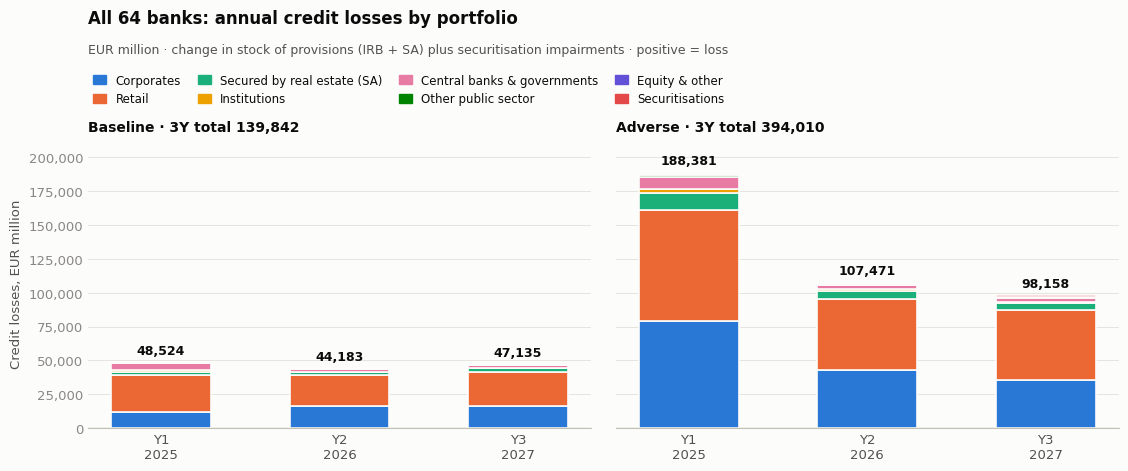

In [6]:
def portfolio_view(lei=None):
    """Losses (portfolio × (scenario, year)) and 2024 exposure per portfolio, for one bank or all."""
    frame = losses if lei is None else losses.loc[[lei]]
    expo = exposure_2024 if lei is None else exposure_2024.loc[[lei]]
    return (frame.groupby(level='portfolio').sum().reindex(PORTFOLIOS, fill_value=0.0),
            expo.groupby(level='portfolio').sum().reindex(PORTFOLIOS, fill_value=0.0))


def scenario_block(values, exposure):
    """Columns Y1, Y2, Y3, 3Y total and 3Y loss rate for one scenario."""
    out = {YEAR_LABEL[y]: values[y] for y in YEARS}
    total = sum(values[y] for y in YEARS)
    out['3Y total'] = total
    out['3Y loss rate'] = np.where(exposure > 0, 100 * total / np.where(exposure > 0, exposure, 1), np.nan)
    return out


def portfolio_table(lei=None, caption=None):
    port, expo = portfolio_view(lei)
    keep = (port.abs().sum(axis=1) > 0.05) | (expo > 0.5)
    port, expo = port.loc[keep], expo.loc[keep]
    rows = pd.DataFrame({'Portfolio': port.index, '2024 exposure': expo.to_numpy()})
    total_row = {'Portfolio': 'Total credit losses', '2024 exposure': expo.sum()}
    for scenario in (BASELINE, ADVERSE):
        block = scenario_block({y: port[(scenario, y)].to_numpy() for y in YEARS}, expo.to_numpy())
        total_block = scenario_block({y: port[(scenario, y)].sum() for y in YEARS}, np.array(expo.sum()))
        for key, value in block.items():
            rows[f'{SCENARIO_NAME[scenario]}|{key}'] = value
            total_row[f'{SCENARIO_NAME[scenario]}|{key}'] = float(np.asarray(total_block[key]))
    rows = pd.concat([rows, pd.DataFrame([total_row])], ignore_index=True)
    classes = [''] * (len(rows) - 1) + ['total']
    pl_row = {'Portfolio': 'Memo: P&L impairment line', '2024 exposure': np.nan}
    diff_row = {'Portfolio': 'Memo: difference', '2024 exposure': np.nan}
    pl_vals = pl_losses.sum() if lei is None else pl_losses.loc[lei]
    for scenario in (BASELINE, ADVERSE):
        for y in YEARS:
            col = f'{SCENARIO_NAME[scenario]}|{YEAR_LABEL[y]}'
            pl_row[col] = pl_vals[(scenario, y)]
            diff_row[col] = total_row[col] - pl_vals[(scenario, y)]
        col = f'{SCENARIO_NAME[scenario]}|3Y total'
        pl_row[col] = sum(pl_vals[(scenario, y)] for y in YEARS)
        diff_row[col] = total_row[col] - pl_row[col]
    rows = pd.concat([rows, pd.DataFrame([pl_row, diff_row])], ignore_index=True)
    classes += ['memo', 'memo']
    groups = [('', 2), ('Baseline', 5), ('Adverse', 5)]
    kinds = ['text', 'int'] + (['num'] * 4 + ['pct']) * 2
    rows.columns = [c.split('|')[-1] for c in rows.columns]
    return table_html(rows, kinds, groups=groups, caption=caption, row_class=classes)


def loss_chart(port, title, subtitle):
    """Two panels (baseline | adverse), stacked annual losses by portfolio, shared y-axis."""
    present = [p for p in PORTFOLIOS if port.loc[p].abs().sum() > 0.05]
    x = np.arange(len(YEARS))
    fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.9), sharey=True)
    for ax, scenario in zip(axes, (BASELINE, ADVERSE)):
        up, down = np.zeros(len(YEARS)), np.zeros(len(YEARS))
        for p in present:
            values = port.loc[p, scenario].reindex(YEARS).to_numpy(float)
            bottom = np.where(values >= 0, up, down)
            ax.bar(x, values, bottom=bottom, width=.56, color=PORTFOLIO_COLOR[p],
                   edgecolor=SURFACE, linewidth=1.2, zorder=3)
            up += np.clip(values, 0, None)
            down += np.clip(values, None, 0)
        totals = port[scenario].sum().reindex(YEARS).to_numpy(float)
        for i, total in enumerate(totals):
            ax.annotate(f'{total:,.0f}', (x[i], up[i]), xytext=(0, 4), textcoords='offset points',
                        ha='center', va='bottom', fontsize=9, fontweight='bold', color=INK)
        ax.axhline(0, color=AXIS, linewidth=1, zorder=4)
        ax.grid(axis='y', color=GRID, linewidth=.6, zorder=0)
        ax.set_xticks(x, [YEAR_LABEL[y].replace(' ', '\n') for y in YEARS])
        ax.tick_params(axis='both', length=0)
        ax.set_title(f'{SCENARIO_NAME[scenario]} · 3Y total {totals.sum():,.0f}', loc='left',
                     fontsize=10, color=INK)
        ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
    axes[0].set_ylabel('Credit losses, EUR million')
    low, high = axes[0].get_ylim()
    axes[0].set_ylim(low, high + .08 * (high - low))
    fig.suptitle(title, x=.07, y=.975, ha='left', va='top', fontsize=12, fontweight='bold')
    fig.text(.07, .905, subtitle, ha='left', va='top', fontsize=9, color=INK_2)
    fig.legend(handles=[Patch(color=PORTFOLIO_COLOR[p], label=p) for p in present],
               loc='upper left', bbox_to_anchor=(.065, .865), ncol=min(len(present), 4),
               frameon=False, fontsize=8.5, handlelength=1.1, columnspacing=1.4)
    rows = 2 if len(present) > 4 else 1
    fig.subplots_adjust(left=.07, right=.99, bottom=.12, top=.71 if rows == 2 else .76, wspace=.05)
    return fig


port_all, expo_all = portfolio_view()
display(HTML(portfolio_table(None, caption=f'All {len(LEIS)} banks: credit losses by portfolio (EUR m)')))
fig = loss_chart(port_all, f'All {len(LEIS)} banks: annual credit losses by portfolio',
                 'EUR million · change in stock of provisions (IRB + SA) plus securitisation impairments · positive = loss')
plt.show()

In [7]:
def bank_summary():
    by_port = losses.groupby(level=['lei_code', 'portfolio']).sum()
    adverse = by_port[ADVERSE].sum(axis=1).unstack('portfolio').reindex(columns=PORTFOLIOS, fill_value=0)
    expo = exposure_2024.groupby(level=['lei_code', 'portfolio']).sum().unstack('portfolio').reindex(
        columns=PORTFOLIOS, fill_value=0)
    total_exp = exposure_2024.groupby(level='lei_code').sum()
    adv_years = bank_losses[ADVERSE]
    frame = pd.DataFrame({
        'Country': banks['country_code'], 'Bank': banks['bank_name'],
        '2024 exposure': total_exp,
        'Baseline 3Y': bank_losses[BASELINE].sum(axis=1),
        'Adverse Y1 2025': adv_years[2025], 'Adverse Y2 2026': adv_years[2026], 'Adverse Y3 2027': adv_years[2027],
        'Adverse 3Y': adv_years.sum(axis=1),
    })
    frame['Adverse 3Y loss rate'] = 100 * frame['Adverse 3Y'] / frame['2024 exposure']
    frame['Y1 share of adverse 3Y'] = np.where(frame['Adverse 3Y'].abs() > 0.5,
                                               100 * frame['Adverse Y1 2025'] / frame['Adverse 3Y'], np.nan)
    frame['Largest adverse portfolio'] = adverse.idxmax(axis=1)
    rates = 100 * adverse / expo.where(expo > 0.5)
    rates.columns = [f'{p} rate' for p in PORTFOLIOS]
    return frame, adverse, rates

summary, adverse_by_portfolio, adverse_rates = bank_summary()
order = summary.sort_values('Adverse 3Y', ascending=False).index
display(HTML(table_html(summary.loc[order].reset_index(drop=True),
                        ['text', 'text', 'int', 'num', 'num', 'num', 'num', 'num', 'pct', 'pct', 'text'],
                        caption='Credit losses per bank, sorted by adverse three-year total (EUR m)')))
heat = pd.concat([banks[['country_code', 'bank_name']], adverse_rates], axis=1).loc[order]
heat.columns = ['Country', 'Bank'] + PORTFOLIOS
display(HTML(table_html(heat.reset_index(drop=True), ['text', 'text'] + ['pct'] * len(PORTFOLIOS),
                        caption='Adverse three-year loss rate by portfolio (% of 2024 exposure; – = no exposure)')))

Country,Bank,2024 exposure,Baseline 3Y,Adverse Y1 2025,Adverse Y2 2026,Adverse Y3 2027,Adverse 3Y,Adverse 3Y loss rate,Y1 share of adverse 3Y,Largest adverse portfolio
ES,"Banco Santander, S.A.","1,483,792","25,014.2","21,119.6","10,342.1","13,389.8","44,851.6",3.02%,47.09%,Retail
ES,"Banco Bilbao Vizcaya Argentaria, S.A.","654,120","22,712.1","14,482.5","11,155.6","9,960.9","35,599.0",5.44%,40.68%,Retail
FR,BNP Paribas S.A.,"1,565,771","9,855.4","11,942.3","9,535.0","6,171.4","27,648.6",1.77%,43.19%,Retail
FR,Groupe Crédit Agricole,"1,881,530","4,672.9","7,598.3","7,909.7","6,591.9","22,099.9",1.17%,34.38%,Retail
FR,Confédération Nationale du Crédit Mutuel,"1,043,487","6,659.9","9,638.4","4,096.2","3,503.6","17,238.2",1.65%,55.91%,Retail
DE,Deutsche Bank AG,"822,329","7,964.5","9,003.3","3,025.7","2,114.2","14,143.2",1.72%,63.66%,Corporates
FR,Groupe BPCE,"1,236,815","3,581.7","4,392.6","3,832.2","5,172.4","13,397.2",1.08%,32.79%,Corporates
NL,Coöperatieve Rabobank U.A.,"611,329","2,991.1","7,047.9","2,609.1","2,140.4","11,797.4",1.93%,59.74%,Corporates
NL,ING Groep N.V.,"969,539","3,102.7","6,776.8","2,536.4","1,536.9","10,850.1",1.12%,62.46%,Retail
AT,Erste Group Bank AG,"333,919","1,959.2","4,203.2","3,148.9","3,159.6","10,511.6",3.15%,39.99%,Corporates


Country,Bank,Corporates,Retail,Secured by real estate (SA),Institutions,Central banks & governments,Other public sector,Equity & other,Securitisations
ES,"Banco Santander, S.A.",1.95%,6.42%,2.05%,0.15%,0.28%,0.30%,1.07%,0.76%
ES,"Banco Bilbao Vizcaya Argentaria, S.A.",5.02%,11.74%,4.35%,1.92%,0.53%,0.85%,0.08%,0.05%
FR,BNP Paribas S.A.,1.87%,3.77%,3.33%,1.25%,0.26%,0.38%,0.15%,0.06%
FR,Groupe Crédit Agricole,1.56%,1.56%,3.58%,0.93%,0.26%,0.01%,0.87%,0.00%
FR,Confédération Nationale du Crédit Mutuel,1.86%,2.81%,0.87%,-0.01%,-0.00%,-0.01%,-0.01%,0.00%
DE,Deutsche Bank AG,2.25%,2.56%,1.86%,1.48%,0.37%,1.26%,0.23%,0.62%
FR,Groupe BPCE,2.39%,0.93%,2.72%,0.48%,0.02%,0.08%,0.17%,0.11%
NL,Coöperatieve Rabobank U.A.,3.12%,1.49%,1.29%,0.63%,0.00%,0.20%,–,0.02%
NL,ING Groep N.V.,1.38%,1.42%,0.53%,0.30%,0.36%,0.48%,9.47%,0.21%
AT,Erste Group Bank AG,4.67%,3.47%,7.05%,1.48%,0.50%,0.67%,0.02%,0.00%


## 5. Baseline vs adverse loss rates by region

One chart per portfolio. Each dot is a bank: across, its **baseline** three-year loss rate; up, its **adverse**
three-year loss rate, both defined as in section 4 (cumulative 2025–2027 losses divided by the restated end-2024
exposure of that portfolio). The grey line is a robust regression of adverse on baseline across all banks in
the chart (Theil–Sen: the slope is the median of the slopes between all pairs of banks, the intercept the median
residual), so a few extreme banks cannot tilt it; its equation is in each chart's subtitle. The coloured lines are
the same fit for each region, drawn over that region's range of baseline rates and only where the region has at
least four banks in the chart (`MIN_GROUP_FIT`). They rest on few banks (East has at most four), so read them as
indicative. A slope of 1.4 means
that a bank with a 1 pp higher baseline loss rate typically has a 1.4 pp higher adverse loss rate. The three banks
with the highest adverse loss rate are labelled, and a collapsible table under each chart lists every dot.

A baseline loss rate at or below zero is a net release of provisions, not missing data. Under the benign baseline,
several banks project their stage 1 and stage 2 provisions well below the end-2024 level from 2025 onwards, and that
release offsets the stage 3 build-up from new defaults. The releases are also in these banks' P&L impairment line
(section 3) and show in the IFRS 9 stage drill-down of each bank report.

| Region | Countries |
|---|---|
| Nordic (N) | DK, FI, NO, SE |
| West (W) | AT, BE, DE, FR, IE, NL |
| East (E) | HU, PL, RO |
| South (S) | ES, GR, IT, PT |

The region is the head-office country of the reporting group, not where its loans are: Erste and Raiffeisen (AT)
lend heavily in central and eastern Europe, BBVA (ES) in Mexico and Türkiye, Santander (ES) in Brazil, the UK and the US.

**Edge cases excluded.** Ten banks whose business is not regular lending are left out of these charts (listed
below): the EU investment-bank and wholesale hubs of US and UK groups, whose loan books say little about the
country they are registered in, and a captive car-finance company. A bank's portfolio is also left out of that
chart when its 2024 exposure is below EUR 1 bn, because small provision changes on a small book give extreme
rates; each chart says how many were left out. Both rules are set at the top of the next cell
(`EDGE_CASES`, `MIN_PORTFOLIO_EXPOSURE`).

Country,Bank,Reason
DE,Citigroup Global Markets Europe AG,Investment bank / broker-dealer (EU hub of a US group)
DE,Goldman Sachs Bank Europe SE,Investment bank / broker-dealer (EU hub of a US group)
DE,J.P. Morgan SE,Investment bank / broker-dealer (EU hub of a US group)
DE,Morgan Stanley Europe Holding SE,Investment bank / broker-dealer (EU hub of a US group)
FR,BofA Securities Europe SA,Investment bank / broker-dealer (EU hub of a US group)
IE,Bank of America Europe Designated Activity Company,Wholesale bank (EU hub of a US/UK group)
IE,Citibank Europe plc,Wholesale bank (EU hub of a US/UK group)
IE,Barclays Bank Ireland PLC,Wholesale bank (EU hub of a US/UK group)
FR,HSBC Continental Europe,Wholesale bank (EU hub of a US/UK group)
DE,Volkswagen Financial Services AG,Captive car-finance company


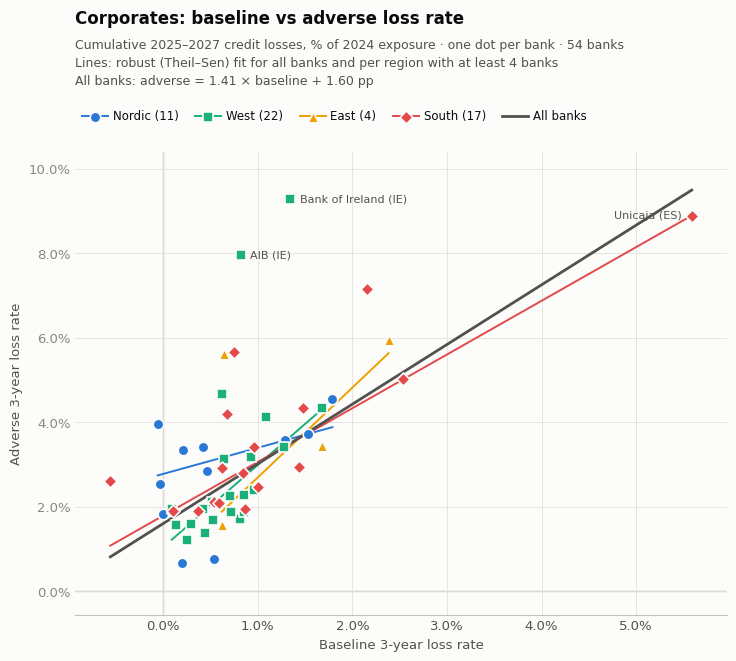

Region,Country,Bank,Bank 2024 exposure,Portfolio 2024 exposure,Baseline 3Y loss rate,Adverse 3Y loss rate
West,IE,Bank of Ireland Group plc,"122,788","21,494",1.35%,9.28%
South,ES,"Unicaja Banco, S.A.","63,949","6,219",5.59%,8.89%
West,IE,AIB Group plc,"119,586","23,437",0.82%,7.95%
South,IT,BANCA MONTE DEI PASCHI DI SIENA S.p.A.,"106,195","25,551",2.15%,7.15%
East,RO,Banca Transilvania,"34,742","4,015",2.38%,5.95%
South,PT,"Banco Comercial Português, SA","88,827","13,325",0.75%,5.67%
East,HU,OTP Bank Nyrt.,"110,082","22,039",0.65%,5.63%
South,ES,"Banco Bilbao Vizcaya Argentaria, S.A.","654,120","224,338",2.54%,5.02%
West,AT,Erste Group Bank AG,"333,919","117,442",0.62%,4.67%
Nordic,DK,Jyske Bank A/S,"94,482","34,482",1.79%,4.55%


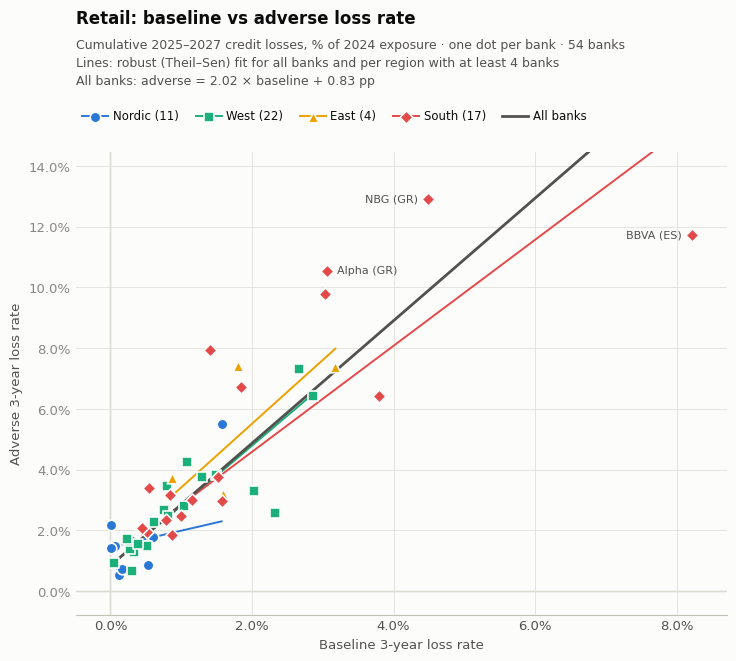

Region,Country,Bank,Bank 2024 exposure,Portfolio 2024 exposure,Baseline 3Y loss rate,Adverse 3Y loss rate
South,GR,National Bank of Greece S.A.,"67,984","3,150",4.48%,12.91%
South,ES,"Banco Bilbao Vizcaya Argentaria, S.A.","654,120","179,058",8.21%,11.74%
South,GR,ALPHA SERVICES & HOLDINGS S.A.,"64,654","3,747",3.06%,10.55%
South,PT,"Caixa Geral de Depósitos, SA","99,610","6,218",3.03%,9.78%
South,GR,PIRAEUS FINANCIAL HOLDINGS S.A.,"68,905","3,355",1.41%,7.93%
East,HU,OTP Bank Nyrt.,"110,082","20,784",1.80%,7.40%
East,PL,Powszechna Kasa Oszczednosci Bank Polski S.A.,"72,364","19,094",3.18%,7.38%
West,AT,Raiffeisen Bank International AG,"178,261","36,550",2.66%,7.30%
South,IT,ICCREA Banca S.p.A. – Istituto Centrale del Credito Cooperativo,"154,182","15,892",1.84%,6.73%
South,ES,"Banco Santander, S.A.","1,483,792","543,272",3.79%,6.42%


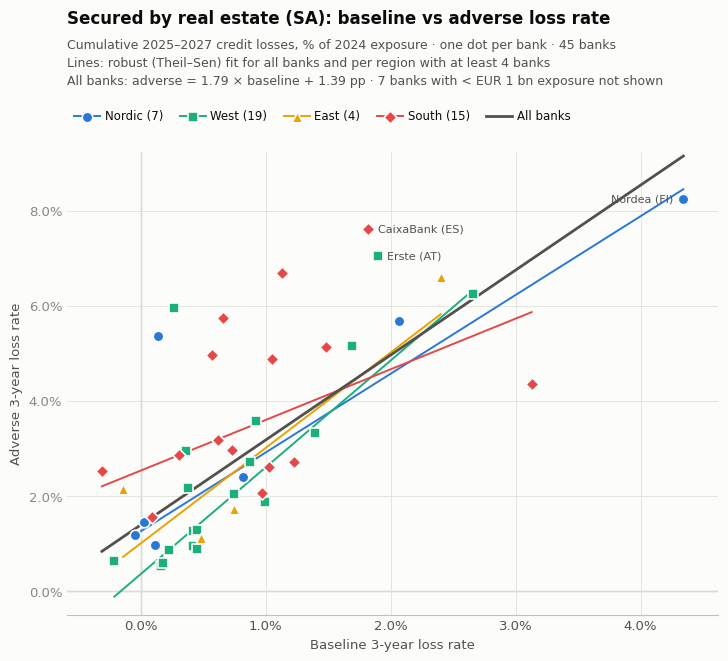

Region,Country,Bank,Bank 2024 exposure,Portfolio 2024 exposure,Baseline 3Y loss rate,Adverse 3Y loss rate
Nordic,FI,Nordea Bank Abp,"369,062","10,866",4.34%,8.24%
South,ES,"CaixaBank, S.A.","528,425","4,326",1.82%,7.62%
West,AT,Erste Group Bank AG,"333,919","11,805",1.90%,7.05%
South,IT,BPER Banca S.p.A.,"133,475","5,773",1.13%,6.70%
East,RO,Banca Transilvania,"34,742","8,741",2.40%,6.60%
West,BE,Belfius Banque SA,"177,819","1,464",2.66%,6.25%
West,IE,AIB Group plc,"119,586","27,121",0.27%,5.96%
South,GR,National Bank of Greece S.A.,"67,984","12,386",0.66%,5.73%
Nordic,DK,Jyske Bank A/S,"94,482","2,958",2.07%,5.68%
Nordic,DK,Danske Bank A/S,"265,991","10,635",0.14%,5.36%


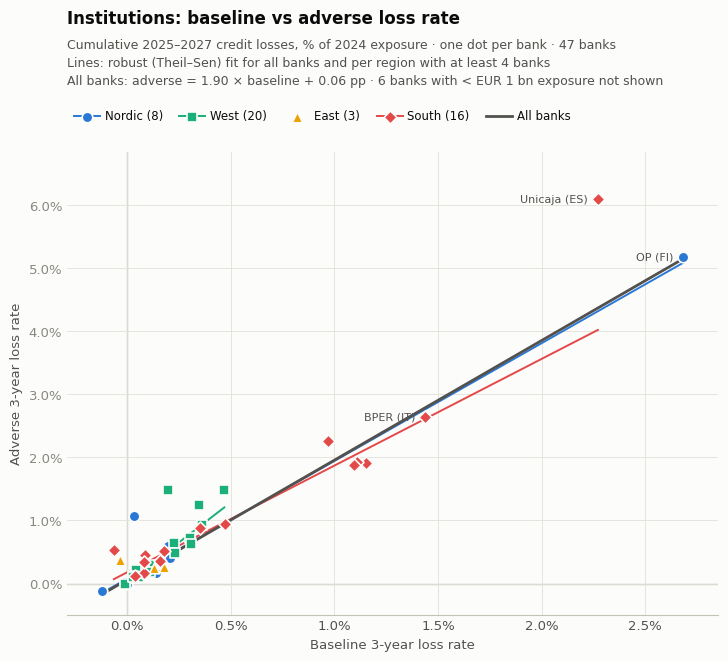

Region,Country,Bank,Bank 2024 exposure,Portfolio 2024 exposure,Baseline 3Y loss rate,Adverse 3Y loss rate
South,ES,"Unicaja Banco, S.A.","63,949","1,719",2.27%,6.09%
Nordic,FI,OP Osuuskunta,"154,692","1,918",2.68%,5.18%
South,IT,BPER Banca S.p.A.,"133,475","3,882",1.44%,2.64%
South,IT,ICCREA Banca S.p.A. – Istituto Centrale del Credito Cooperativo,"154,182","3,812",0.97%,2.25%
South,ES,"Banco Bilbao Vizcaya Argentaria, S.A.","654,120","35,655",1.11%,1.92%
South,IT,Banco BPM S.p.A.,"158,200","8,288",1.15%,1.92%
South,ES,"Banco de Sabadell, S.A.","223,159","2,328",1.09%,1.88%
West,AT,Erste Group Bank AG,"333,919","8,468",0.20%,1.48%
West,DE,Deutsche Bank AG,"822,329","12,966",0.47%,1.48%
West,FR,BNP Paribas S.A.,"1,565,771","41,359",0.35%,1.25%


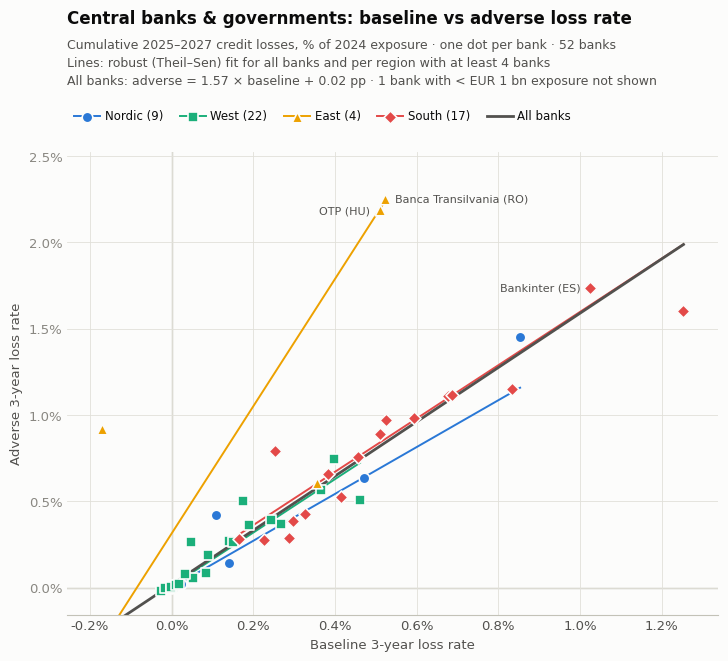

Region,Country,Bank,Bank 2024 exposure,Portfolio 2024 exposure,Baseline 3Y loss rate,Adverse 3Y loss rate
East,RO,Banca Transilvania,"34,742","11,801",0.52%,2.25%
East,HU,OTP Bank Nyrt.,"110,082","38,890",0.51%,2.18%
South,ES,"Bankinter, S.A.","117,624","31,312",1.02%,1.74%
South,IT,BANCA MONTE DEI PASCHI DI SIENA S.p.A.,"106,195","33,632",1.25%,1.60%
Nordic,FI,OP Osuuskunta,"154,692","20,410",0.85%,1.45%
South,IT,Banco BPM S.p.A.,"158,200","54,293",0.83%,1.15%
South,IT,ICCREA Banca S.p.A. – Istituto Centrale del Credito Cooperativo,"154,182","65,938",0.69%,1.12%
South,GR,National Bank of Greece S.A.,"67,984","25,434",0.68%,1.11%
South,IT,BPER Banca S.p.A.,"133,475","32,363",0.59%,0.98%
South,PT,"Banco Comercial Português, SA","88,827","28,578",0.53%,0.97%


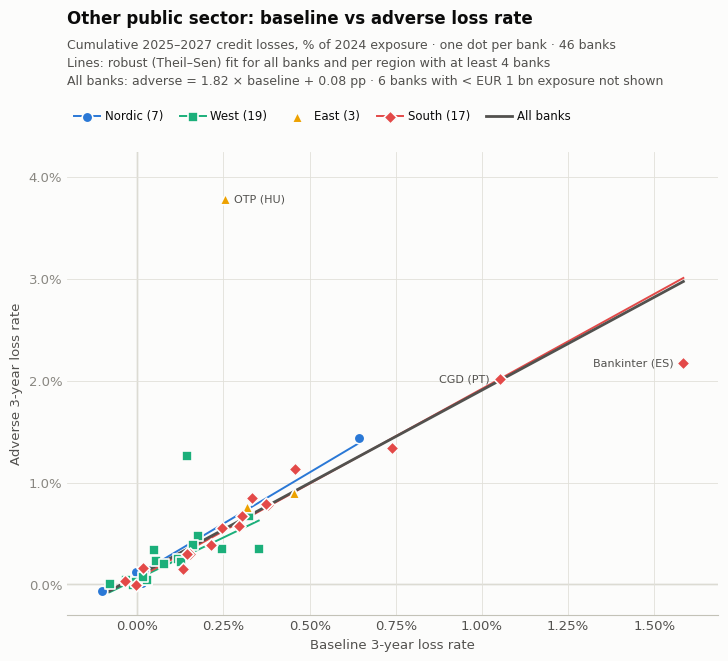

Region,Country,Bank,Bank 2024 exposure,Portfolio 2024 exposure,Baseline 3Y loss rate,Adverse 3Y loss rate
East,HU,OTP Bank Nyrt.,"110,082","2,147",0.25%,3.78%
South,ES,"Bankinter, S.A.","117,624","1,792",1.58%,2.18%
South,PT,"Caixa Geral de Depósitos, SA","99,610","6,114",1.05%,2.02%
Nordic,FI,OP Osuuskunta,"154,692","5,377",0.64%,1.44%
South,IT,BANCA MONTE DEI PASCHI DI SIENA S.p.A.,"106,195","1,243",0.74%,1.34%
West,DE,Deutsche Bank AG,"822,329","1,574",0.14%,1.26%
South,IT,Banco BPM S.p.A.,"158,200","1,755",0.46%,1.14%
East,PL,Bank Polska Kasa Opieki S.A.,"79,718","5,018",0.46%,0.90%
South,ES,"Banco Bilbao Vizcaya Argentaria, S.A.","654,120","6,476",0.33%,0.85%
South,IT,ICCREA Banca S.p.A. – Istituto Centrale del Credito Cooperativo,"154,182","1,304",0.37%,0.79%


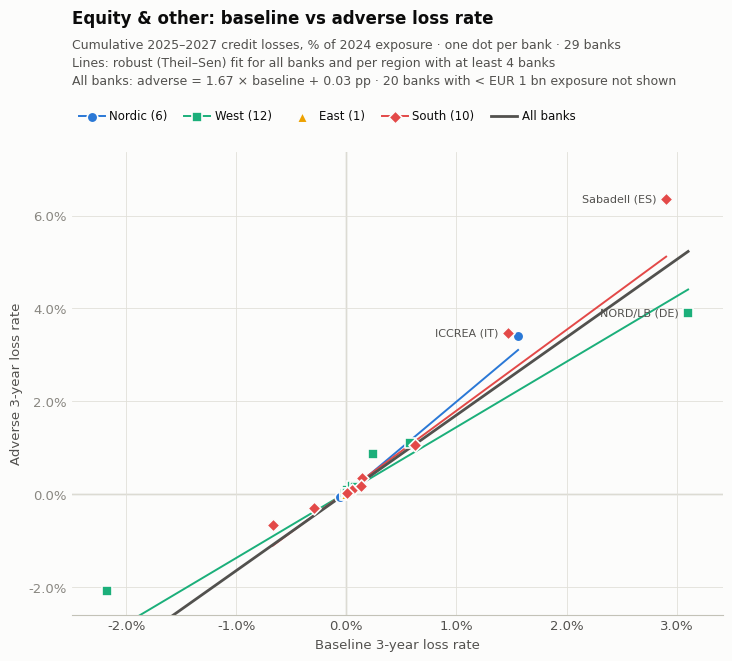

Region,Country,Bank,Bank 2024 exposure,Portfolio 2024 exposure,Baseline 3Y loss rate,Adverse 3Y loss rate
South,ES,"Banco de Sabadell, S.A.","223,159","1,910",2.90%,6.35%
West,DE,Norddeutsche Landesbank -Girozentrale-,"118,143","1,006",3.10%,3.90%
South,IT,ICCREA Banca S.p.A. – Istituto Centrale del Credito Cooperativo,"154,182","1,386",1.47%,3.46%
Nordic,FI,OP Osuuskunta,"154,692","8,453",1.56%,3.41%
West,DE,DZ Bank AG Deutsche Zentral-Genossenschaftsbank,"474,460","1,975",0.58%,1.11%
South,ES,"Banco Santander, S.A.","1,483,792","72,717",0.62%,1.07%
West,FR,Groupe Crédit Agricole,"1,881,530","45,393",0.25%,0.87%
South,IT,UniCredit S.p.A.,"662,381","17,819",0.14%,0.35%
Nordic,SE,Swedbank — group,"216,369","3,090",0.10%,0.20%
South,IT,BPER Banca S.p.A.,"133,475","8,880",0.13%,0.18%


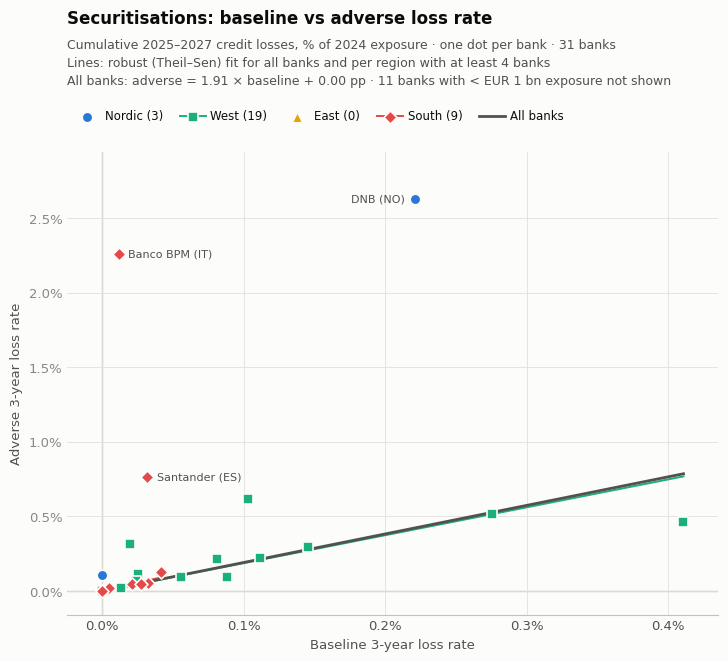

Region,Country,Bank,Bank 2024 exposure,Portfolio 2024 exposure,Baseline 3Y loss rate,Adverse 3Y loss rate
Nordic,NO,DNB BANK ASA,"250,903","1,332",0.22%,2.63%
South,IT,Banco BPM S.p.A.,"158,200","8,488",0.01%,2.26%
South,ES,"Banco Santander, S.A.","1,483,792","99,654",0.03%,0.76%
West,DE,Deutsche Bank AG,"822,329","91,322",0.10%,0.62%
West,IE,AIB Group plc,"119,586","3,107",0.28%,0.52%
West,DE,COMMERZBANK Aktiengesellschaft,"413,890","27,732",0.41%,0.46%
West,DE,Landesbank Hessen-Thüringen Girozentrale,"190,882","12,172",0.02%,0.32%
West,DE,Norddeutsche Landesbank -Girozentrale-,"118,143","2,101",0.15%,0.29%
West,FR,La Banque Postale,"286,177","2,031",0.11%,0.22%
West,NL,ING Groep N.V.,"969,539","18,143",0.08%,0.21%


In [8]:
REGION_OF_COUNTRY = {
    'DK': 'N', 'FI': 'N', 'NO': 'N', 'SE': 'N',
    'AT': 'W', 'BE': 'W', 'DE': 'W', 'FR': 'W', 'IE': 'W', 'NL': 'W',
    'HU': 'E', 'PL': 'E', 'RO': 'E',
    'ES': 'S', 'GR': 'S', 'IT': 'S', 'PT': 'S',
}
REGION_NAME = {'N': 'Nordic', 'W': 'West', 'E': 'East', 'S': 'South'}
# Colour + marker per region. The four hues pass the all-pairs palette check for scatters,
# but one pair sits in the colour-vision-deficiency floor band, so the marker shape is a
# second encoding that keeps the regions apart without relying on colour.
REGION_STYLE = {'N': ('#2a78d6', 'o'), 'W': ('#1baf7a', 's'), 'E': ('#eda100', '^'), 'S': ('#e34948', 'D')}
REGION_GROUPS = {code: (REGION_NAME[code], color, marker, 44 if marker == 'D' else 58)  # chart spec per group
                 for code, (color, marker) in REGION_STYLE.items()}
EDGE_CASES = {  # Not regular lending banks: excluded from the scatters.
    '6TJCK1B7E7UTXP528Y04': 'Investment bank / broker-dealer (EU hub of a US group)',
    '8IBZUGJ7JPLH368JE346': 'Investment bank / broker-dealer (EU hub of a US group)',
    '549300ZK53CNGEEI6A29': 'Investment bank / broker-dealer (EU hub of a US group)',
    '549300C9KPZR0VZ16R05': 'Investment bank / broker-dealer (EU hub of a US group)',
    '549300FH0WJAPEHTIQ77': 'Investment bank / broker-dealer (EU hub of a US group)',
    'EQYXK86SF381Q21S3020': 'Wholesale bank (EU hub of a US/UK group)',
    'N1FBEDJ5J41VKZLO2475': 'Wholesale bank (EU hub of a US/UK group)',
    '2G5BKIC2CB69PRJH1W31': 'Wholesale bank (EU hub of a US/UK group)',
    'F0HUI1NY1AZMJMD8LP67': 'Wholesale bank (EU hub of a US/UK group)',
    '529900SSGT49ZZSWYE62': 'Captive car-finance company',
}
MIN_PORTFOLIO_EXPOSURE = 1_000  # EUR m; a bank's portfolio below this is left out of that chart.
MIN_GROUP_FIT = 4  # banks; a region or size group with fewer banks in a chart gets no line of its own.
SHORT_NAME = {  # Chart labels.
    'PQOH26KWDF7CG10L6792': 'Erste', '9ZHRYM6F437SQJ6OUG95': 'RBI', 'A5GWLFH3KM7YV2SFQL84': 'Belfius',
    '213800X3Q9LSAKRUWY91': 'KBC', 'VDYMYTQGZZ6DU0912C88': 'BayernLB', '851WYGNLUQLFZBSYGB56': 'Commerzbank',
    '6TJCK1B7E7UTXP528Y04': 'Citigroup GME', '529900HNOAA1KXQJUQ27': 'DZ Bank',
    '7LTWFZYICNSX8D621K86': 'Deutsche Bank', '8IBZUGJ7JPLH368JE346': 'Goldman Sachs BE',
    '549300ZK53CNGEEI6A29': 'J.P. Morgan SE', 'B81CK4ESI35472RHJ606': 'LBBW', 'DIZES5CFO5K3I5R58746': 'Helaba',
    '549300C9KPZR0VZ16R05': 'Morgan Stanley Europe', 'DSNHHQ2B9X5N6OUJ1236': 'NORD/LB',
    '529900SSGT49ZZSWYE62': 'VW Financial Services', 'MAES062Z21O4RZ2U7M96': 'Danske Bank',
    '3M5E1GQGKL17HI6CPN30': 'Jyske Bank', 'LIU16F6VZJSD6UKHD557': 'Nykredit', 'K8MS7FD7N5Z2WQ51AZ71': 'BBVA',
    '5493006QMFDDMYWIAM13': 'Santander', 'SI5RG2M0WQQLZCXKRM20': 'Sabadell', 'VWMYAEQSTOPNV0SUGU82': 'Bankinter',
    '7CUNS533WID6K7DGFI87': 'CaixaBank', '5493007SJLLCTM6J6M37': 'Unicaja', '529900ODI3047E2LIV03': 'Nordea',
    '7437003B5WFBOIEFY714': 'OP', 'R0MUWSFPU8MPRO8K5P83': 'BNP Paribas',
    '549300FH0WJAPEHTIQ77': 'BofA Securities Europe', '9695000CG7B84NLR5984': 'Crédit Mutuel',
    'FR9695005MSX1OYEMGDF': 'BPCE', 'FR969500TJ5KRTCJQWXH': 'Crédit Agricole',
    'F0HUI1NY1AZMJMD8LP67': 'HSBC Continental Europe', '96950066U5XAAIRCPA78': 'La Banque Postale',
    'O2RNE8IBXP4R0TD8PU41': 'Société Générale', '5299009N55YRQC69CN08': 'Alpha', '5UMCZOEYKCVFAW8ZLO05': 'NBG',
    'M6AD1Y1KW32H8THQ6F76': 'Piraeus', '529900W3MOO00A18X956': 'OTP', '635400AKJBGNS5WNQL34': 'AIB',
    'EQYXK86SF381Q21S3020': 'BofA Europe', '635400C8EK6DRI12LJ39': 'Bank of Ireland',
    '2G5BKIC2CB69PRJH1W31': 'Barclays Ireland', 'N1FBEDJ5J41VKZLO2475': 'Citibank Europe',
    'J4CP7MHCXR8DAQMKIL78': 'MPS', 'N747OI7JINV7RUUH6190': 'BPER', '815600E4E6DCD2D25E30': 'Banco BPM',
    'NNVPP80YIZGEY2314M97': 'ICCREA', '2W8N8UU78PMDQKZENC08': 'Intesa Sanpaolo',
    '549300TRUWO2CD2G5692': 'UniCredit', 'BFXS5XCH7N0Y05NIXW11': 'ABN AMRO', 'DG3RU1DBUFHT4ZF9WN62': 'Rabobank',
    '549300NYKK9MWM7GGW15': 'ING', '549300GKFG0RYRRQ1414': 'DNB', '5493000LKS7B3UTF7H35': 'Pekao',
    'P4GTT6GF1W40CVIMFR43': 'PKO BP', 'JU1U6S0DG9YLT7N8ZV32': 'BCP', 'TO822O0VT80V06K0FH57': 'CGD',
    '549300RG3H390KEL8896': 'Banca Transilvania', '549300C6TUMDXNOVXS82': 'Länsförsäkringar',
    'H0YX5LBGKDVOWCXBZ594': 'SBAB', 'F3JS33DEI6XQ4ZBPTN86': 'SEB', 'NHBDILHZTYCNBV5UYZ31': 'Handelsbanken',
    'M312WZV08Y7LYUC71685': 'Swedbank',
}

unmapped = sorted(set(banks['country_code']) - set(REGION_OF_COUNTRY))
if unmapped or not set(EDGE_CASES) <= set(LEIS) or set(SHORT_NAME) != set(LEIS):
    raise ValueError(f'Unmapped countries {unmapped}, or edge-case / short-name LEIs do not match the banks')


def rate_points():
    """One row per bank and portfolio: 2024 exposure, and 3Y losses and loss rates (%) per scenario, both for all
    credit losses and for losses on new defaults only (stage 3 provision build-up plus securitisation impairments)."""
    expo = exposure_2024.groupby(level=['lei_code', 'portfolio']).sum()
    defaults = losses.loc[losses.index.get_level_values('stage').isin([3, 0])]
    columns = {'exposure': expo}
    for suffix, frame in [('', losses), ('_defaults', defaults)]:
        by_port = frame.groupby(level=['lei_code', 'portfolio']).sum()
        for scenario in (BASELINE, ADVERSE):
            name = SCENARIO_NAME[scenario].lower()
            columns[f'{name}_3y{suffix}'] = by_port[scenario].sum(axis=1).reindex(expo.index)
    pts = pd.DataFrame(columns).reset_index()
    if pts.isna().any().any():
        raise ValueError('Losses and exposures do not cover the same bank/portfolio cells')
    pts = pts.join(banks, on='lei_code')
    pts['region'] = pts['country_code'].map(REGION_OF_COUNTRY)
    for suffix in ('', '_defaults'):
        for name in ('baseline', 'adverse'):
            pts[f'{name}_rate{suffix}'] = 100 * pts[f'{name}_3y{suffix}'] / pts['exposure'].where(pts['exposure'] > 0)
    pts['bank_exposure'] = pts['lei_code'].map(exposure_2024.groupby(level='lei_code').sum())
    pts['edge_case'] = pts['lei_code'].isin(EDGE_CASES)
    pts['small'] = pts['exposure'] < MIN_PORTFOLIO_EXPOSURE
    return pts


def chart_points(portfolio):
    """Banks shown in one portfolio's chart, and how many were left out for a small exposure."""
    cells = rate_points_all.loc[(rate_points_all['portfolio'] == portfolio) & ~rate_points_all['edge_case']
                                & (rate_points_all['exposure'] > 0)]
    return cells.loc[~cells['small']], int(cells['small'].sum())


def pct_axis(axis):
    """Percent tick labels with as many decimals as the ticks need (at least one) and no '-0.0%'."""
    ticks = axis.get_majorticklocs()
    decimals = next(d for d in (1, 2, 3, 4) if np.allclose(ticks, np.round(ticks, d), rtol=0, atol=1e-9))
    axis.set_major_formatter(FuncFormatter(lambda v, _: f'{0.0 if abs(v) < 1e-9 else v:,.{decimals}f}%'))


def theil_sen(x, y):
    """Robust line fit: slope = median of all pairwise slopes, intercept = median residual
    (scipy.stats.theilslopes with method='joint'). Resistant to a few extreme banks."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    i, j = np.triu_indices(len(x), k=1)
    dx = x[j] - x[i]
    keep = dx != 0
    slope = np.median((y[j] - y[i])[keep] / dx[keep])
    return slope, np.median(y - slope * x)


def rate_scatter(portfolio, shown, n_small, group_col, groups, group_noun, all_banks_line=True):
    """Baseline (x) vs adverse (y) 3Y loss rate, one dot per bank, coloured by group_col using groups
    ({code: (name, colour, marker, marker area)}), with a robust regression line for each group with at least
    MIN_GROUP_FIT banks and, if all_banks_line, one for all banks (grey)."""
    fig, ax = plt.subplots(figsize=(7.4, 6.8))
    handles, labels = [], []
    for code, (name, color, marker, area) in groups.items():
        sub = shown.loc[shown[group_col] == code]
        handle = ax.scatter(sub['baseline_rate'], sub['adverse_rate'], s=area, color=color, marker=marker,
                            edgecolors=SURFACE, linewidths=1.2, zorder=3)
        if len(sub) >= MIN_GROUP_FIT:  # drawn over the group's own range of baseline rates
            slope_r, add_on_r = theil_sen(sub['baseline_rate'], sub['adverse_rate'])
            ends = np.array([sub['baseline_rate'].min(), sub['baseline_rate'].max()])
            handle = (ax.plot(ends, add_on_r + slope_r * ends, color=color, linewidth=1.4, zorder=2)[0], handle)
        handles.append(handle)
        labels.append(f'{name} ({len(sub)})')
    x, y = shown['baseline_rate'], shown['adverse_rate']
    pad_x, pad_y = .06 * (x.max() - min(x.min(), 0)), .06 * (y.max() - min(y.min(), 0))
    ax.set_xlim(min(x.min(), 0) - pad_x, x.max() + pad_x)
    ax.set_ylim(min(y.min(), 0) - pad_y, y.max() + 2 * pad_y)
    slope, add_on = theil_sen(x, y)
    if all_banks_line:
        ends = np.array([x.min(), x.max()])
        handles += ax.plot(ends, add_on + slope * ends, color=INK_2, linewidth=2, zorder=2.5)
        labels.append('All banks')
    ax.axhline(0, color=AXIS, linewidth=1, zorder=1)
    ax.axvline(0, color=AXIS, linewidth=1, zorder=1)
    ax.grid(color=GRID, linewidth=.6, zorder=0)
    ax.tick_params(axis='both', length=0)
    pct_axis(ax.xaxis)
    pct_axis(ax.yaxis)
    ax.set_xlabel('Baseline 3-year loss rate')
    ax.set_ylabel('Adverse 3-year loss rate')
    fig.subplots_adjust(left=.1, right=.98, bottom=.085, top=.765)
    # Label only the three banks with the highest adverse loss rate; a label that would overlap
    # an earlier one or leave the plot goes to the other side of its dot.
    renderer, frame, placed = fig.canvas.get_renderer(), ax.get_window_extent(), []
    xmid = sum(ax.get_xlim()) / 2
    for row in shown.nlargest(3, 'adverse_rate').itertuples():
        first = row.baseline_rate < xmid
        for attempt, right in enumerate((first, not first)):
            label = ax.annotate(f'{SHORT_NAME[row.lei_code]} ({row.country_code})',
                                (row.baseline_rate, row.adverse_rate), xytext=(7 if right else -7, 0),
                                textcoords='offset points', ha='left' if right else 'right', va='center',
                                fontsize=8, color=INK_2)
            box = label.get_window_extent(renderer).padded(4)
            fits = frame.x0 <= box.x0 and box.x1 <= frame.x1 and not any(box.overlaps(b) for b in placed)
            if fits or attempt == 1:
                break
            label.remove()
        placed.append(box)
    sign = '+' if add_on >= 0 else '−'
    fitted = f'all banks and per {group_noun}' if all_banks_line else f'each {group_noun}'
    notes = [f'All banks: adverse = {slope:,.2f} × baseline {sign} {abs(add_on):,.2f} pp'] if all_banks_line else []
    if n_small:
        noun = 'bank' if n_small == 1 else 'banks'
        notes.append(f'{n_small} {noun} with < EUR {MIN_PORTFOLIO_EXPOSURE / 1000:,.0f} bn exposure not shown')
    subtitle = [f'Cumulative 2025–2027 credit losses, % of 2024 exposure · one dot per bank · {len(shown)} banks',
                f'Lines: robust (Theil–Sen) fit for {fitted} with at least {MIN_GROUP_FIT} banks', ' · '.join(notes)]
    fig.suptitle(f'{portfolio}: baseline vs adverse loss rate', x=.1, y=.975, ha='left', va='top',
                 fontsize=12, fontweight='bold')
    fig.text(.1, .932, '\n'.join(subtitle), ha='left', va='top', fontsize=9, color=INK_2, linespacing=1.5)
    fig.legend(handles=handles, labels=labels, loc='upper left', bbox_to_anchor=(.095, .843), ncol=5,
               frameon=False, fontsize=8.5, handletextpad=.4, handlelength=2.2, columnspacing=1.4)
    return fig


def chart_table(portfolio, shown, group_title, group_col, group_names):
    """Collapsible table of the banks in one chart, highest adverse loss rate first."""
    table = shown.sort_values('adverse_rate', ascending=False)
    table = pd.DataFrame({group_title: table[group_col].map(group_names), 'Country': table['country_code'],
                          'Bank': table['bank_name'], 'Bank 2024 exposure': table['bank_exposure'],
                          'Portfolio 2024 exposure': table['exposure'],
                          'Baseline 3Y loss rate': table['baseline_rate'],
                          'Adverse 3Y loss rate': table['adverse_rate']})
    return (f'<details class="cl-details"><summary>{html.escape(portfolio)}: data behind the chart</summary>'
            + table_html(table.reset_index(drop=True), ['text'] * 3 + ['int', 'int', 'pct', 'pct']) + '</details>')


rate_points_all = rate_points()
edge = banks.loc[list(EDGE_CASES)].assign(reason=pd.Series(EDGE_CASES))
display(HTML(table_html(edge[['country_code', 'bank_name', 'reason']].set_axis(['Country', 'Bank', 'Reason'], axis=1)
                        .reset_index(drop=True), ['text'] * 3,
                        caption=f'Excluded from the scatters: {len(edge)} edge-case banks')))
for portfolio in PORTFOLIOS:
    shown, n_small = chart_points(portfolio)
    rate_scatter(portfolio, shown, n_small, 'region', REGION_GROUPS, 'region')
    plt.show()
    display(HTML(chart_table(portfolio, shown, 'Region', 'region', REGION_NAME)))


### Rules of thumb

Each chart's robust line can be read as a rule of thumb: *adverse ≈ slope × baseline + add-on*, with both loss
rates in % of 2024 exposure. The table gives that rule per portfolio for all banks (bold) and for each region with
at least four banks in the chart, the adverse/baseline multiplier it implies for a bank at the 25th, 50th and 75th
percentile of baseline loss rates, and how far the rule misses: half the banks lie closer to it than the stated
distance. Regional rules rest on few banks; where they differ from the all-bank rule by less than the miss
distance, the all-bank rule is the safer one to use.

A single multiplier (*adverse ≈ a × baseline*) only works where the add-on is close to zero, which shows as a
multiplier that hardly changes across the three percentiles. With **all credit losses** that fails for corporates,
retail and real estate: the baseline includes the 2025 release of provisions on performing loans (see the note
above the charts), so banks with near-zero baseline losses still have sizeable adverse losses. Measured on
**losses on new defaults** (the build-up of stage 3 provisions, which the methodology does not allow to fall, plus
securitisation impairments), the relationship is much closer to proportional.

The rules are cross-sectional: they describe how baseline and adverse loss rates line up across the banks in this
exercise, under its country-specific scenarios. They are a benchmark, not a model of how one bank's losses would
respond to a different scenario.

In [9]:
RULE_MEASURES = {  # column group -> (baseline column, adverse column) in rate_points_all
    'All credit losses (as charted)': ('baseline_rate', 'adverse_rate'),
    'Losses on new defaults (stage 3)': ('baseline_rate_defaults', 'adverse_rate_defaults'),
}


def rule_of_thumb(x, y):
    """Robust rule adverse ≈ slope × baseline + add-on; the adverse/baseline multiplier it implies for the 25th,
    50th and 75th percentile bank (NaN where that baseline is below 0.05%); and the median absolute miss."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    slope, add_on = theil_sen(x, y)
    multipliers = [(add_on + slope * v) / v if v >= 0.05 else np.nan for v in np.percentile(x, [25, 50, 75])]
    return slope, add_on, multipliers, np.median(np.abs(y - (add_on + slope * x)))


def rules_table(group_col, group_names, group_title, caption):
    """Show and return the rules of thumb per portfolio: a row for all banks (bold), then one per group;
    a group with fewer than MIN_GROUP_FIT banks in the chart gets no rule."""
    rows, classes = [], []
    for portfolio in PORTFOLIOS:
        shown, _ = chart_points(portfolio)
        for code, label in [(None, 'All banks')] + list(group_names.items()):
            sub = shown if code is None else shown.loc[shown[group_col] == code]
            row = {'Portfolio': portfolio if code is None else '', group_title: label, 'Banks': len(sub)}
            for group, (base_col, adv_col) in RULE_MEASURES.items():
                keys = [f'{group}|Adverse ≈', f'{group}|Multiplier at 25th / 50th / 75th pct',
                        f'{group}|Half of banks within']
                if len(sub) < MIN_GROUP_FIT:
                    row.update(dict.fromkeys(keys, '–'))
                    continue
                slope, add_on, multipliers, miss = rule_of_thumb(sub[base_col], sub[adv_col])
                sign = '+' if add_on >= 0 else '−'
                row.update(zip(keys, [f'{slope:,.2f} × baseline {sign} {abs(add_on):,.2f} pp',
                                      ' / '.join('–' if np.isnan(m) else f'{m:,.1f}×' for m in multipliers),
                                      f'±{miss:,.2f} pp']))
            rows.append(row)
            classes.append('total' if code is None else '')
    table = pd.DataFrame(rows)
    table.columns = [c.split('|')[-1] for c in table.columns]
    display(HTML(table_html(table, ['text', 'text', 'int'] + ['text'] * 6,
                            groups=[('', 3)] + [(group, 3) for group in RULE_MEASURES], row_class=classes,
                            caption=caption)))
    return table


rules = rules_table('region', REGION_NAME, 'Region',
                    'Rules of thumb by region: adverse 3-year loss rate from the baseline 3-year loss rate '
                    f'(% of 2024 exposure; a region needs at least {MIN_GROUP_FIT} banks)')


## 6. Baseline vs adverse loss rates by bank size

The same charts as in section 5, with banks grouped by size instead of region. Size is the bank's total restated
end-2024 credit exposure across all portfolios (IRB and SA exposures plus securitisation exposure), split at
EUR 150 bn and EUR 500 bn (`SIZE_BREAKS`). Each size group has its own colour, marker and robust (Theil–Sen)
regression line, drawn over that group's range of baseline rates. There is no all-bank line here, so the three
group lines can be compared directly. Edge-case banks and small portfolios are left out as in section 5.

Size is the whole bank's credit exposure, not the size of the portfolio in the chart: a large bank can hold a
small book in one portfolio.

Size groups, edge cases excluded: **Small < EUR 150 bn**: 19 banks; **Mid EUR 150–500 bn**: 22 banks; **Large ≥ EUR 500 bn**: 13 banks.

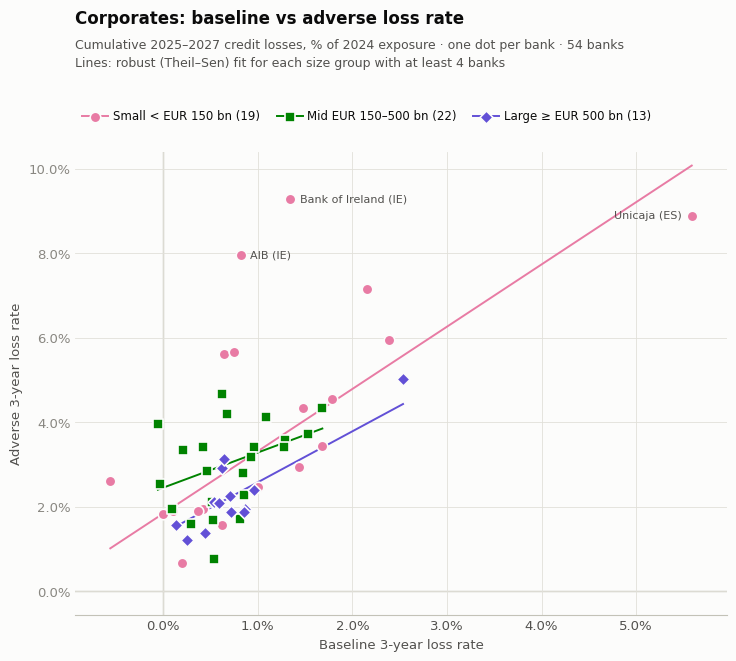

Size group,Country,Bank,Bank 2024 exposure,Portfolio 2024 exposure,Baseline 3Y loss rate,Adverse 3Y loss rate
Small < EUR 150 bn,IE,Bank of Ireland Group plc,"122,788","21,494",1.35%,9.28%
Small < EUR 150 bn,ES,"Unicaja Banco, S.A.","63,949","6,219",5.59%,8.89%
Small < EUR 150 bn,IE,AIB Group plc,"119,586","23,437",0.82%,7.95%
Small < EUR 150 bn,IT,BANCA MONTE DEI PASCHI DI SIENA S.p.A.,"106,195","25,551",2.15%,7.15%
Small < EUR 150 bn,RO,Banca Transilvania,"34,742","4,015",2.38%,5.95%
Small < EUR 150 bn,PT,"Banco Comercial Português, SA","88,827","13,325",0.75%,5.67%
Small < EUR 150 bn,HU,OTP Bank Nyrt.,"110,082","22,039",0.65%,5.63%
Large ≥ EUR 500 bn,ES,"Banco Bilbao Vizcaya Argentaria, S.A.","654,120","224,338",2.54%,5.02%
Mid EUR 150–500 bn,AT,Erste Group Bank AG,"333,919","117,442",0.62%,4.67%
Small < EUR 150 bn,DK,Jyske Bank A/S,"94,482","34,482",1.79%,4.55%


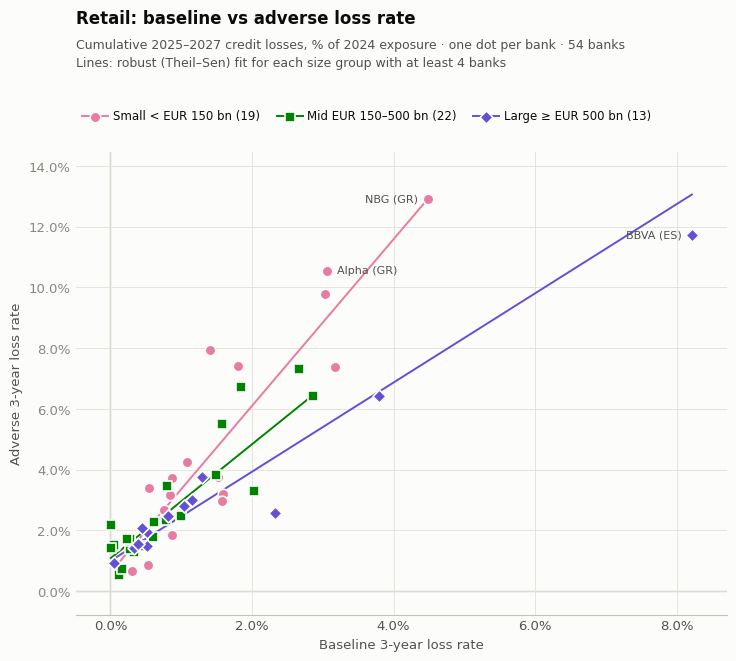

Size group,Country,Bank,Bank 2024 exposure,Portfolio 2024 exposure,Baseline 3Y loss rate,Adverse 3Y loss rate
Small < EUR 150 bn,GR,National Bank of Greece S.A.,"67,984","3,150",4.48%,12.91%
Large ≥ EUR 500 bn,ES,"Banco Bilbao Vizcaya Argentaria, S.A.","654,120","179,058",8.21%,11.74%
Small < EUR 150 bn,GR,ALPHA SERVICES & HOLDINGS S.A.,"64,654","3,747",3.06%,10.55%
Small < EUR 150 bn,PT,"Caixa Geral de Depósitos, SA","99,610","6,218",3.03%,9.78%
Small < EUR 150 bn,GR,PIRAEUS FINANCIAL HOLDINGS S.A.,"68,905","3,355",1.41%,7.93%
Small < EUR 150 bn,HU,OTP Bank Nyrt.,"110,082","20,784",1.80%,7.40%
Small < EUR 150 bn,PL,Powszechna Kasa Oszczednosci Bank Polski S.A.,"72,364","19,094",3.18%,7.38%
Mid EUR 150–500 bn,AT,Raiffeisen Bank International AG,"178,261","36,550",2.66%,7.30%
Mid EUR 150–500 bn,IT,ICCREA Banca S.p.A. – Istituto Centrale del Credito Cooperativo,"154,182","15,892",1.84%,6.73%
Large ≥ EUR 500 bn,ES,"Banco Santander, S.A.","1,483,792","543,272",3.79%,6.42%


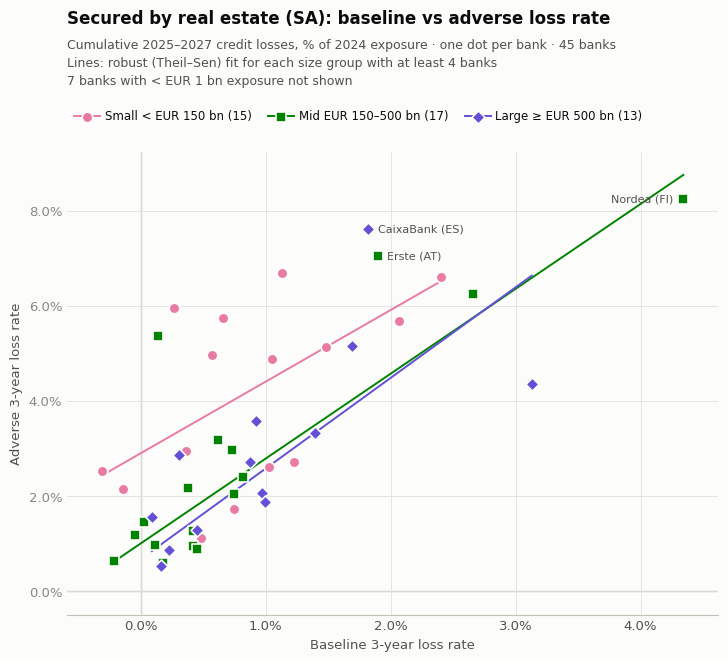

Size group,Country,Bank,Bank 2024 exposure,Portfolio 2024 exposure,Baseline 3Y loss rate,Adverse 3Y loss rate
Mid EUR 150–500 bn,FI,Nordea Bank Abp,"369,062","10,866",4.34%,8.24%
Large ≥ EUR 500 bn,ES,"CaixaBank, S.A.","528,425","4,326",1.82%,7.62%
Mid EUR 150–500 bn,AT,Erste Group Bank AG,"333,919","11,805",1.90%,7.05%
Small < EUR 150 bn,IT,BPER Banca S.p.A.,"133,475","5,773",1.13%,6.70%
Small < EUR 150 bn,RO,Banca Transilvania,"34,742","8,741",2.40%,6.60%
Mid EUR 150–500 bn,BE,Belfius Banque SA,"177,819","1,464",2.66%,6.25%
Small < EUR 150 bn,IE,AIB Group plc,"119,586","27,121",0.27%,5.96%
Small < EUR 150 bn,GR,National Bank of Greece S.A.,"67,984","12,386",0.66%,5.73%
Small < EUR 150 bn,DK,Jyske Bank A/S,"94,482","2,958",2.07%,5.68%
Mid EUR 150–500 bn,DK,Danske Bank A/S,"265,991","10,635",0.14%,5.36%


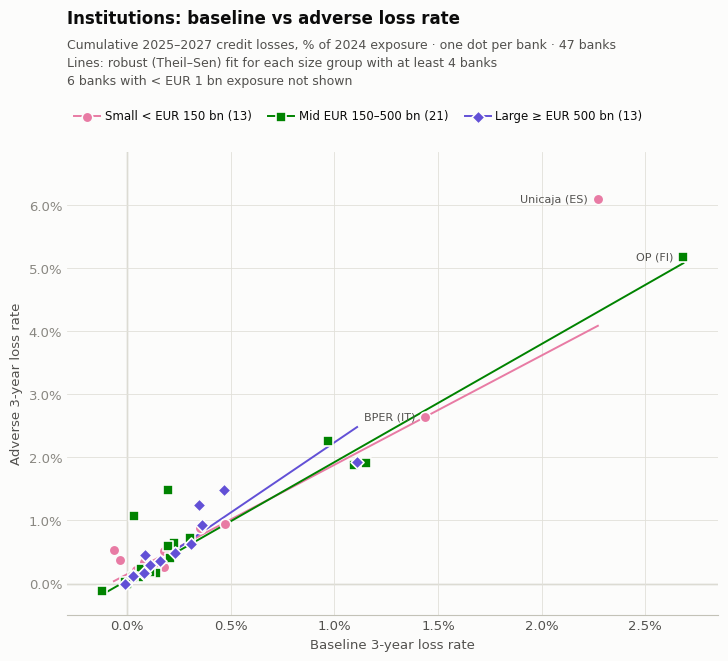

Size group,Country,Bank,Bank 2024 exposure,Portfolio 2024 exposure,Baseline 3Y loss rate,Adverse 3Y loss rate
Small < EUR 150 bn,ES,"Unicaja Banco, S.A.","63,949","1,719",2.27%,6.09%
Mid EUR 150–500 bn,FI,OP Osuuskunta,"154,692","1,918",2.68%,5.18%
Small < EUR 150 bn,IT,BPER Banca S.p.A.,"133,475","3,882",1.44%,2.64%
Mid EUR 150–500 bn,IT,ICCREA Banca S.p.A. – Istituto Centrale del Credito Cooperativo,"154,182","3,812",0.97%,2.25%
Large ≥ EUR 500 bn,ES,"Banco Bilbao Vizcaya Argentaria, S.A.","654,120","35,655",1.11%,1.92%
Mid EUR 150–500 bn,IT,Banco BPM S.p.A.,"158,200","8,288",1.15%,1.92%
Mid EUR 150–500 bn,ES,"Banco de Sabadell, S.A.","223,159","2,328",1.09%,1.88%
Mid EUR 150–500 bn,AT,Erste Group Bank AG,"333,919","8,468",0.20%,1.48%
Large ≥ EUR 500 bn,DE,Deutsche Bank AG,"822,329","12,966",0.47%,1.48%
Large ≥ EUR 500 bn,FR,BNP Paribas S.A.,"1,565,771","41,359",0.35%,1.25%


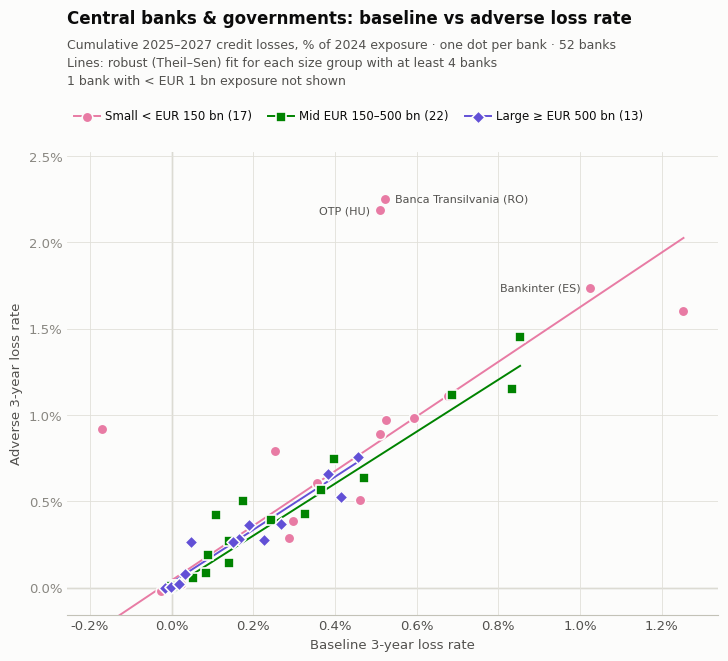

Size group,Country,Bank,Bank 2024 exposure,Portfolio 2024 exposure,Baseline 3Y loss rate,Adverse 3Y loss rate
Small < EUR 150 bn,RO,Banca Transilvania,"34,742","11,801",0.52%,2.25%
Small < EUR 150 bn,HU,OTP Bank Nyrt.,"110,082","38,890",0.51%,2.18%
Small < EUR 150 bn,ES,"Bankinter, S.A.","117,624","31,312",1.02%,1.74%
Small < EUR 150 bn,IT,BANCA MONTE DEI PASCHI DI SIENA S.p.A.,"106,195","33,632",1.25%,1.60%
Mid EUR 150–500 bn,FI,OP Osuuskunta,"154,692","20,410",0.85%,1.45%
Mid EUR 150–500 bn,IT,Banco BPM S.p.A.,"158,200","54,293",0.83%,1.15%
Mid EUR 150–500 bn,IT,ICCREA Banca S.p.A. – Istituto Centrale del Credito Cooperativo,"154,182","65,938",0.69%,1.12%
Small < EUR 150 bn,GR,National Bank of Greece S.A.,"67,984","25,434",0.68%,1.11%
Small < EUR 150 bn,IT,BPER Banca S.p.A.,"133,475","32,363",0.59%,0.98%
Small < EUR 150 bn,PT,"Banco Comercial Português, SA","88,827","28,578",0.53%,0.97%


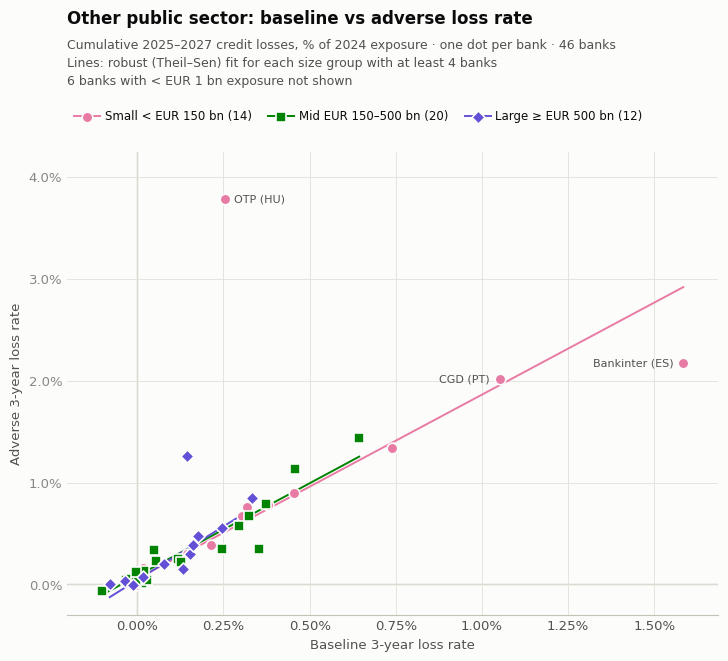

Size group,Country,Bank,Bank 2024 exposure,Portfolio 2024 exposure,Baseline 3Y loss rate,Adverse 3Y loss rate
Small < EUR 150 bn,HU,OTP Bank Nyrt.,"110,082","2,147",0.25%,3.78%
Small < EUR 150 bn,ES,"Bankinter, S.A.","117,624","1,792",1.58%,2.18%
Small < EUR 150 bn,PT,"Caixa Geral de Depósitos, SA","99,610","6,114",1.05%,2.02%
Mid EUR 150–500 bn,FI,OP Osuuskunta,"154,692","5,377",0.64%,1.44%
Small < EUR 150 bn,IT,BANCA MONTE DEI PASCHI DI SIENA S.p.A.,"106,195","1,243",0.74%,1.34%
Large ≥ EUR 500 bn,DE,Deutsche Bank AG,"822,329","1,574",0.14%,1.26%
Mid EUR 150–500 bn,IT,Banco BPM S.p.A.,"158,200","1,755",0.46%,1.14%
Small < EUR 150 bn,PL,Bank Polska Kasa Opieki S.A.,"79,718","5,018",0.46%,0.90%
Large ≥ EUR 500 bn,ES,"Banco Bilbao Vizcaya Argentaria, S.A.","654,120","6,476",0.33%,0.85%
Mid EUR 150–500 bn,IT,ICCREA Banca S.p.A. – Istituto Centrale del Credito Cooperativo,"154,182","1,304",0.37%,0.79%


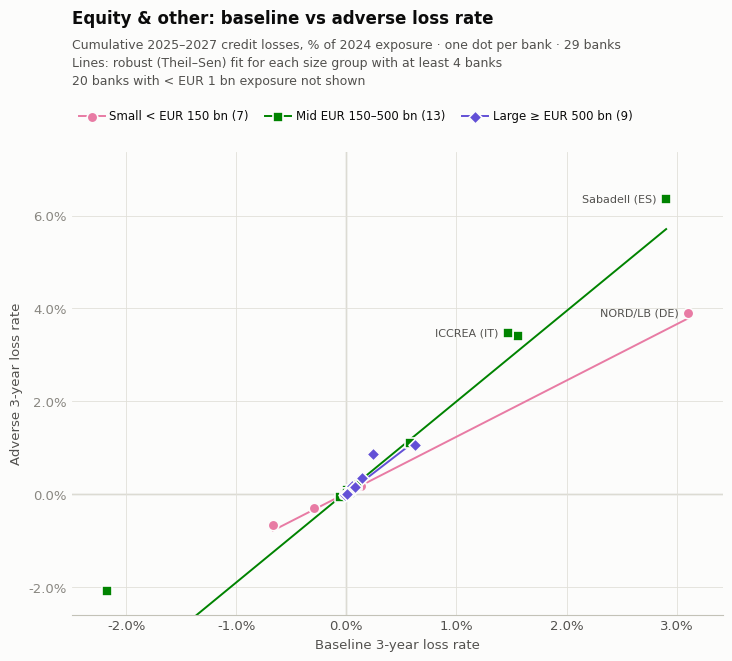

Size group,Country,Bank,Bank 2024 exposure,Portfolio 2024 exposure,Baseline 3Y loss rate,Adverse 3Y loss rate
Mid EUR 150–500 bn,ES,"Banco de Sabadell, S.A.","223,159","1,910",2.90%,6.35%
Small < EUR 150 bn,DE,Norddeutsche Landesbank -Girozentrale-,"118,143","1,006",3.10%,3.90%
Mid EUR 150–500 bn,IT,ICCREA Banca S.p.A. – Istituto Centrale del Credito Cooperativo,"154,182","1,386",1.47%,3.46%
Mid EUR 150–500 bn,FI,OP Osuuskunta,"154,692","8,453",1.56%,3.41%
Mid EUR 150–500 bn,DE,DZ Bank AG Deutsche Zentral-Genossenschaftsbank,"474,460","1,975",0.58%,1.11%
Large ≥ EUR 500 bn,ES,"Banco Santander, S.A.","1,483,792","72,717",0.62%,1.07%
Large ≥ EUR 500 bn,FR,Groupe Crédit Agricole,"1,881,530","45,393",0.25%,0.87%
Large ≥ EUR 500 bn,IT,UniCredit S.p.A.,"662,381","17,819",0.14%,0.35%
Mid EUR 150–500 bn,SE,Swedbank — group,"216,369","3,090",0.10%,0.20%
Small < EUR 150 bn,IT,BPER Banca S.p.A.,"133,475","8,880",0.13%,0.18%


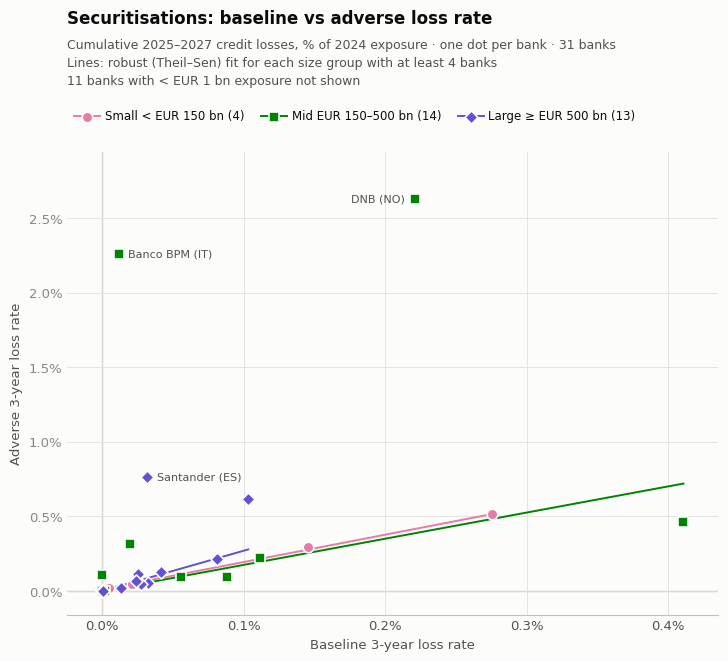

Size group,Country,Bank,Bank 2024 exposure,Portfolio 2024 exposure,Baseline 3Y loss rate,Adverse 3Y loss rate
Mid EUR 150–500 bn,NO,DNB BANK ASA,"250,903","1,332",0.22%,2.63%
Mid EUR 150–500 bn,IT,Banco BPM S.p.A.,"158,200","8,488",0.01%,2.26%
Large ≥ EUR 500 bn,ES,"Banco Santander, S.A.","1,483,792","99,654",0.03%,0.76%
Large ≥ EUR 500 bn,DE,Deutsche Bank AG,"822,329","91,322",0.10%,0.62%
Small < EUR 150 bn,IE,AIB Group plc,"119,586","3,107",0.28%,0.52%
Mid EUR 150–500 bn,DE,COMMERZBANK Aktiengesellschaft,"413,890","27,732",0.41%,0.46%
Mid EUR 150–500 bn,DE,Landesbank Hessen-Thüringen Girozentrale,"190,882","12,172",0.02%,0.32%
Small < EUR 150 bn,DE,Norddeutsche Landesbank -Girozentrale-,"118,143","2,101",0.15%,0.29%
Mid EUR 150–500 bn,FR,La Banque Postale,"286,177","2,031",0.11%,0.22%
Large ≥ EUR 500 bn,NL,ING Groep N.V.,"969,539","18,143",0.08%,0.21%


In [10]:
SIZE_BREAKS = (150_000, 500_000)  # EUR m of total 2024 credit exposure: small < 150 bn <= mid < 500 bn <= large
low, high = (b / 1000 for b in SIZE_BREAKS)
SIZE_NAME = {'S': f'Small < EUR {low:,.0f} bn', 'M': f'Mid EUR {low:,.0f}–{high:,.0f} bn',
             'L': f'Large ≥ EUR {high:,.0f} bn'}
# Three distinct hues, none used for the regions; they pass the all-pairs palette check for scatters.
SIZE_GROUPS = {code: (SIZE_NAME[code], color, marker, area)
               for code, color, marker, area in [('S', '#e87ba4', 'o', 58), ('M', '#008300', 's', 58),
                                                 ('L', '#6250d6', 'D', 44)]}

rate_points_all['size_group'] = np.select([rate_points_all['bank_exposure'] < SIZE_BREAKS[0],
                                           rate_points_all['bank_exposure'] < SIZE_BREAKS[1]], ['S', 'M'], 'L')
per_bank = rate_points_all.loc[~rate_points_all['edge_case']].drop_duplicates('lei_code')
counts = per_bank['size_group'].value_counts()
display(Markdown('Size groups, edge cases excluded: ' + '; '.join(
    f'**{SIZE_NAME[code]}**: {counts.get(code, 0)} banks' for code in SIZE_NAME) + '.'))
for portfolio in PORTFOLIOS:
    shown, n_small = chart_points(portfolio)
    rate_scatter(portfolio, shown, n_small, 'size_group', SIZE_GROUPS, 'size group', all_banks_line=False)
    plt.show()
    display(HTML(chart_table(portfolio, shown, 'Size group', 'size_group', SIZE_NAME)))


### Rules of thumb by bank size

Same layout and reading as the regional table in section 5: the rule for all banks (bold), then one rule per
size group.

In [11]:
size_rules = rules_table('size_group', SIZE_NAME, 'Size group',
                         'Rules of thumb by bank size: adverse 3-year loss rate from the baseline 3-year loss rate '
                         f'(% of 2024 exposure; a size group needs at least {MIN_GROUP_FIT} banks)')


## 7. Individual bank reports

Each report shows, for one bank: the annual credit losses in years 1–3 per portfolio for both scenarios,
the three-year totals and loss rates, the reconciliation memo to the P&L, a chart (left baseline, right
adverse, same scale; bars stacked by portfolio, releases stacked below zero), and an expandable
drill-down by approach and sub-segment and by IFRS 9 stage. Banks are in country/name order.

In [12]:
def bank_explanation(lei):
    port, expo = portfolio_view(lei)
    adv = port[ADVERSE].sum(axis=1)
    base = port[BASELINE].sum(axis=1)
    adv_total, base_total, exp_total = adv.sum(), base.sum(), expo.sum()
    years = port[ADVERSE].sum()
    parts = [f'Under the **adverse** scenario, credit losses total **EUR {adv_total:,.0f} m** over 2025–2027 '
             f'({100 * adv_total / exp_total:,.2f}% of 2024 exposure), against EUR {base_total:,.0f} m in the baseline.']
    if abs(adv_total) > 0.5:
        parts.append(f'Year 1 accounts for {100 * years[2025] / adv_total:,.0f}% of the adverse total '
                     f'(Y1 {years[2025]:,.0f}, Y2 {years[2026]:,.0f}, Y3 {years[2027]:,.0f}).')
        top = adv.sort_values(ascending=False)
        top = top[top > 0.5].head(2)
        if len(top):
            parts.append('Largest adverse contributors: ' + '; '.join(
                f'{p} EUR {v:,.0f} m ({100 * v / adv_total:,.0f}%, loss rate '
                f'{100 * v / expo[p] if expo[p] > 0.5 else float("nan"):,.2f}%)' for p, v in top.items()) + '.')
    gap = recon_max.loc[lei]
    if gap > RECON_TOL:
        parts.append(f'The credit-template total differs from the P&L impairment line by up to EUR {gap:,.1f} m '
                     'in a scenario-year (memo rows).')
    return ' '.join(parts)


def detail_html(lei):
    seg = losses.loc[lei].groupby(level=['approach', 'portfolio', 'segment']).sum()
    expo = exposure_2024.loc[lei]
    seg = seg.reindex(expo.index, fill_value=0.0)
    keep = (seg.abs().sum(axis=1) > 0.05) | (expo > 0.5)
    seg, expo = seg.loc[keep], expo.loc[keep]
    spec_rank = {(a, p, s): i for i, (a, p, s) in enumerate(zip(SEGMENTS['approach'], SEGMENTS['portfolio'],
                                                                 SEGMENTS['segment']))}
    order = sorted(seg.index, key=lambda k: (['IRB', 'SA', 'SEC'].index(k[0]), PORTFOLIOS.index(k[1]),
                                             spec_rank.get(k, 0)))
    seg, expo = seg.loc[order], expo.loc[order]
    rows = pd.DataFrame({'Approach': [k[0] for k in seg.index], 'Portfolio': [k[1] for k in seg.index],
                         'Segment': [k[2] for k in seg.index], '2024 exposure': expo.to_numpy()})
    for scenario in (BASELINE, ADVERSE):
        for key, value in scenario_block({y: seg[(scenario, y)].to_numpy() for y in YEARS}, expo.to_numpy()).items():
            rows[f'{SCENARIO_NAME[scenario]}|{key}'] = value
    rows.columns = [c.split('|')[-1] for c in rows.columns]
    seg_table = table_html(rows, ['text'] * 3 + ['int'] + (['num'] * 4 + ['pct']) * 2,
                           groups=[('', 4), ('Baseline', 5), ('Adverse', 5)],
                           caption='By approach and sub-segment (EUR m)')
    stage = losses.loc[lei].groupby(level='stage').sum().reindex([1, 2, 3, 0], fill_value=0.0)
    stage_rows = pd.DataFrame({'Component': ['Stage 1 provisions', 'Stage 2 provisions', 'Stage 3 provisions',
                                             'Securitisation impairments (no stage split)']})
    for scenario in (BASELINE, ADVERSE):
        for y in YEARS:
            stage_rows[f'{SCENARIO_NAME[scenario]} {YEAR_LABEL[y]}'] = stage[(scenario, y)].to_numpy()
        stage_rows[f'{SCENARIO_NAME[scenario]} 3Y'] = stage[scenario].sum(axis=1).to_numpy()
    total = {'Component': 'Total'} | {c: stage_rows[c].sum() for c in stage_rows.columns[1:]}
    stage_rows = pd.concat([stage_rows, pd.DataFrame([total])], ignore_index=True)
    stage_rows.columns = ['Component'] + ([YEAR_LABEL[y] for y in YEARS] + ['3Y total']) * 2
    stage_table = table_html(stage_rows, ['text'] + ['num'] * 8, groups=[('', 1), ('Baseline', 4), ('Adverse', 4)],
                             caption='By IFRS 9 stage (change in stage provision stock, EUR m)',
                             row_class=[''] * 4 + ['total'])
    note = ('<p class="cl-note">Stage figures are changes in each stage\'s provision stock, so migration between '
            'stages moves provisions from one row to another; only the total is a P&L flow.</p>')
    return ('<details class="cl-details"><summary>Drill-down: sub-segments and IFRS 9 stages</summary>'
            + seg_table + stage_table + note + '</details>')


report_count = 0

def report_bank(lei):
    global report_count
    info = banks.loc[lei]
    display(HTML(f'<div class="cl-bank" id="bank-{lei}"><h3>{html.escape(info["country_code"])} · '
                 f'{html.escape(info["bank_name"])}</h3><p class="cl-note">LEI {lei}</p></div>'))
    display(Markdown(bank_explanation(lei)))
    display(HTML(portfolio_table(lei, caption='Credit losses by portfolio (EUR m; positive = loss)')))
    port, _ = portfolio_view(lei)
    loss_chart(port, f'{info["bank_name"]} ({info["country_code"]})',
               'Annual credit losses by portfolio, EUR million · baseline vs adverse, same scale · positive = loss')
    plt.show()
    display(HTML(detail_html(lei)))
    report_count += 1


links = ''.join(f'<li><a href="#bank-{lei}">{html.escape(row["country_code"])} · {html.escape(row["bank_name"])}</a></li>'
                for lei, row in banks.iterrows())
display(HTML(f'<details><summary>Index of all {len(banks)} banks</summary><ul>{links}</ul></details>'))

Under the **adverse** scenario, credit losses total **EUR 10,512 m** over 2025–2027 (3.15% of 2024 exposure), against EUR 1,959 m in the baseline. Year 1 accounts for 40% of the adverse total (Y1 4,203, Y2 3,149, Y3 3,160). Largest adverse contributors: Corporates EUR 5,485 m (52%, loss rate 4.67%); Retail EUR 3,661 m (35%, loss rate 3.47%).

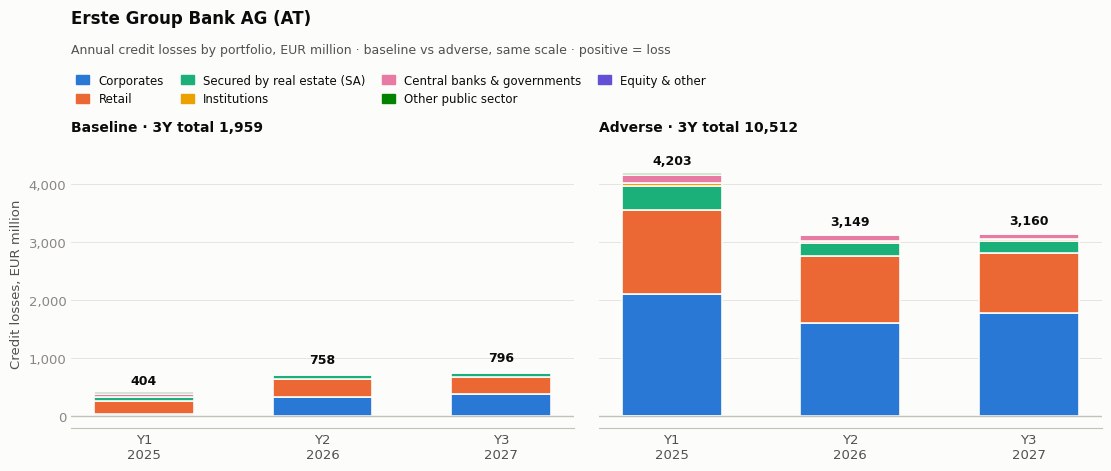

In [13]:
report_bank('PQOH26KWDF7CG10L6792')  # AT · Erste Group Bank AG

Under the **adverse** scenario, credit losses total **EUR 4,167 m** over 2025–2027 (2.34% of 2024 exposure), against EUR 1,407 m in the baseline. Year 1 accounts for 35% of the adverse total (Y1 1,449, Y2 834, Y3 1,885). Largest adverse contributors: Retail EUR 2,669 m (64%, loss rate 7.30%); Corporates EUR 955 m (23%, loss rate 1.58%).

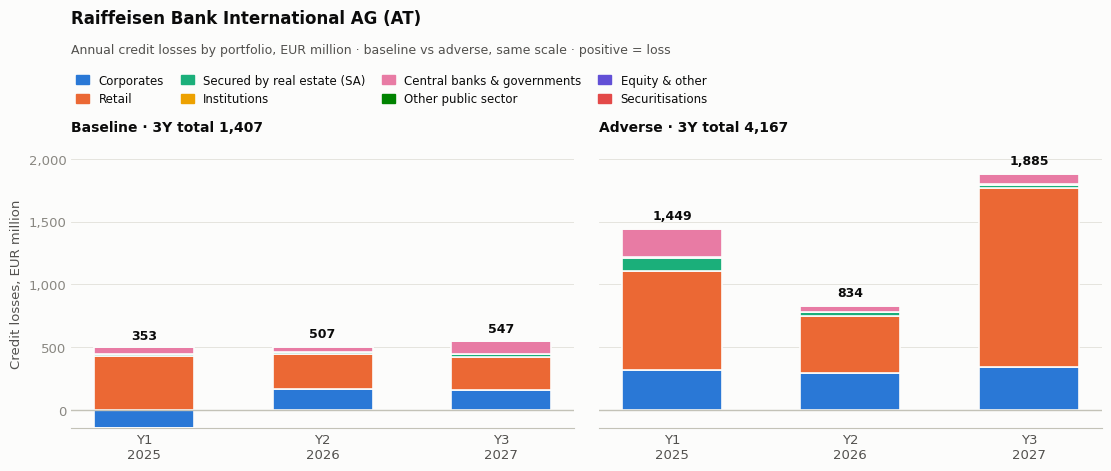

In [14]:
report_bank('9ZHRYM6F437SQJ6OUG95')  # AT · Raiffeisen Bank International AG

Under the **adverse** scenario, credit losses total **EUR 2,325 m** over 2025–2027 (1.31% of 2024 exposure), against EUR 746 m in the baseline. Year 1 accounts for 19% of the adverse total (Y1 449, Y2 785, Y3 1,091). Largest adverse contributors: Corporates EUR 1,298 m (56%, loss rate 2.28%); Retail EUR 806 m (35%, loss rate 1.39%).

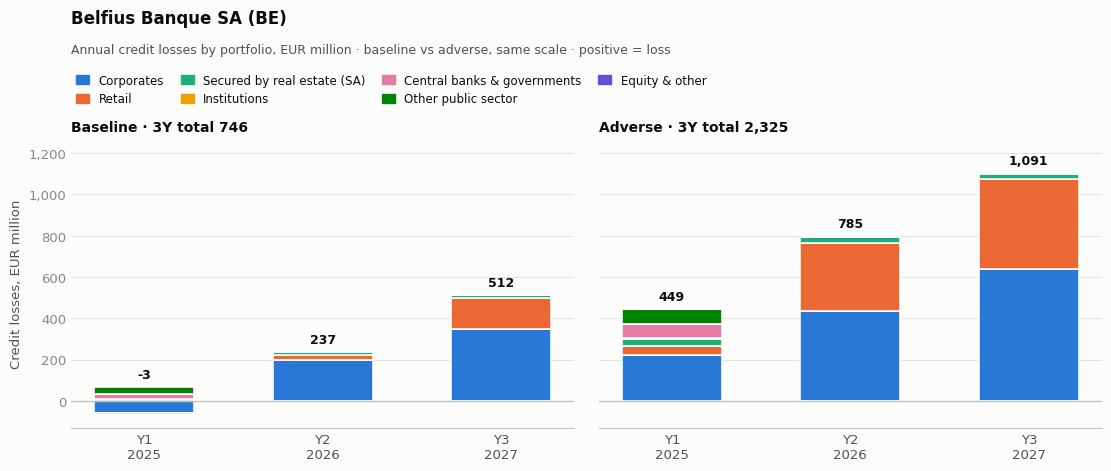

In [15]:
report_bank('A5GWLFH3KM7YV2SFQL84')  # BE · Belfius Banque SA

Under the **adverse** scenario, credit losses total **EUR 6,543 m** over 2025–2027 (2.30% of 2024 exposure), against EUR 2,152 m in the baseline. Year 1 accounts for 41% of the adverse total (Y1 2,666, Y2 2,088, Y3 1,789). Largest adverse contributors: Corporates EUR 3,917 m (60%, loss rate 4.34%); Retail EUR 2,204 m (34%, loss rate 2.27%). The credit-template total differs from the P&L impairment line by up to EUR 1.0 m in a scenario-year (memo rows).

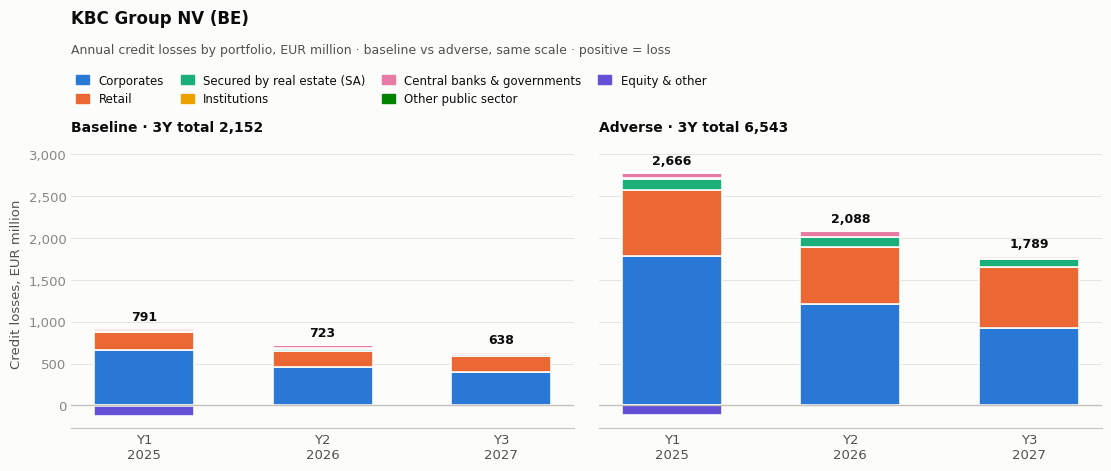

In [16]:
report_bank('213800X3Q9LSAKRUWY91')  # BE · KBC Group NV

Under the **adverse** scenario, credit losses total **EUR 2,616 m** over 2025–2027 (1.04% of 2024 exposure), against EUR 800 m in the baseline. Year 1 accounts for 33% of the adverse total (Y1 871, Y2 978, Y3 766). Largest adverse contributors: Corporates EUR 1,753 m (67%, loss rate 1.67%); Retail EUR 500 m (19%, loss rate 1.72%).

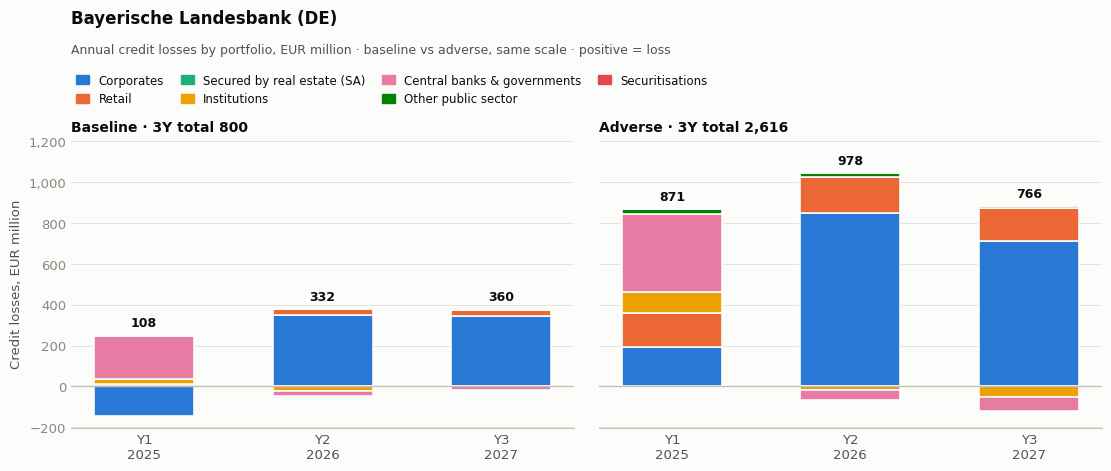

In [17]:
report_bank('VDYMYTQGZZ6DU0912C88')  # DE · Bayerische Landesbank

Under the **adverse** scenario, credit losses total **EUR 4,802 m** over 2025–2027 (1.16% of 2024 exposure), against EUR 1,915 m in the baseline. Year 1 accounts for 43% of the adverse total (Y1 2,083, Y2 1,370, Y3 1,350). Largest adverse contributors: Corporates EUR 2,122 m (44%, loss rate 1.72%); Retail EUR 1,965 m (41%, loss rate 1.27%).

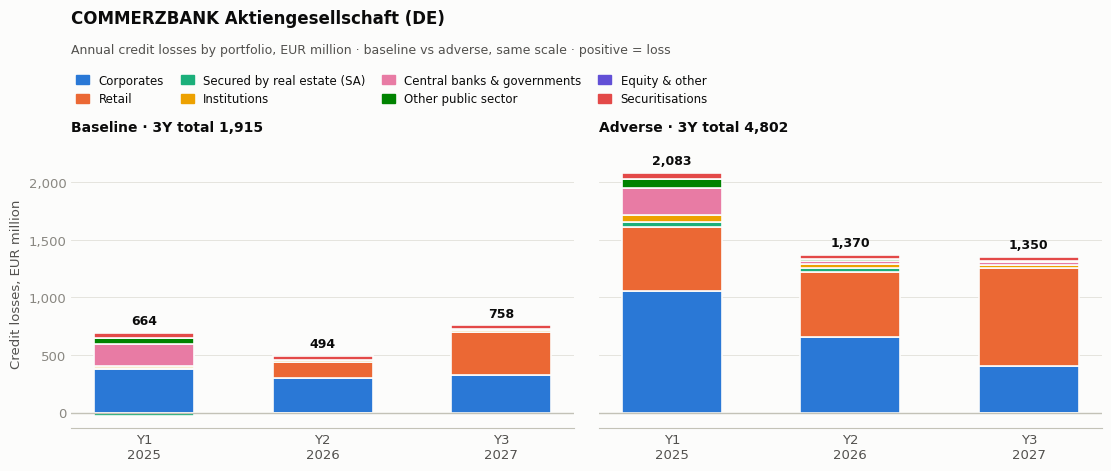

In [18]:
report_bank('851WYGNLUQLFZBSYGB56')  # DE · COMMERZBANK Aktiengesellschaft

Under the **adverse** scenario, credit losses total **EUR 17 m** over 2025–2027 (0.64% of 2024 exposure), against EUR 3 m in the baseline. Year 1 accounts for 79% of the adverse total (Y1 13, Y2 2, Y3 2). Largest adverse contributors: Institutions EUR 9 m (55%, loss rate 0.83%); Corporates EUR 5 m (31%, loss rate 0.36%). The credit-template total differs from the P&L impairment line by up to EUR 1.5 m in a scenario-year (memo rows).

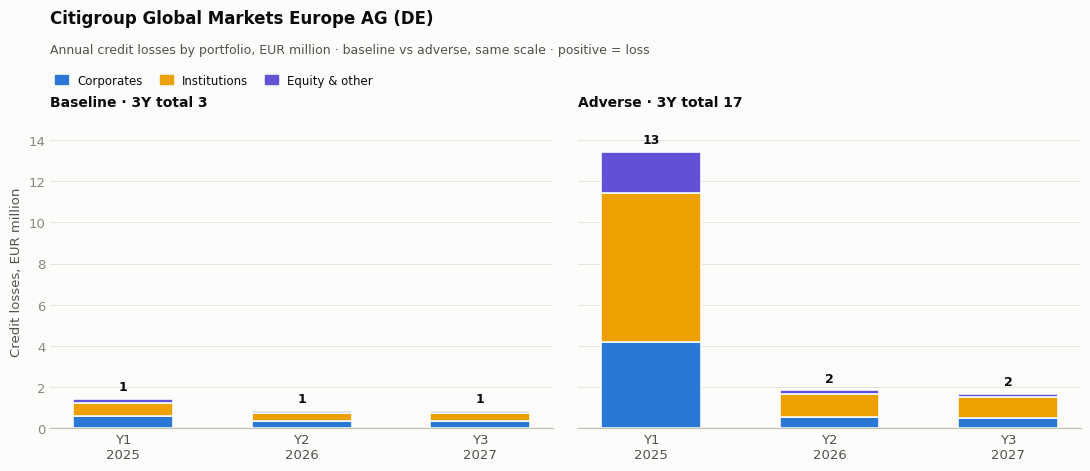

In [19]:
report_bank('6TJCK1B7E7UTXP528Y04')  # DE · Citigroup Global Markets Europe AG

Under the **adverse** scenario, credit losses total **EUR 3,893 m** over 2025–2027 (0.82% of 2024 exposure), against EUR 1,114 m in the baseline. Year 1 accounts for 52% of the adverse total (Y1 2,012, Y2 1,057, Y3 824). Largest adverse contributors: Corporates EUR 2,188 m (56%, loss rate 2.11%); Retail EUR 1,507 m (39%, loss rate 1.49%).

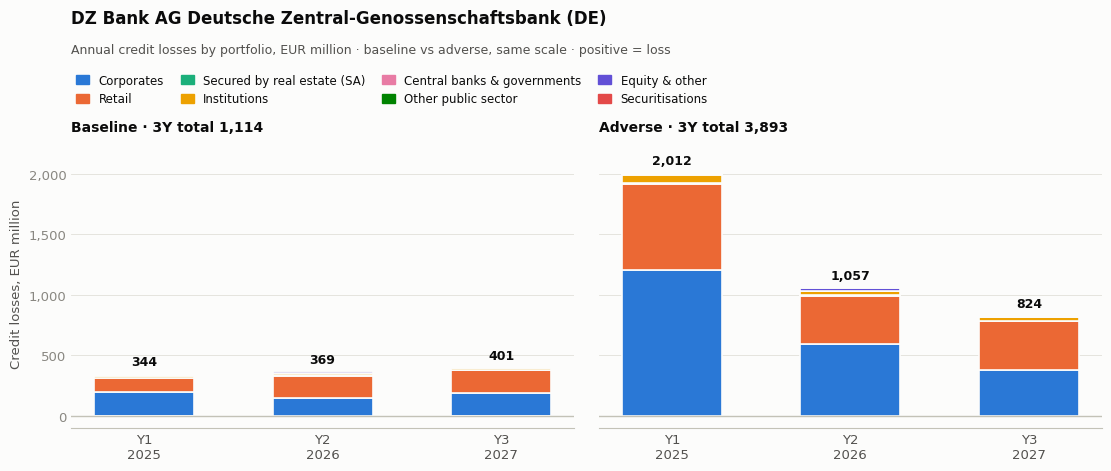

In [20]:
report_bank('529900HNOAA1KXQJUQ27')  # DE · DZ Bank AG Deutsche Zentral-Genossenschaftsbank

Under the **adverse** scenario, credit losses total **EUR 14,143 m** over 2025–2027 (1.72% of 2024 exposure), against EUR 7,965 m in the baseline. Year 1 accounts for 64% of the adverse total (Y1 9,003, Y2 3,026, Y3 2,114). Largest adverse contributors: Corporates EUR 7,025 m (50%, loss rate 2.25%); Retail EUR 5,582 m (39%, loss rate 2.56%).

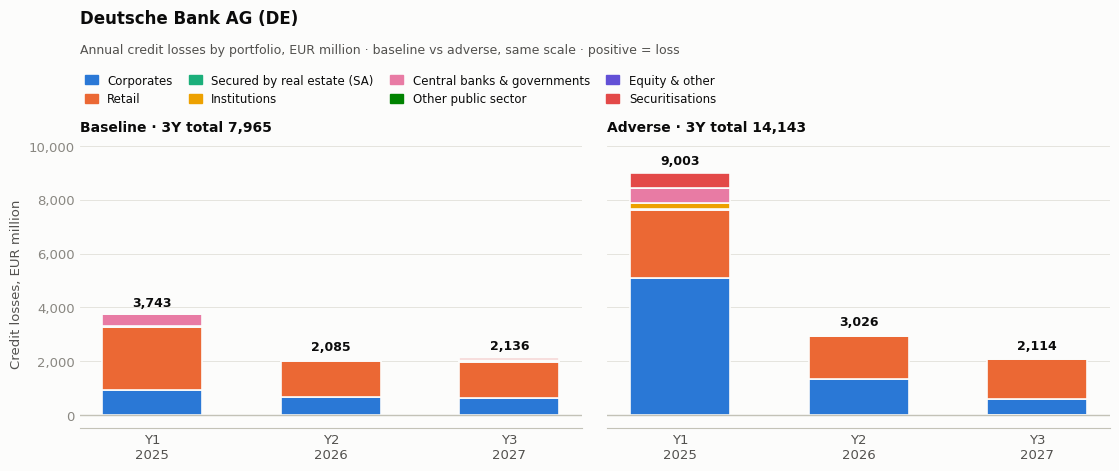

In [21]:
report_bank('7LTWFZYICNSX8D621K86')  # DE · Deutsche Bank AG

Under the **adverse** scenario, credit losses total **EUR 413 m** over 2025–2027 (1.88% of 2024 exposure), against EUR 92 m in the baseline. Year 1 accounts for 70% of the adverse total (Y1 289, Y2 91, Y3 32). Largest adverse contributors: Corporates EUR 395 m (96%, loss rate 5.31%); Institutions EUR 17 m (4%, loss rate 1.89%).

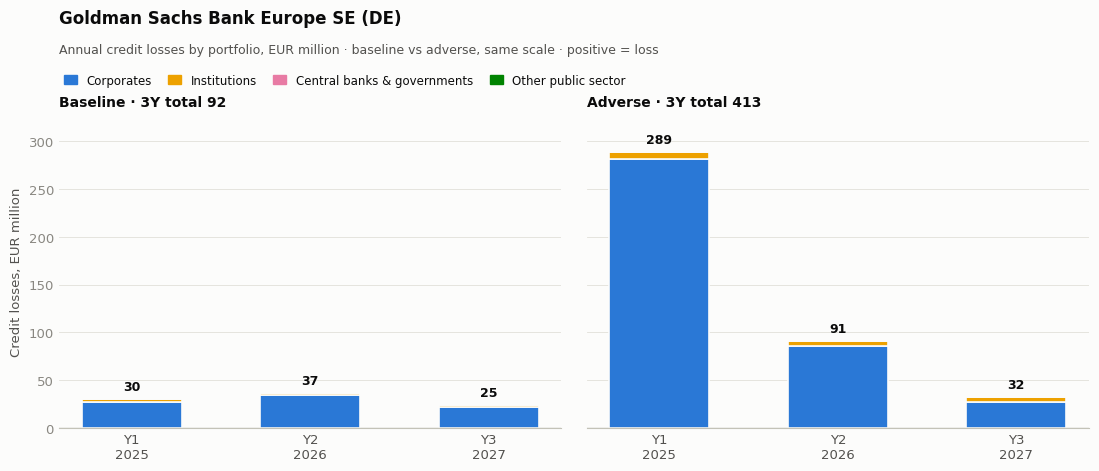

In [22]:
report_bank('8IBZUGJ7JPLH368JE346')  # DE · Goldman Sachs Bank Europe SE

Under the **adverse** scenario, credit losses total **EUR 397 m** over 2025–2027 (1.40% of 2024 exposure), against EUR 6 m in the baseline. Year 1 accounts for 73% of the adverse total (Y1 289, Y2 55, Y3 53). Largest adverse contributors: Corporates EUR 345 m (87%, loss rate 1.47%); Secured by real estate (SA) EUR 45 m (11%, loss rate 2.43%).

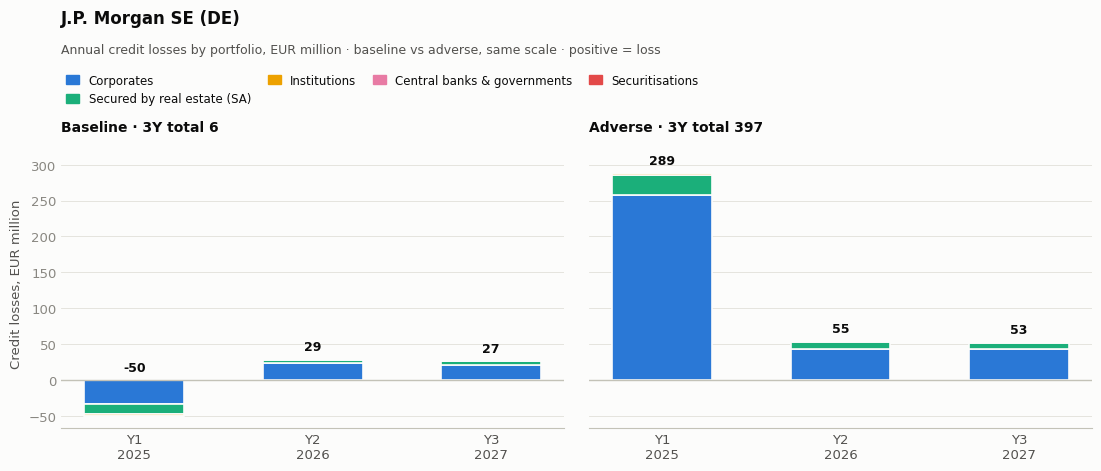

In [23]:
report_bank('549300ZK53CNGEEI6A29')  # DE · J.P. Morgan SE

Under the **adverse** scenario, credit losses total **EUR 3,051 m** over 2025–2027 (1.08% of 2024 exposure), against EUR 287 m in the baseline. Year 1 accounts for 39% of the adverse total (Y1 1,195, Y2 870, Y3 986). Largest adverse contributors: Corporates EUR 2,718 m (89%, loss rate 1.95%); Retail EUR 178 m (6%, loss rate 3.81%).

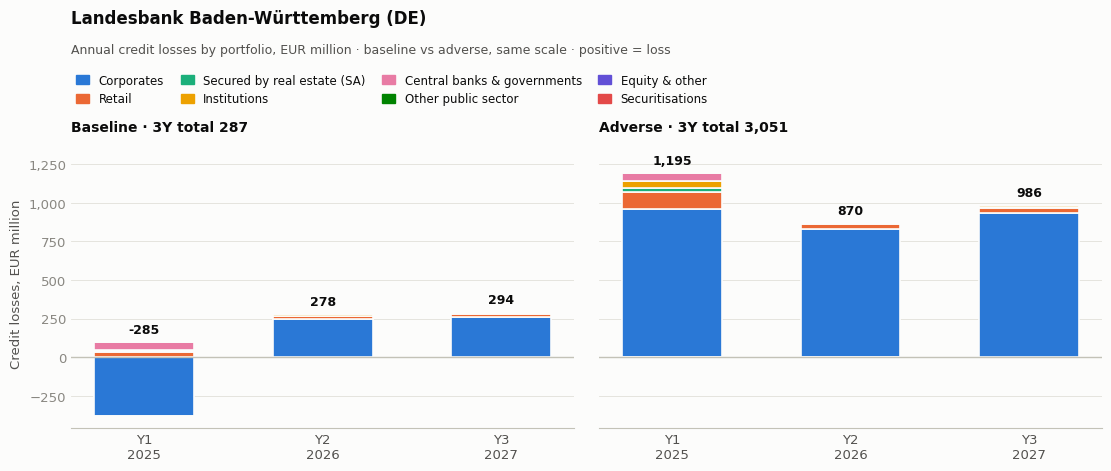

In [24]:
report_bank('B81CK4ESI35472RHJ606')  # DE · Landesbank Baden-Württemberg

Under the **adverse** scenario, credit losses total **EUR 2,489 m** over 2025–2027 (1.30% of 2024 exposure), against EUR 800 m in the baseline. Year 1 accounts for 53% of the adverse total (Y1 1,319, Y2 575, Y3 595). Largest adverse contributors: Corporates EUR 2,151 m (86%, loss rate 3.17%); Retail EUR 190 m (8%, loss rate 3.28%).

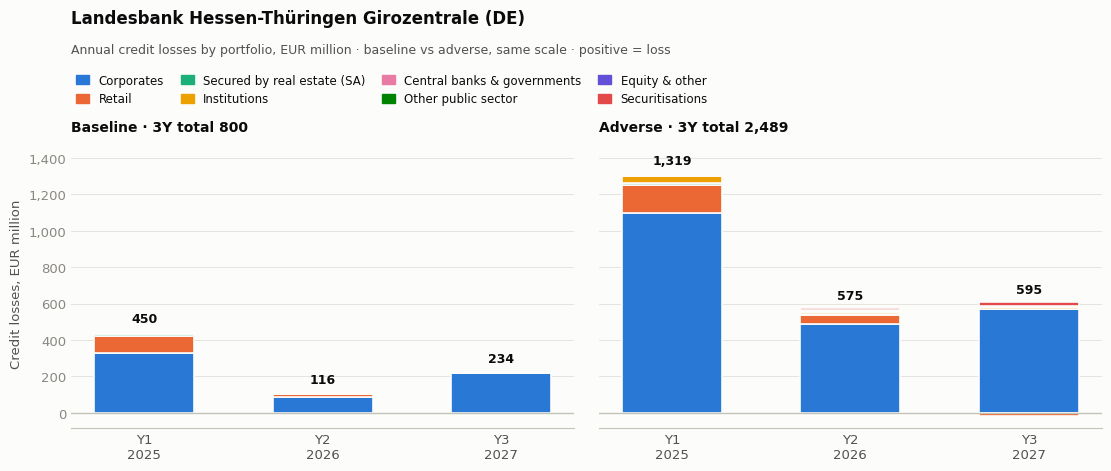

In [25]:
report_bank('DIZES5CFO5K3I5R58746')  # DE · Landesbank Hessen-Thüringen Girozentrale

Under the **adverse** scenario, credit losses total **EUR 50 m** over 2025–2027 (0.36% of 2024 exposure), against EUR 17 m in the baseline. Year 1 accounts for 67% of the adverse total (Y1 33, Y2 10, Y3 7). Largest adverse contributors: Corporates EUR 43 m (86%, loss rate 1.52%); Institutions EUR 5 m (11%, loss rate 1.03%).

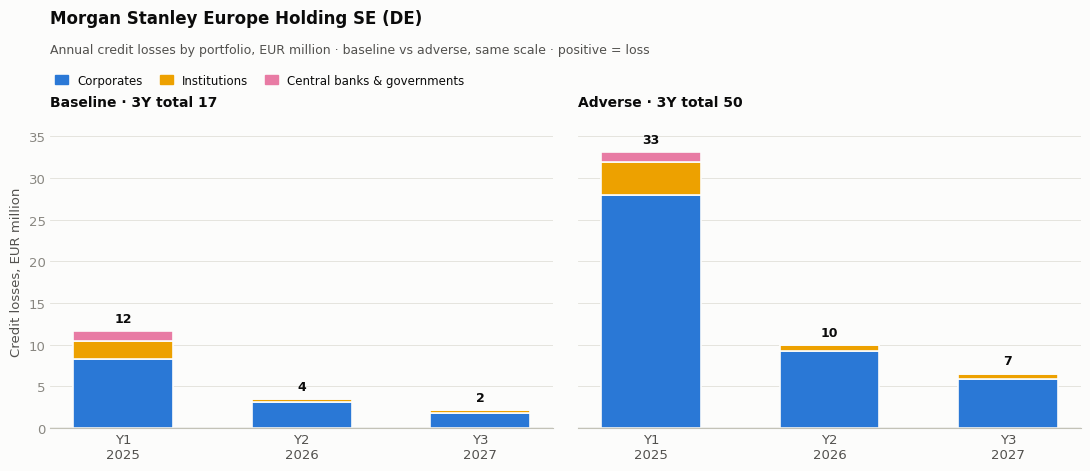

In [26]:
report_bank('549300C9KPZR0VZ16R05')  # DE · Morgan Stanley Europe Holding SE

Under the **adverse** scenario, credit losses total **EUR 1,434 m** over 2025–2027 (1.21% of 2024 exposure), against EUR 362 m in the baseline. Year 1 accounts for 44% of the adverse total (Y1 634, Y2 420, Y3 380). Largest adverse contributors: Corporates EUR 1,294 m (90%, loss rate 1.95%); Institutions EUR 41 m (3%, loss rate 0.21%).

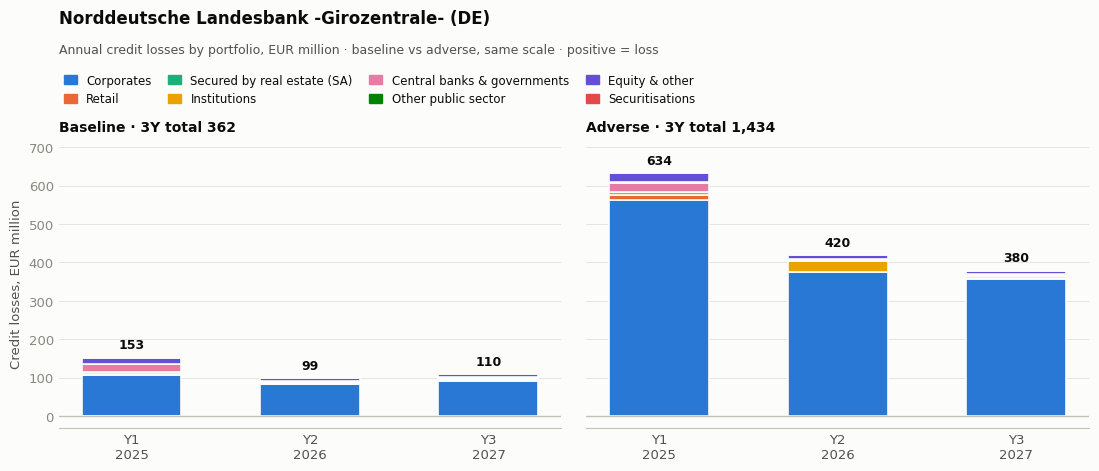

In [27]:
report_bank('DSNHHQ2B9X5N6OUJ1236')  # DE · Norddeutsche Landesbank -Girozentrale-

Under the **adverse** scenario, credit losses total **EUR 7,324 m** over 2025–2027 (3.62% of 2024 exposure), against EUR 2,428 m in the baseline. Year 1 accounts for 78% of the adverse total (Y1 5,703, Y2 915, Y3 707). Largest adverse contributors: Retail EUR 3,908 m (53%, loss rate 6.38%); Corporates EUR 3,326 m (45%, loss rate 5.63%).

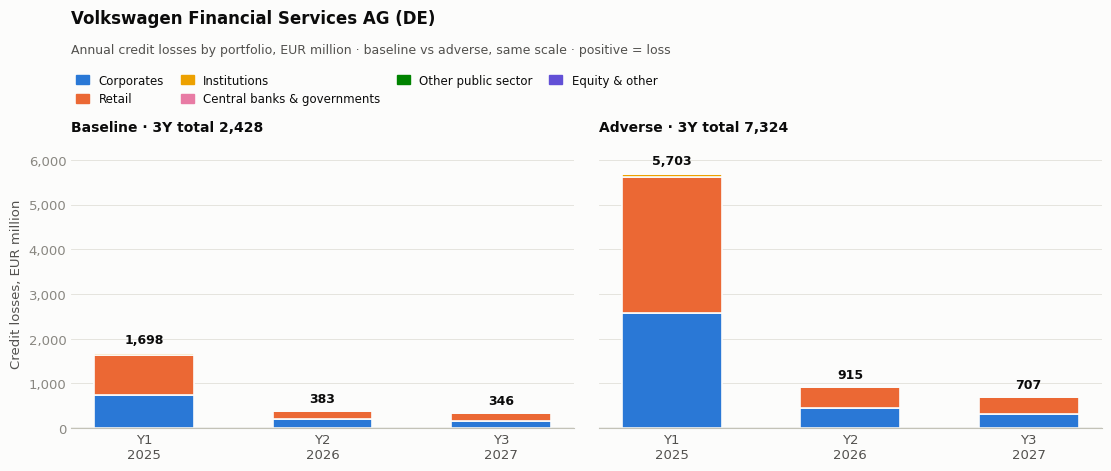

In [28]:
report_bank('529900SSGT49ZZSWYE62')  # DE · Volkswagen Financial Services AG

Under the **adverse** scenario, credit losses total **EUR 7,603 m** over 2025–2027 (2.86% of 2024 exposure), against EUR 7 m in the baseline. Year 1 accounts for 57% of the adverse total (Y1 4,346, Y2 1,676, Y3 1,580). Largest adverse contributors: Corporates EUR 5,547 m (73%, loss rate 3.96%); Retail EUR 1,380 m (18%, loss rate 1.43%). The credit-template total differs from the P&L impairment line by up to EUR 708.9 m in a scenario-year (memo rows).

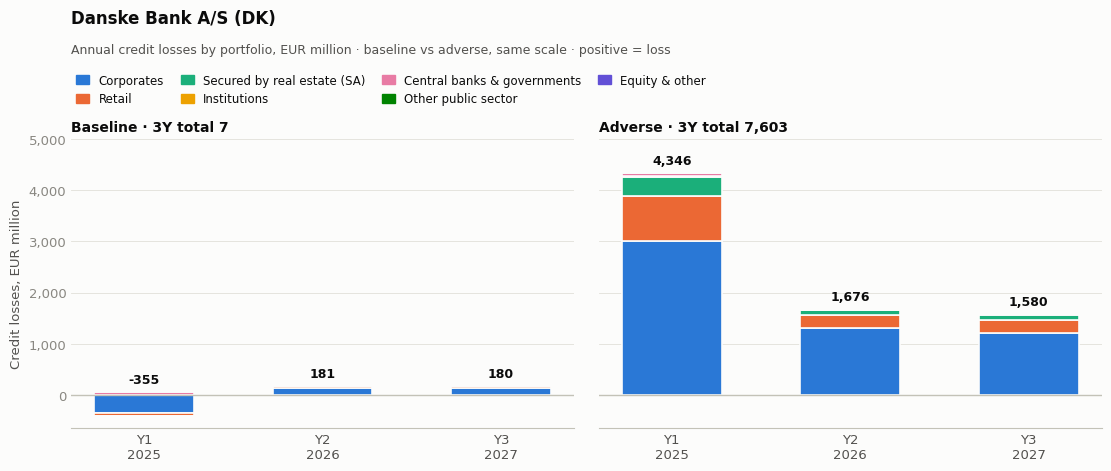

In [29]:
report_bank('MAES062Z21O4RZ2U7M96')  # DK · Danske Bank A/S

Under the **adverse** scenario, credit losses total **EUR 1,991 m** over 2025–2027 (2.11% of 2024 exposure), against EUR 835 m in the baseline. Year 1 accounts for 46% of the adverse total (Y1 920, Y2 582, Y3 490). Largest adverse contributors: Corporates EUR 1,569 m (79%, loss rate 4.55%); Retail EUR 252 m (13%, loss rate 0.85%).

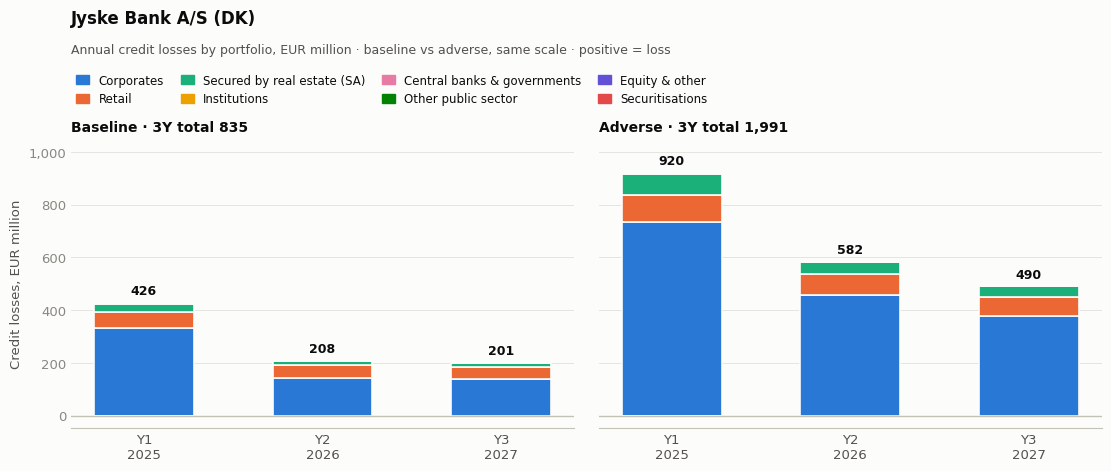

In [30]:
report_bank('3M5E1GQGKL17HI6CPN30')  # DK · Jyske Bank A/S

Under the **adverse** scenario, credit losses total **EUR 3,629 m** over 2025–2027 (1.58% of 2024 exposure), against EUR 534 m in the baseline. Year 1 accounts for 49% of the adverse total (Y1 1,787, Y2 1,238, Y3 604). Largest adverse contributors: Corporates EUR 2,725 m (75%, loss rate 3.41%); Retail EUR 904 m (25%, loss rate 0.72%).

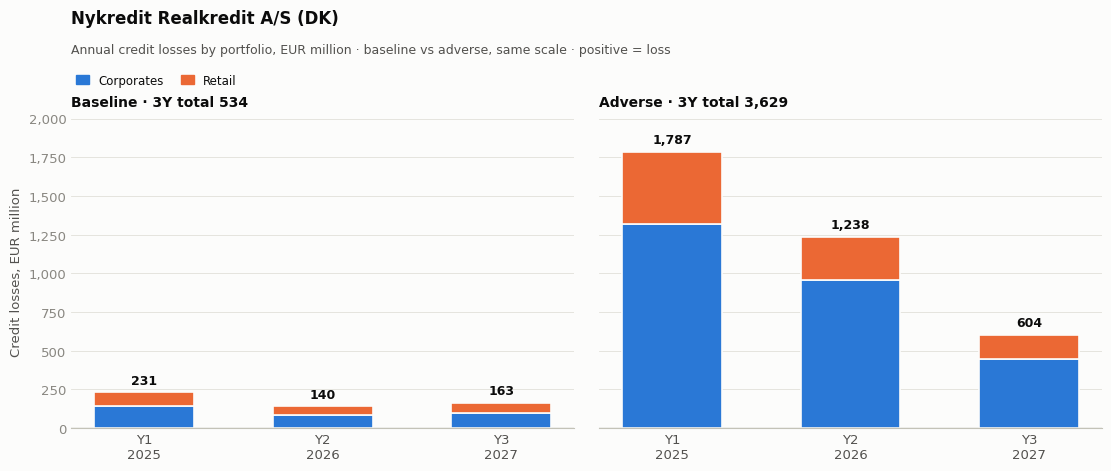

In [31]:
report_bank('LIU16F6VZJSD6UKHD557')  # DK · Nykredit Realkredit A/S

Under the **adverse** scenario, credit losses total **EUR 35,599 m** over 2025–2027 (5.44% of 2024 exposure), against EUR 22,712 m in the baseline. Year 1 accounts for 41% of the adverse total (Y1 14,482, Y2 11,156, Y3 9,961). Largest adverse contributors: Retail EUR 21,020 m (59%, loss rate 11.74%); Corporates EUR 11,266 m (32%, loss rate 5.02%). The credit-template total differs from the P&L impairment line by up to EUR 1.5 m in a scenario-year (memo rows).

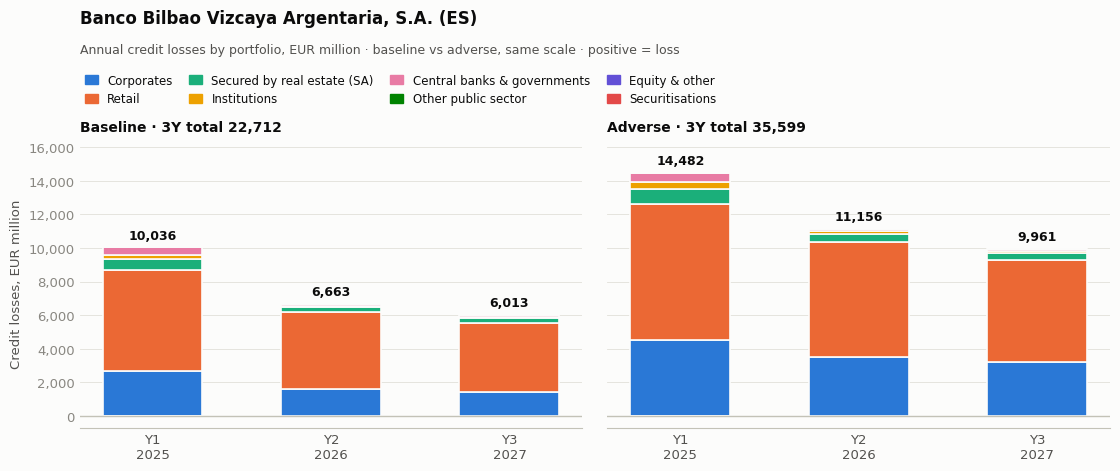

In [32]:
report_bank('K8MS7FD7N5Z2WQ51AZ71')  # ES · Banco Bilbao Vizcaya Argentaria, S.A.

Under the **adverse** scenario, credit losses total **EUR 44,852 m** over 2025–2027 (3.02% of 2024 exposure), against EUR 25,014 m in the baseline. Year 1 accounts for 47% of the adverse total (Y1 21,120, Y2 10,342, Y3 13,390). Largest adverse contributors: Retail EUR 34,902 m (78%, loss rate 6.42%); Corporates EUR 5,349 m (12%, loss rate 1.95%).

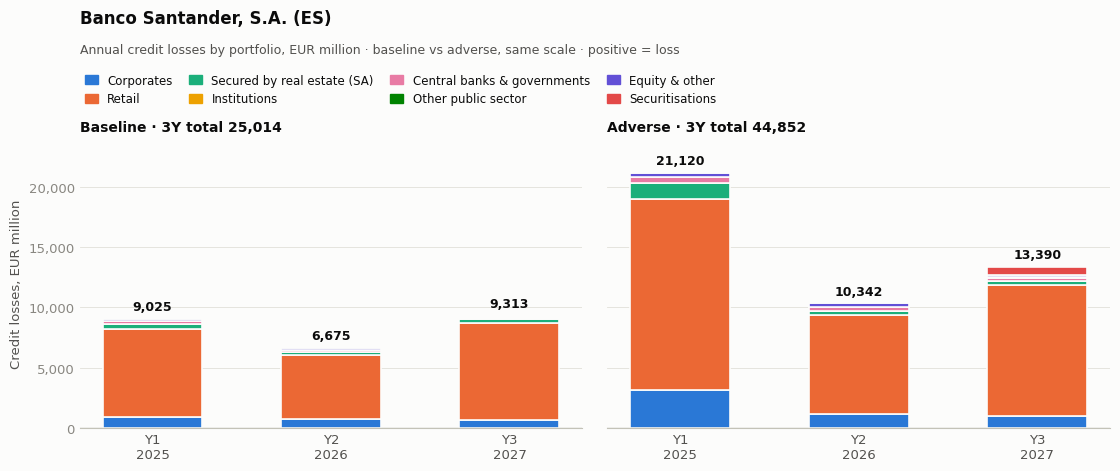

In [33]:
report_bank('5493006QMFDDMYWIAM13')  # ES · Banco Santander, S.A.

Under the **adverse** scenario, credit losses total **EUR 4,493 m** over 2025–2027 (2.01% of 2024 exposure), against EUR 1,756 m in the baseline. Year 1 accounts for 61% of the adverse total (Y1 2,731, Y2 866, Y3 896). Largest adverse contributors: Retail EUR 2,614 m (58%, loss rate 2.47%); Corporates EUR 1,339 m (30%, loss rate 2.79%).

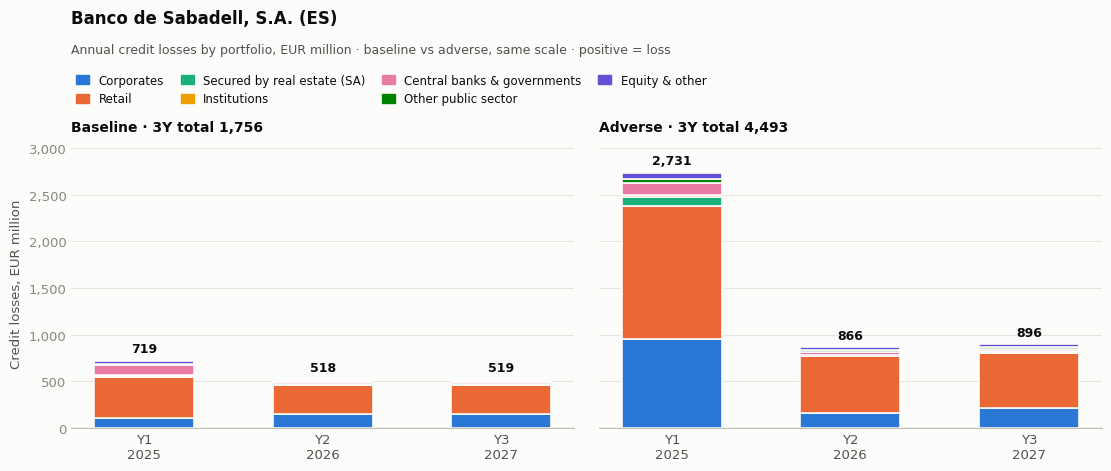

In [34]:
report_bank('SI5RG2M0WQQLZCXKRM20')  # ES · Banco de Sabadell, S.A.

Under the **adverse** scenario, credit losses total **EUR 2,936 m** over 2025–2027 (2.50% of 2024 exposure), against EUR 1,186 m in the baseline. Year 1 accounts for 66% of the adverse total (Y1 1,936, Y2 657, Y3 343). Largest adverse contributors: Retail EUR 1,237 m (42%, loss rate 3.17%); Corporates EUR 751 m (26%, loss rate 2.95%).

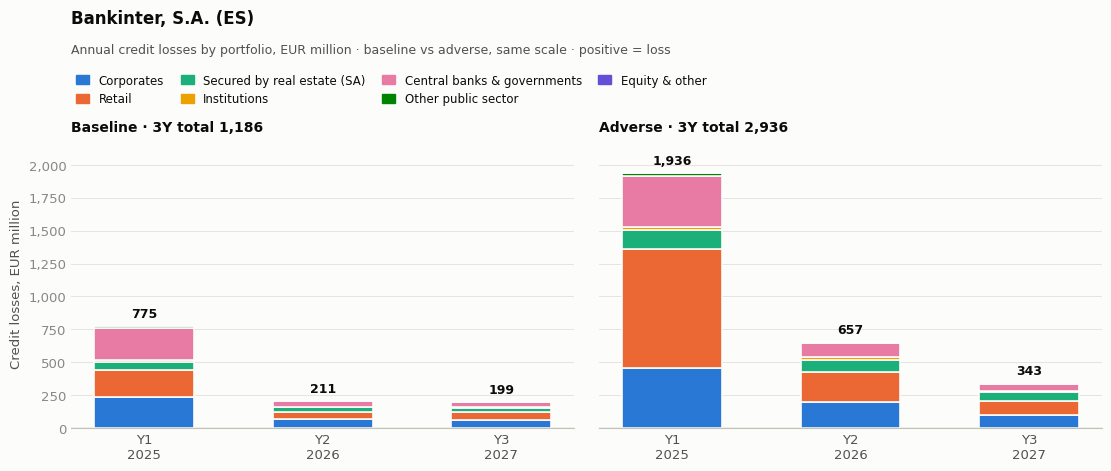

In [35]:
report_bank('VWMYAEQSTOPNV0SUGU82')  # ES · Bankinter, S.A.

Under the **adverse** scenario, credit losses total **EUR 10,223 m** over 2025–2027 (1.93% of 2024 exposure), against EUR 3,721 m in the baseline. Year 1 accounts for 47% of the adverse total (Y1 4,855, Y2 2,903, Y3 2,465). Largest adverse contributors: Retail EUR 6,433 m (63%, loss rate 3.01%); Corporates EUR 3,028 m (30%, loss rate 2.08%).

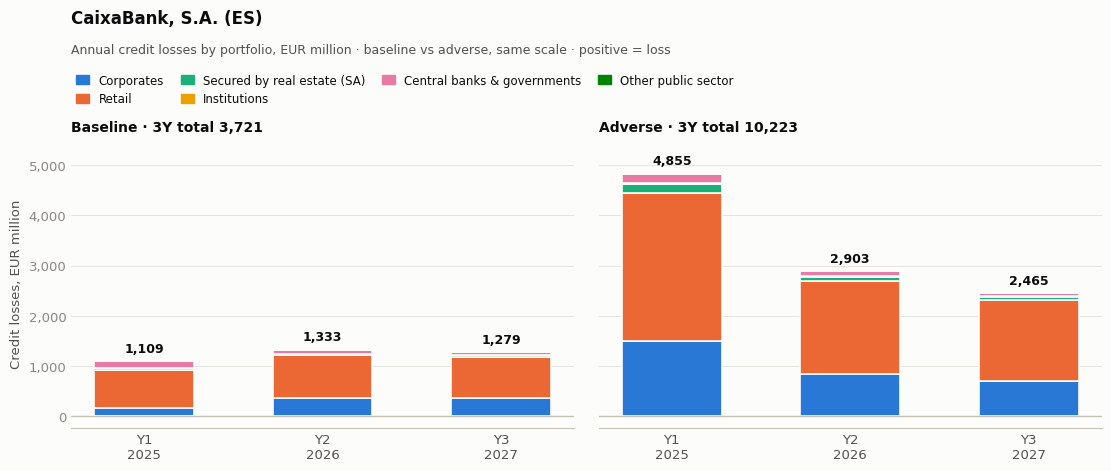

In [36]:
report_bank('7CUNS533WID6K7DGFI87')  # ES · CaixaBank, S.A.

Under the **adverse** scenario, credit losses total **EUR 1,385 m** over 2025–2027 (2.17% of 2024 exposure), against EUR 747 m in the baseline. Year 1 accounts for 50% of the adverse total (Y1 690, Y2 330, Y3 365). Largest adverse contributors: Retail EUR 634 m (46%, loss rate 1.85%); Corporates EUR 553 m (40%, loss rate 8.89%).

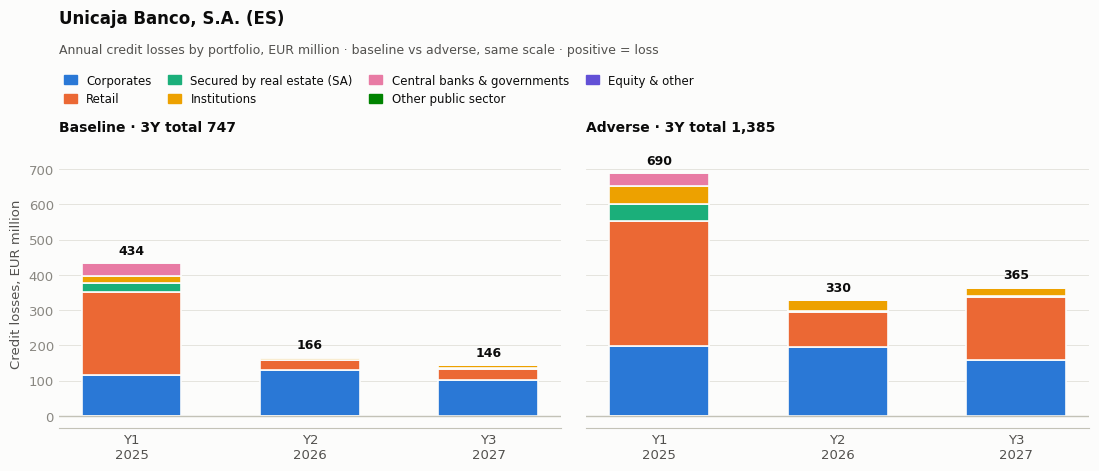

In [37]:
report_bank('5493007SJLLCTM6J6M37')  # ES · Unicaja Banco, S.A.

Under the **adverse** scenario, credit losses total **EUR 4,890 m** over 2025–2027 (1.33% of 2024 exposure), against EUR 2,308 m in the baseline. Year 1 accounts for 39% of the adverse total (Y1 1,883, Y2 1,628, Y3 1,379). Largest adverse contributors: Retail EUR 2,680 m (55%, loss rate 1.77%); Corporates EUR 1,301 m (27%, loss rate 0.76%).

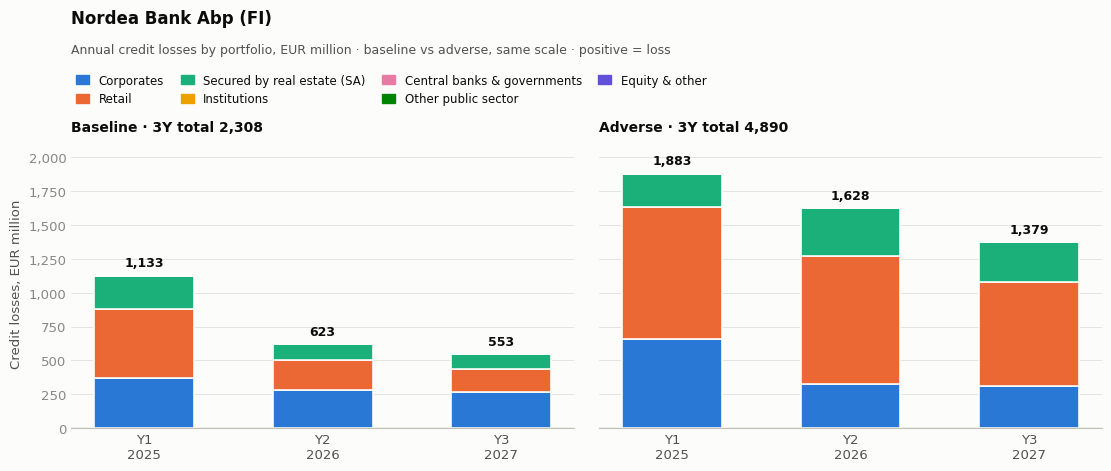

In [38]:
report_bank('529900ODI3047E2LIV03')  # FI · Nordea Bank Abp

Under the **adverse** scenario, credit losses total **EUR 4,650 m** over 2025–2027 (3.01% of 2024 exposure), against EUR 1,677 m in the baseline. Year 1 accounts for 57% of the adverse total (Y1 2,651, Y2 1,022, Y3 977). Largest adverse contributors: Secured by real estate (SA) EUR 1,512 m (33%, loss rate 2.40%); Corporates EUR 1,237 m (27%, loss rate 3.57%). The credit-template total differs from the P&L impairment line by up to EUR 368.2 m in a scenario-year (memo rows).

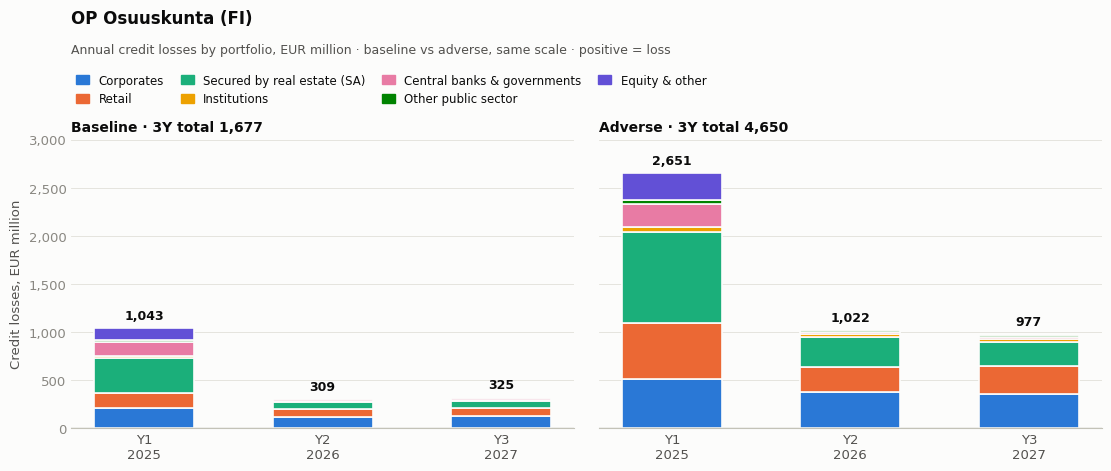

In [39]:
report_bank('7437003B5WFBOIEFY714')  # FI · OP Osuuskunta

Under the **adverse** scenario, credit losses total **EUR 27,649 m** over 2025–2027 (1.77% of 2024 exposure), against EUR 9,855 m in the baseline. Year 1 accounts for 43% of the adverse total (Y1 11,942, Y2 9,535, Y3 6,171). Largest adverse contributors: Retail EUR 14,251 m (52%, loss rate 3.77%); Corporates EUR 10,364 m (37%, loss rate 1.87%).

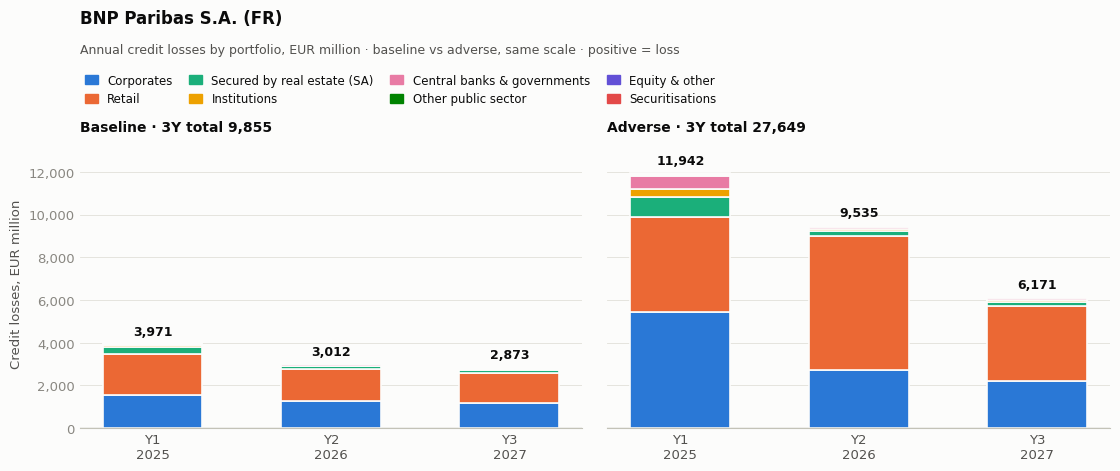

In [40]:
report_bank('R0MUWSFPU8MPRO8K5P83')  # FR · BNP Paribas S.A.

Under the **adverse** scenario, credit losses total **EUR 4 m** over 2025–2027 (0.08% of 2024 exposure), against EUR 2 m in the baseline. Year 1 accounts for 40% of the adverse total (Y1 2, Y2 1, Y3 1). Largest adverse contributors: Equity & other EUR 3 m (73%, loss rate 0.79%); Corporates EUR 1 m (17%, loss rate 2.64%).

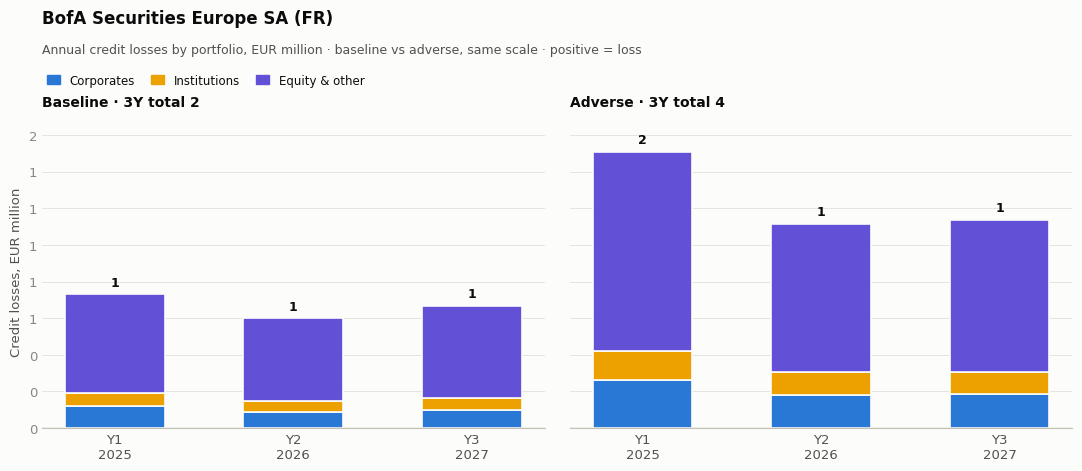

In [41]:
report_bank('549300FH0WJAPEHTIQ77')  # FR · BofA Securities Europe SA

Under the **adverse** scenario, credit losses total **EUR 17,238 m** over 2025–2027 (1.65% of 2024 exposure), against EUR 6,660 m in the baseline. Year 1 accounts for 56% of the adverse total (Y1 9,638, Y2 4,096, Y3 3,504). Largest adverse contributors: Retail EUR 12,986 m (75%, loss rate 2.81%); Corporates EUR 4,064 m (24%, loss rate 1.86%).

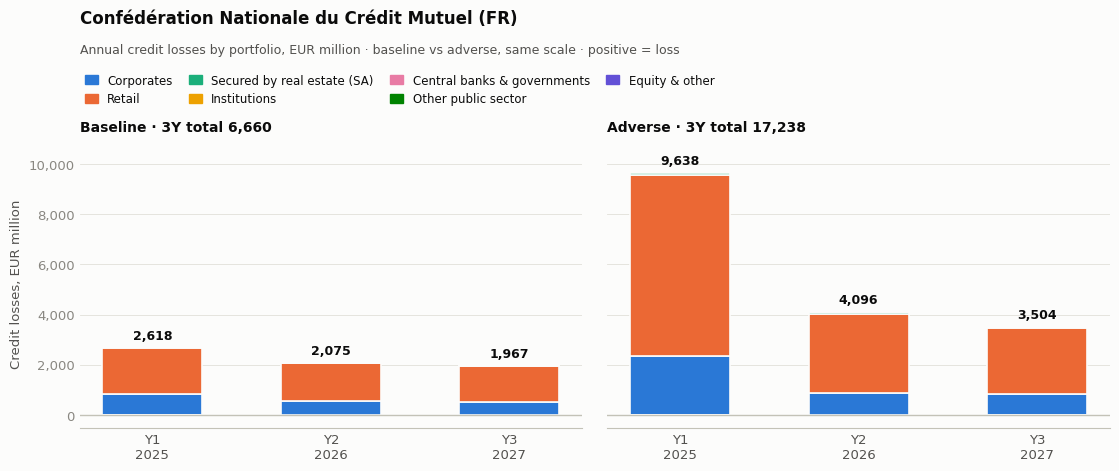

In [42]:
report_bank('9695000CG7B84NLR5984')  # FR · Confédération Nationale du Crédit Mutuel

Under the **adverse** scenario, credit losses total **EUR 13,397 m** over 2025–2027 (1.08% of 2024 exposure), against EUR 3,582 m in the baseline. Year 1 accounts for 33% of the adverse total (Y1 4,393, Y2 3,832, Y3 5,172). Largest adverse contributors: Corporates EUR 6,505 m (49%, loss rate 2.39%); Retail EUR 4,719 m (35%, loss rate 0.93%).

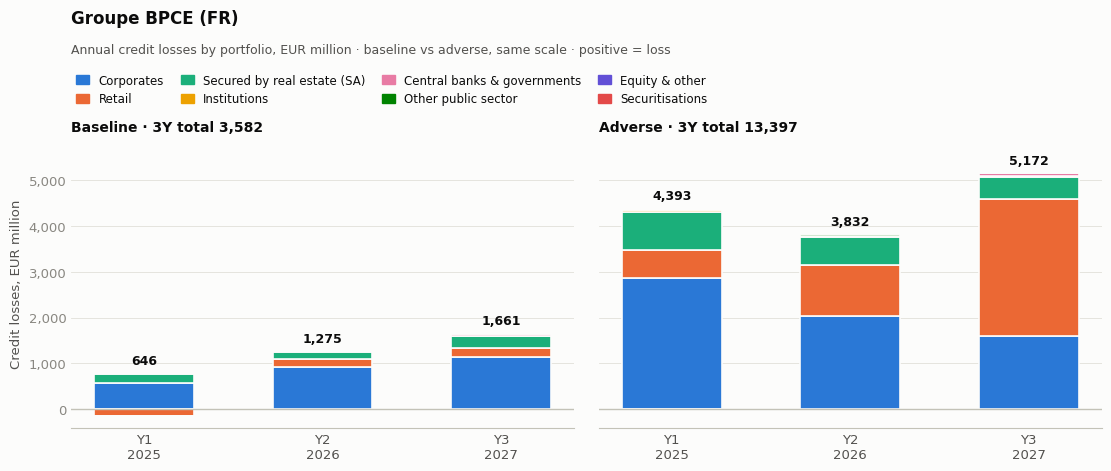

In [43]:
report_bank('FR9695005MSX1OYEMGDF')  # FR · Groupe BPCE

Under the **adverse** scenario, credit losses total **EUR 22,100 m** over 2025–2027 (1.17% of 2024 exposure), against EUR 4,673 m in the baseline. Year 1 accounts for 34% of the adverse total (Y1 7,598, Y2 7,910, Y3 6,592). Largest adverse contributors: Retail EUR 12,408 m (56%, loss rate 1.56%); Corporates EUR 7,351 m (33%, loss rate 1.56%).

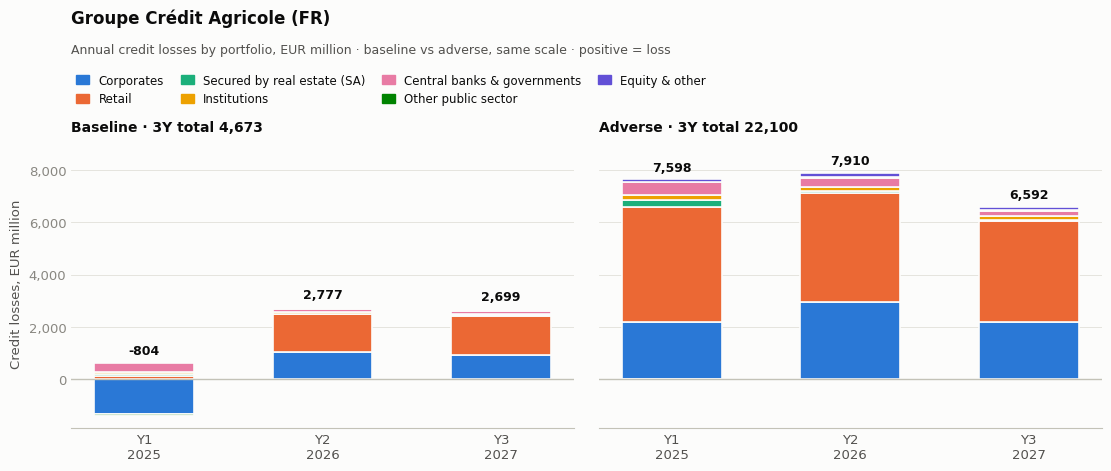

In [44]:
report_bank('FR969500TJ5KRTCJQWXH')  # FR · Groupe Crédit Agricole

Under the **adverse** scenario, credit losses total **EUR 1,060 m** over 2025–2027 (0.79% of 2024 exposure), against EUR 240 m in the baseline. Year 1 accounts for 62% of the adverse total (Y1 658, Y2 249, Y3 154). Largest adverse contributors: Corporates EUR 724 m (68%, loss rate 1.37%); Secured by real estate (SA) EUR 155 m (15%, loss rate 3.41%).

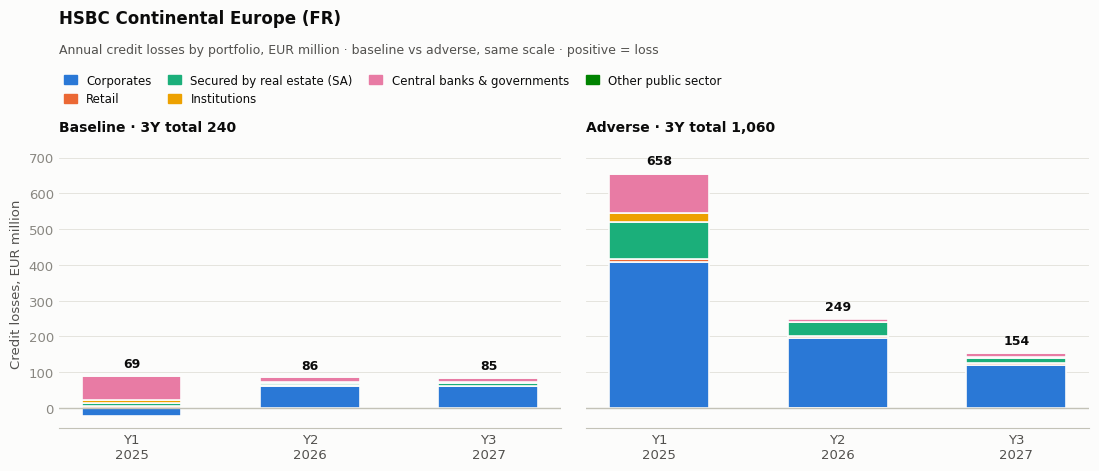

In [45]:
report_bank('F0HUI1NY1AZMJMD8LP67')  # FR · HSBC Continental Europe

Under the **adverse** scenario, credit losses total **EUR 3,017 m** over 2025–2027 (1.05% of 2024 exposure), against EUR 1,160 m in the baseline. Year 1 accounts for 42% of the adverse total (Y1 1,262, Y2 592, Y3 1,164). Largest adverse contributors: Corporates EUR 1,186 m (39%, loss rate 4.11%); Retail EUR 891 m (30%, loss rate 6.42%).

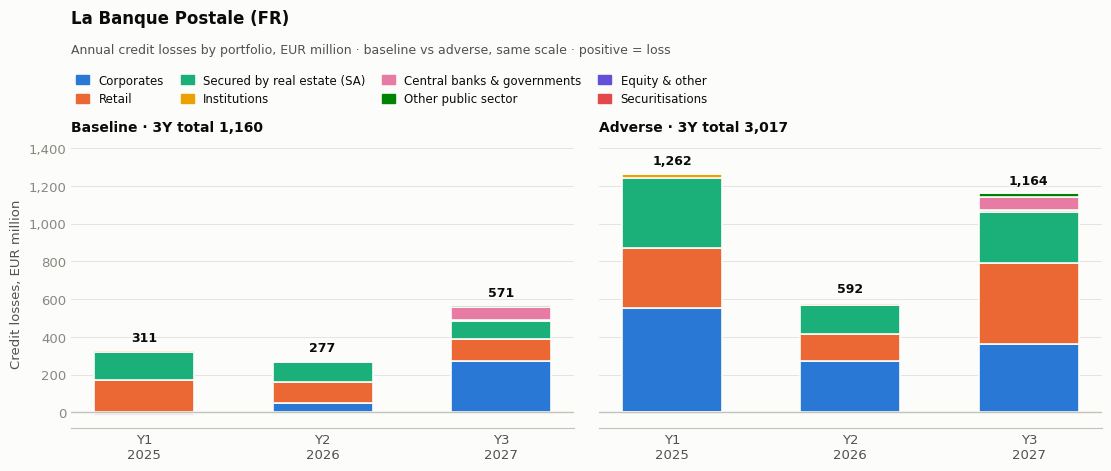

In [46]:
report_bank('96950066U5XAAIRCPA78')  # FR · La Banque Postale

Under the **adverse** scenario, credit losses total **EUR 10,008 m** over 2025–2027 (0.98% of 2024 exposure), against EUR 2,868 m in the baseline. Year 1 accounts for 50% of the adverse total (Y1 5,013, Y2 2,603, Y3 2,392). Largest adverse contributors: Retail EUR 5,210 m (52%, loss rate 2.49%); Corporates EUR 3,795 m (38%, loss rate 1.21%).

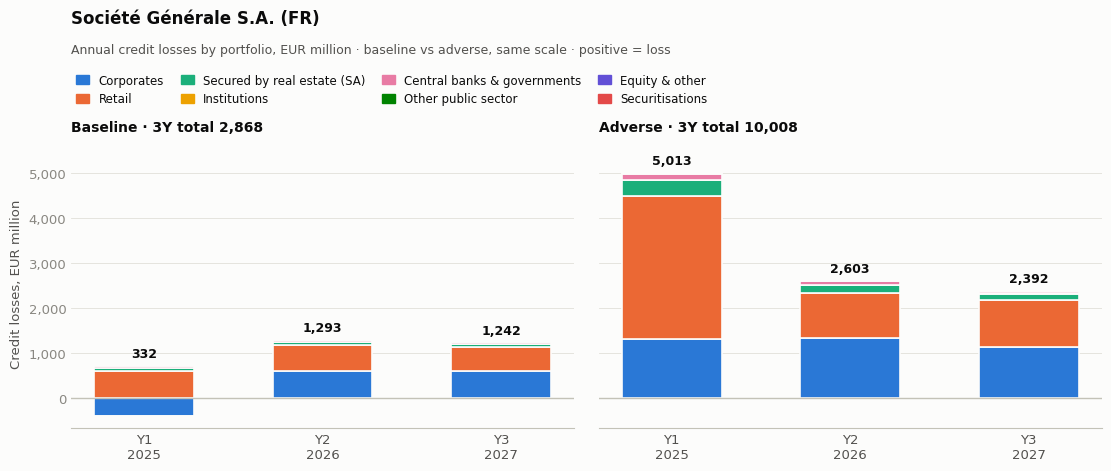

In [47]:
report_bank('O2RNE8IBXP4R0TD8PU41')  # FR · Société Générale S.A.

Under the **adverse** scenario, credit losses total **EUR 1,569 m** over 2025–2027 (2.43% of 2024 exposure), against EUR 517 m in the baseline. Year 1 accounts for 57% of the adverse total (Y1 889, Y2 391, Y3 289). Largest adverse contributors: Secured by real estate (SA) EUR 530 m (34%, loss rate 4.88%); Corporates EUR 402 m (26%, loss rate 2.47%). The credit-template total differs from the P&L impairment line by up to EUR 131.4 m in a scenario-year (memo rows).

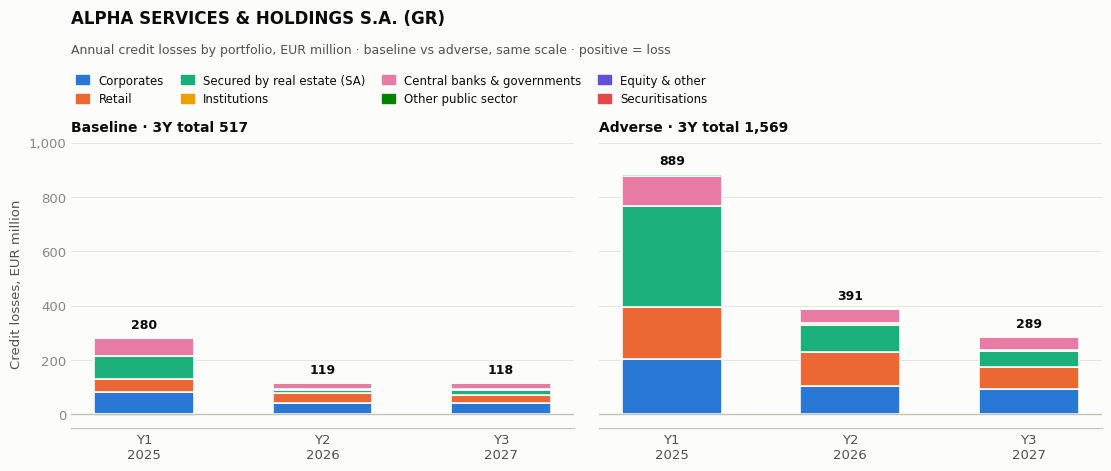

In [48]:
report_bank('5299009N55YRQC69CN08')  # GR · ALPHA SERVICES & HOLDINGS S.A.

Under the **adverse** scenario, credit losses total **EUR 1,778 m** over 2025–2027 (2.62% of 2024 exposure), against EUR 418 m in the baseline. Year 1 accounts for 55% of the adverse total (Y1 982, Y2 411, Y3 385). Largest adverse contributors: Secured by real estate (SA) EUR 710 m (40%, loss rate 5.73%); Retail EUR 407 m (23%, loss rate 12.91%).

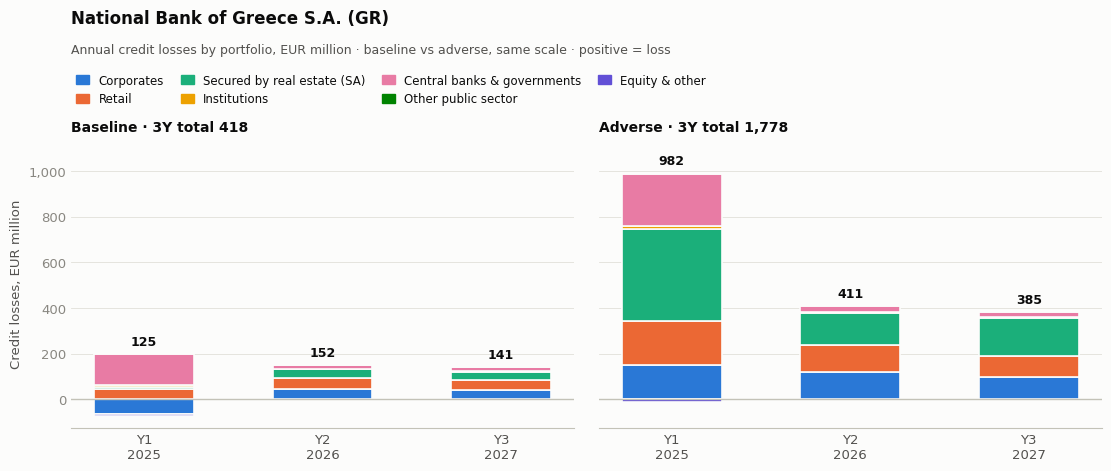

In [49]:
report_bank('5UMCZOEYKCVFAW8ZLO05')  # GR · National Bank of Greece S.A.

Under the **adverse** scenario, credit losses total **EUR 1,401 m** over 2025–2027 (2.03% of 2024 exposure), against EUR 258 m in the baseline. Year 1 accounts for 51% of the adverse total (Y1 713, Y2 396, Y3 293). Largest adverse contributors: Secured by real estate (SA) EUR 510 m (36%, loss rate 4.96%); Corporates EUR 406 m (29%, loss rate 1.91%). The credit-template total differs from the P&L impairment line by up to EUR 186.9 m in a scenario-year (memo rows).

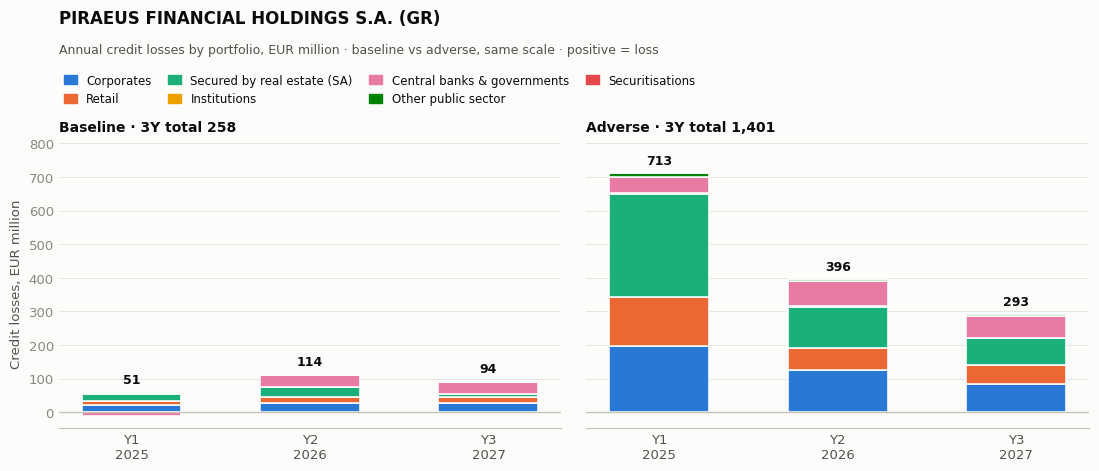

In [50]:
report_bank('M6AD1Y1KW32H8THQ6F76')  # GR · PIRAEUS FINANCIAL HOLDINGS S.A.

Under the **adverse** scenario, credit losses total **EUR 4,207 m** over 2025–2027 (3.82% of 2024 exposure), against EUR 688 m in the baseline. Year 1 accounts for 50% of the adverse total (Y1 2,083, Y2 1,093, Y3 1,031). Largest adverse contributors: Retail EUR 1,538 m (37%, loss rate 7.40%); Corporates EUR 1,240 m (29%, loss rate 5.63%).

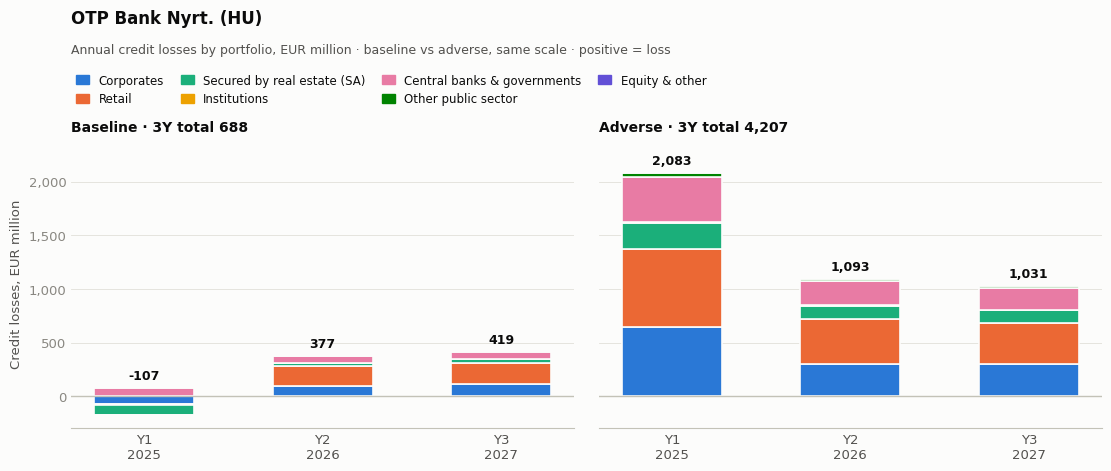

In [51]:
report_bank('529900W3MOO00A18X956')  # HU · OTP Bank Nyrt.

Under the **adverse** scenario, credit losses total **EUR 4,564 m** over 2025–2027 (3.82% of 2024 exposure), against EUR 547 m in the baseline. Year 1 accounts for 39% of the adverse total (Y1 1,765, Y2 1,502, Y3 1,297). Largest adverse contributors: Corporates EUR 1,863 m (41%, loss rate 7.95%); Secured by real estate (SA) EUR 1,615 m (35%, loss rate 5.96%).

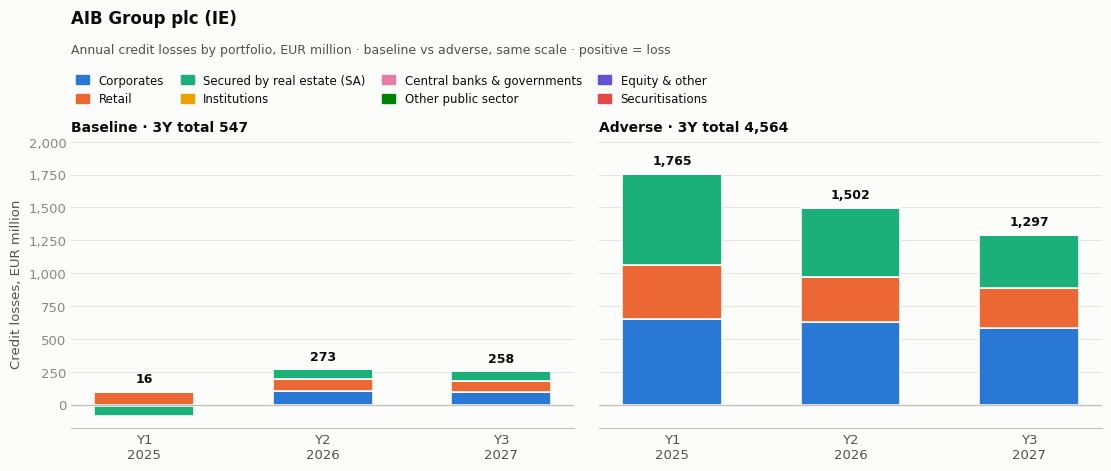

In [52]:
report_bank('635400AKJBGNS5WNQL34')  # IE · AIB Group plc

Under the **adverse** scenario, credit losses total **EUR 2,072 m** over 2025–2027 (2.73% of 2024 exposure), against EUR 522 m in the baseline. Year 1 accounts for 67% of the adverse total (Y1 1,383, Y2 505, Y3 185). Largest adverse contributors: Corporates EUR 1,240 m (60%, loss rate 3.86%); Institutions EUR 288 m (14%, loss rate 10.11%).

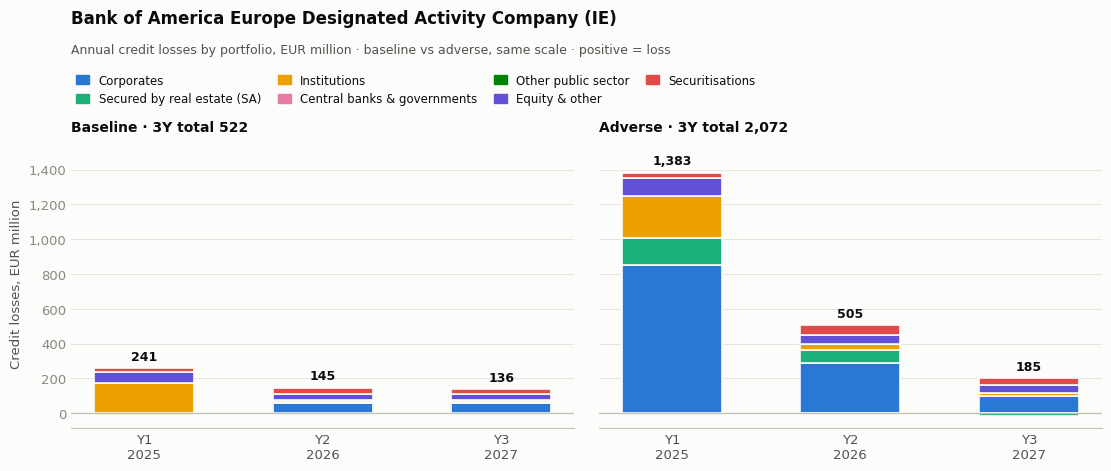

In [53]:
report_bank('EQYXK86SF381Q21S3020')  # IE · Bank of America Europe Designated Activity Company

Under the **adverse** scenario, credit losses total **EUR 3,668 m** over 2025–2027 (2.99% of 2024 exposure), against EUR 724 m in the baseline. Year 1 accounts for 52% of the adverse total (Y1 1,900, Y2 972, Y3 797). Largest adverse contributors: Corporates EUR 1,995 m (54%, loss rate 9.28%); Retail EUR 1,444 m (39%, loss rate 2.68%). The credit-template total differs from the P&L impairment line by up to EUR 53.8 m in a scenario-year (memo rows).

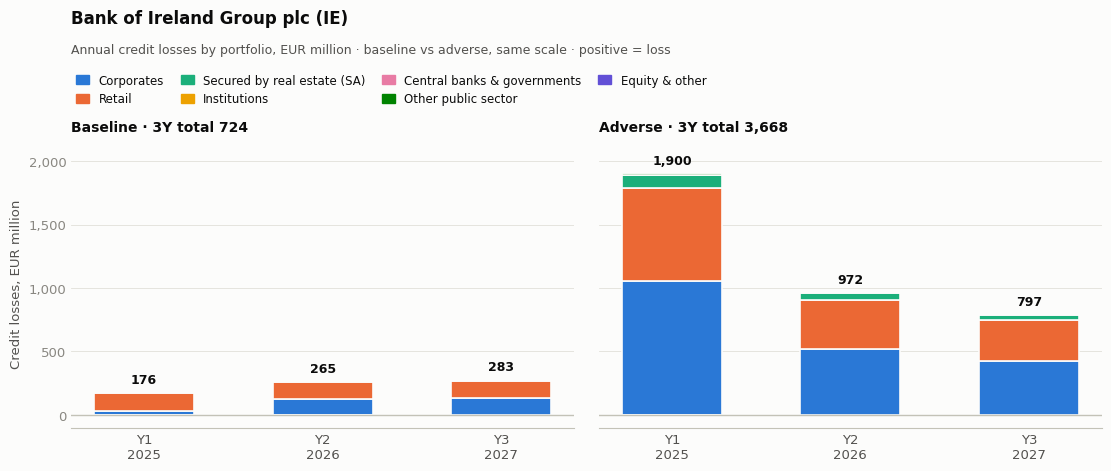

In [54]:
report_bank('635400C8EK6DRI12LJ39')  # IE · Bank of Ireland Group plc

Under the **adverse** scenario, credit losses total **EUR 1,381 m** over 2025–2027 (3.69% of 2024 exposure), against EUR 652 m in the baseline. Year 1 accounts for 79% of the adverse total (Y1 1,091, Y2 117, Y3 173). Largest adverse contributors: Corporates EUR 769 m (56%, loss rate 3.87%); Retail EUR 603 m (44%, loss rate 8.46%).

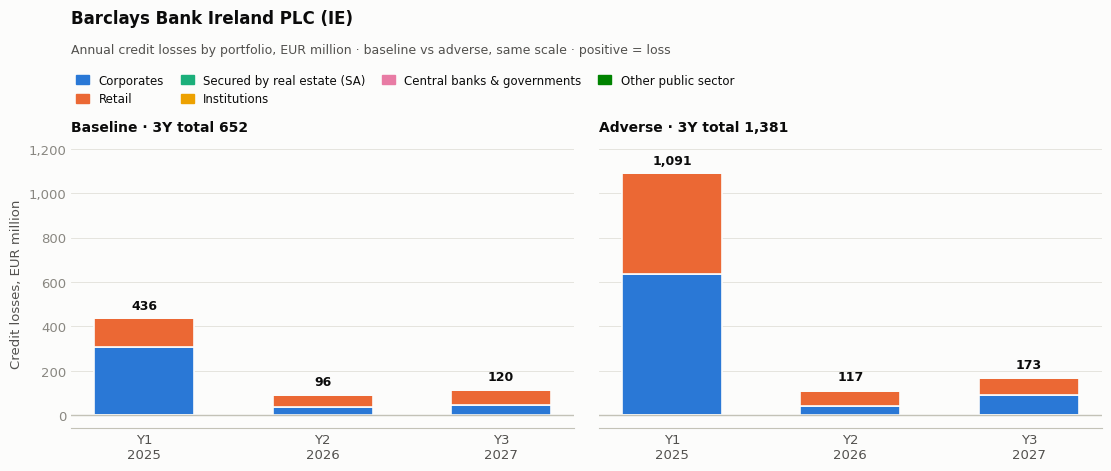

In [55]:
report_bank('2G5BKIC2CB69PRJH1W31')  # IE · Barclays Bank Ireland PLC

Under the **adverse** scenario, credit losses total **EUR 1,442 m** over 2025–2027 (1.26% of 2024 exposure), against EUR 284 m in the baseline. Year 1 accounts for 76% of the adverse total (Y1 1,090, Y2 182, Y3 170). Largest adverse contributors: Corporates EUR 1,058 m (73%, loss rate 2.17%); Institutions EUR 138 m (10%, loss rate 0.67%).

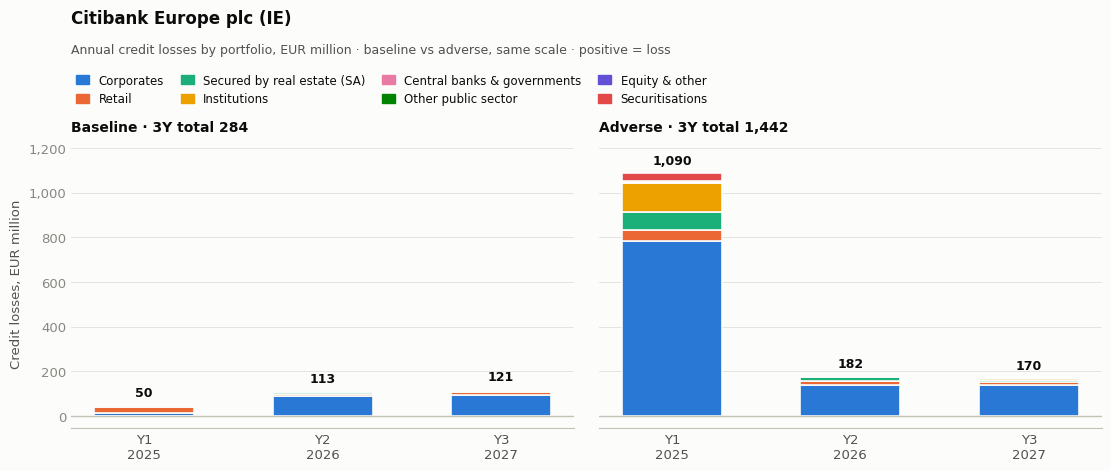

In [56]:
report_bank('N1FBEDJ5J41VKZLO2475')  # IE · Citibank Europe plc

Under the **adverse** scenario, credit losses total **EUR 3,656 m** over 2025–2027 (3.44% of 2024 exposure), against EUR 1,194 m in the baseline. Year 1 accounts for 43% of the adverse total (Y1 1,565, Y2 1,042, Y3 1,049). Largest adverse contributors: Corporates EUR 1,826 m (50%, loss rate 7.15%); Retail EUR 1,240 m (34%, loss rate 3.39%).

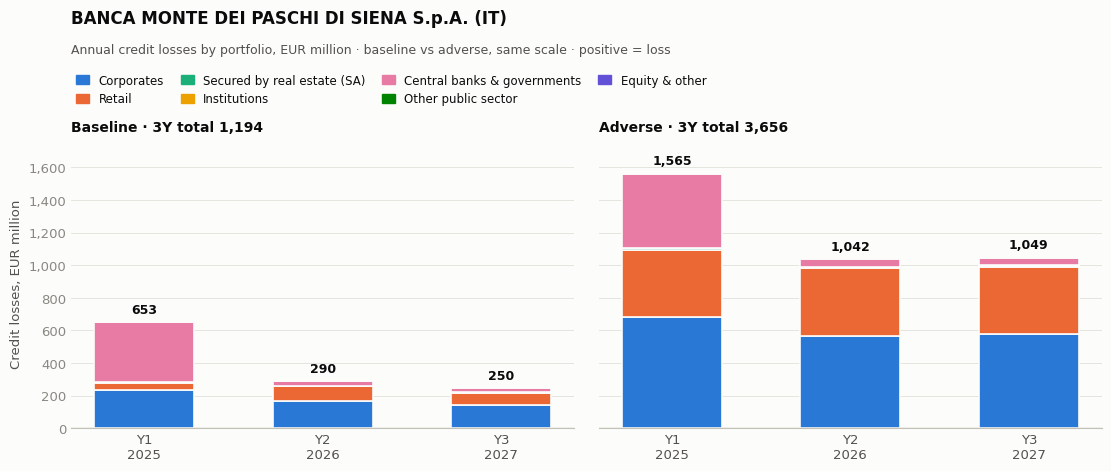

In [57]:
report_bank('J4CP7MHCXR8DAQMKIL78')  # IT · BANCA MONTE DEI PASCHI DI SIENA S.p.A.

Under the **adverse** scenario, credit losses total **EUR 3,600 m** over 2025–2027 (2.70% of 2024 exposure), against EUR 1,535 m in the baseline. Year 1 accounts for 39% of the adverse total (Y1 1,396, Y2 1,157, Y3 1,047). Largest adverse contributors: Corporates EUR 1,418 m (39%, loss rate 4.33%); Retail EUR 1,342 m (37%, loss rate 2.95%). The credit-template total differs from the P&L impairment line by up to EUR 3.0 m in a scenario-year (memo rows).

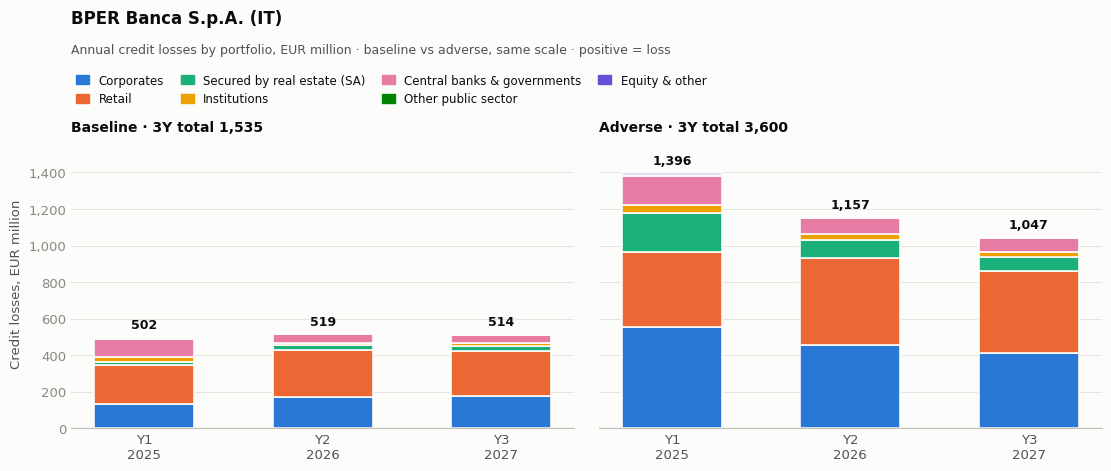

In [58]:
report_bank('N747OI7JINV7RUUH6190')  # IT · BPER Banca S.p.A.

Under the **adverse** scenario, credit losses total **EUR 3,486 m** over 2025–2027 (2.20% of 2024 exposure), against EUR 1,317 m in the baseline. Year 1 accounts for 46% of the adverse total (Y1 1,588, Y2 957, Y3 941). Largest adverse contributors: Corporates EUR 1,524 m (44%, loss rate 3.42%); Retail EUR 929 m (27%, loss rate 2.36%).

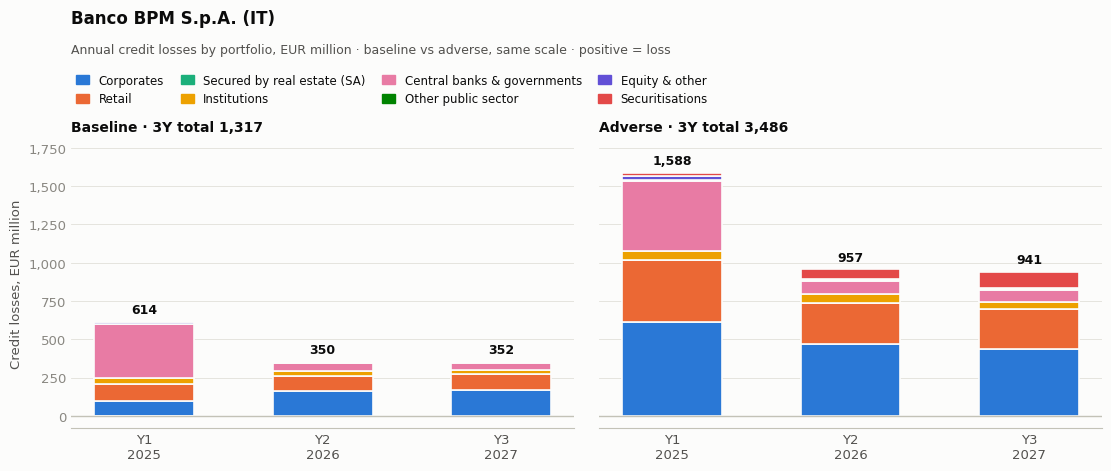

In [59]:
report_bank('815600E4E6DCD2D25E30')  # IT · Banco BPM S.p.A.

Under the **adverse** scenario, credit losses total **EUR 4,216 m** over 2025–2027 (2.73% of 2024 exposure), against EUR 1,234 m in the baseline. Year 1 accounts for 39% of the adverse total (Y1 1,644, Y2 1,329, Y3 1,242). Largest adverse contributors: Secured by real estate (SA) EUR 1,572 m (37%, loss rate 3.17%); Retail EUR 1,070 m (25%, loss rate 6.73%).

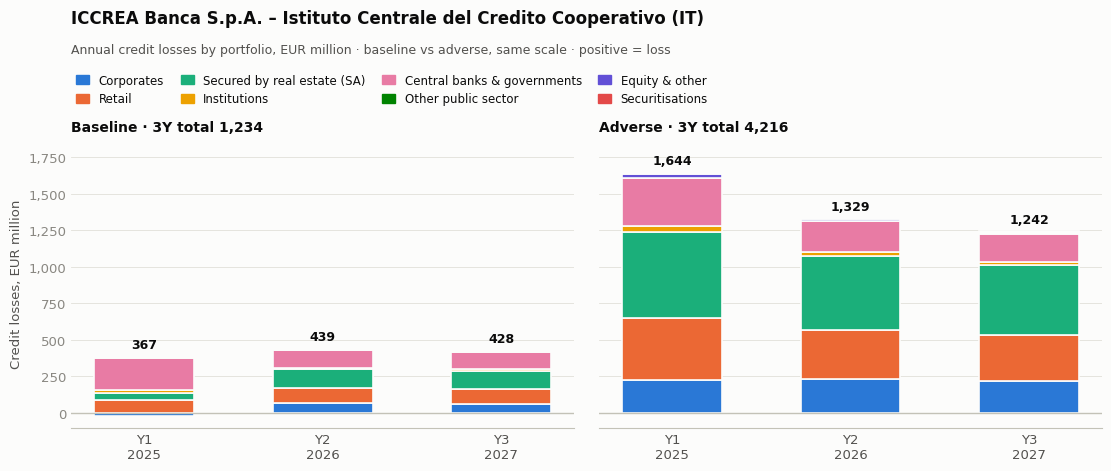

In [60]:
report_bank('NNVPP80YIZGEY2314M97')  # IT · ICCREA Banca S.p.A. – Istituto Centrale del Credito Cooperativo

Under the **adverse** scenario, credit losses total **EUR 10,063 m** over 2025–2027 (1.60% of 2024 exposure), against EUR 2,843 m in the baseline. Year 1 accounts for 42% of the adverse total (Y1 4,202, Y2 2,950, Y3 2,911). Largest adverse contributors: Corporates EUR 4,988 m (50%, loss rate 2.91%); Retail EUR 3,252 m (32%, loss rate 1.94%).

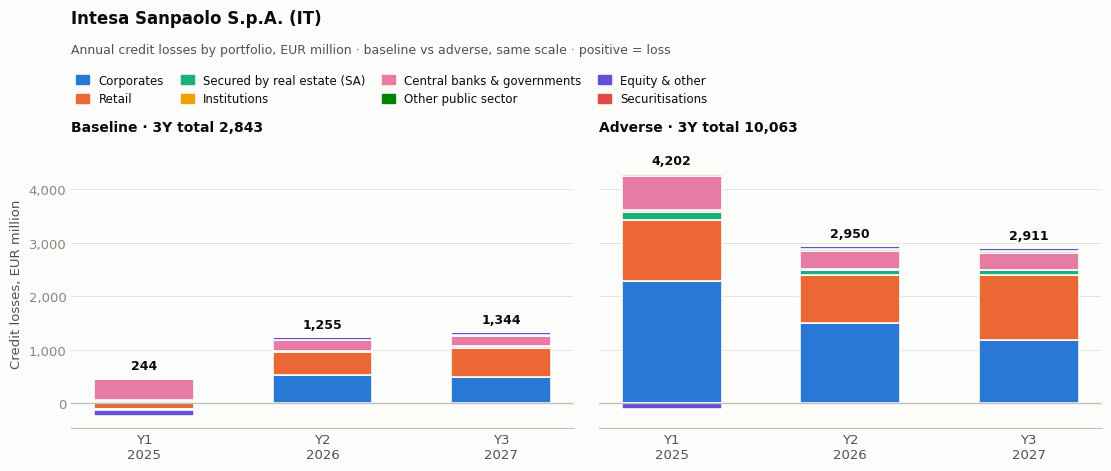

In [61]:
report_bank('2W8N8UU78PMDQKZENC08')  # IT · Intesa Sanpaolo S.p.A.

Under the **adverse** scenario, credit losses total **EUR 9,194 m** over 2025–2027 (1.39% of 2024 exposure), against EUR 2,494 m in the baseline. Year 1 accounts for 44% of the adverse total (Y1 4,076, Y2 2,849, Y3 2,269). Largest adverse contributors: Corporates EUR 5,121 m (56%, loss rate 2.10%); Retail EUR 2,745 m (30%, loss rate 2.07%).

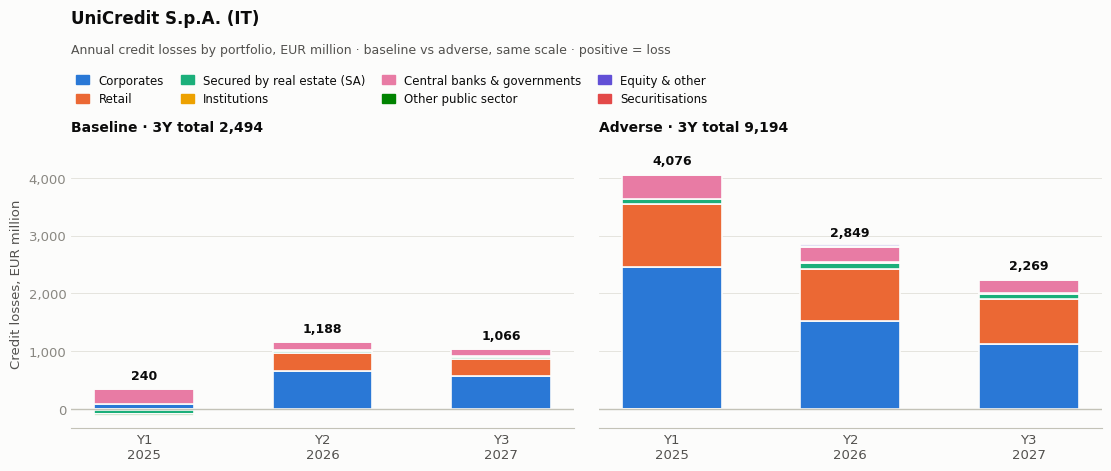

In [62]:
report_bank('549300TRUWO2CD2G5692')  # IT · UniCredit S.p.A.

Under the **adverse** scenario, credit losses total **EUR 6,121 m** over 2025–2027 (1.90% of 2024 exposure), against EUR 1,719 m in the baseline. Year 1 accounts for 50% of the adverse total (Y1 3,065, Y2 1,606, Y3 1,450). Largest adverse contributors: Corporates EUR 3,314 m (54%, loss rate 3.40%); Retail EUR 2,783 m (45%, loss rate 1.66%).

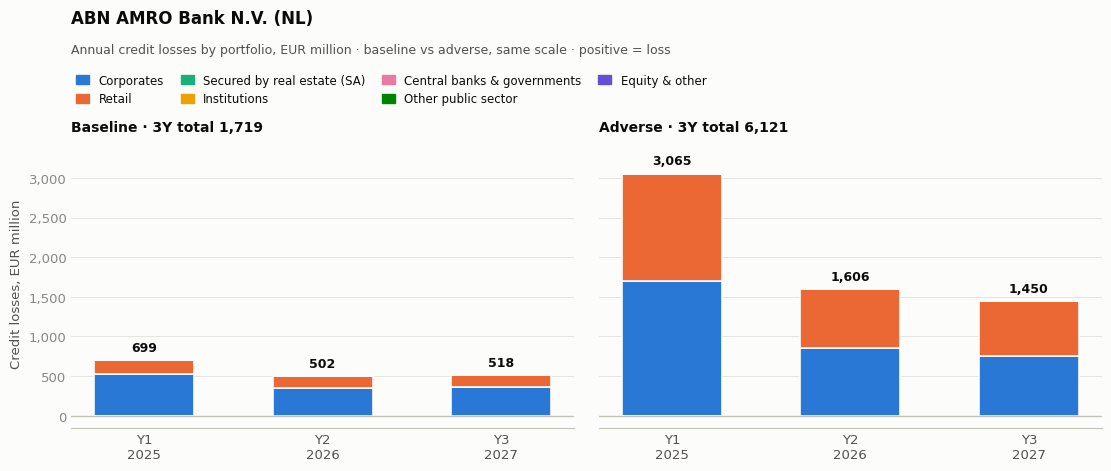

In [63]:
report_bank('BFXS5XCH7N0Y05NIXW11')  # NL · ABN AMRO Bank N.V.

Under the **adverse** scenario, credit losses total **EUR 11,797 m** over 2025–2027 (1.93% of 2024 exposure), against EUR 2,991 m in the baseline. Year 1 accounts for 60% of the adverse total (Y1 7,048, Y2 2,609, Y3 2,140). Largest adverse contributors: Corporates EUR 7,931 m (67%, loss rate 3.12%); Retail EUR 3,806 m (32%, loss rate 1.49%).

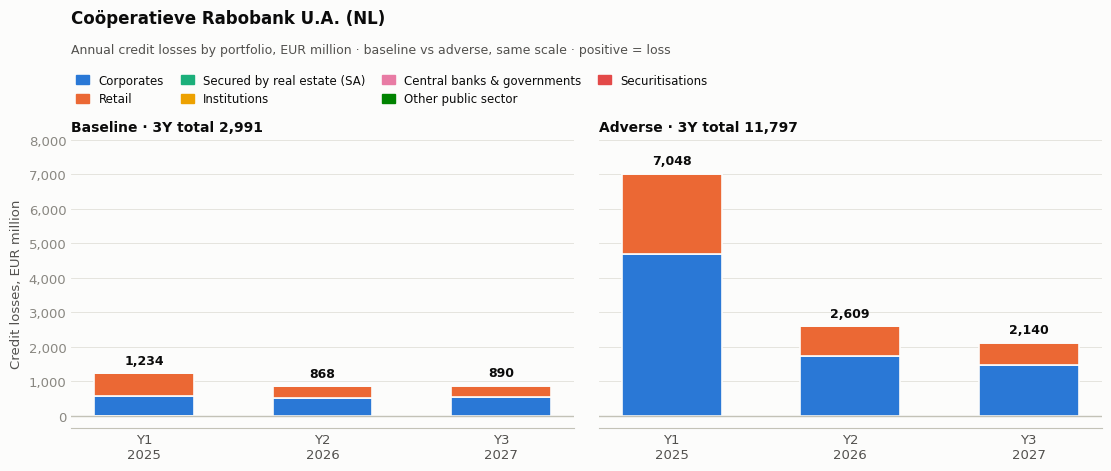

In [64]:
report_bank('DG3RU1DBUFHT4ZF9WN62')  # NL · Coöperatieve Rabobank U.A.

Under the **adverse** scenario, credit losses total **EUR 10,850 m** over 2025–2027 (1.12% of 2024 exposure), against EUR 3,103 m in the baseline. Year 1 accounts for 62% of the adverse total (Y1 6,777, Y2 2,536, Y3 1,537). Largest adverse contributors: Retail EUR 5,614 m (52%, loss rate 1.42%); Corporates EUR 4,245 m (39%, loss rate 1.38%).

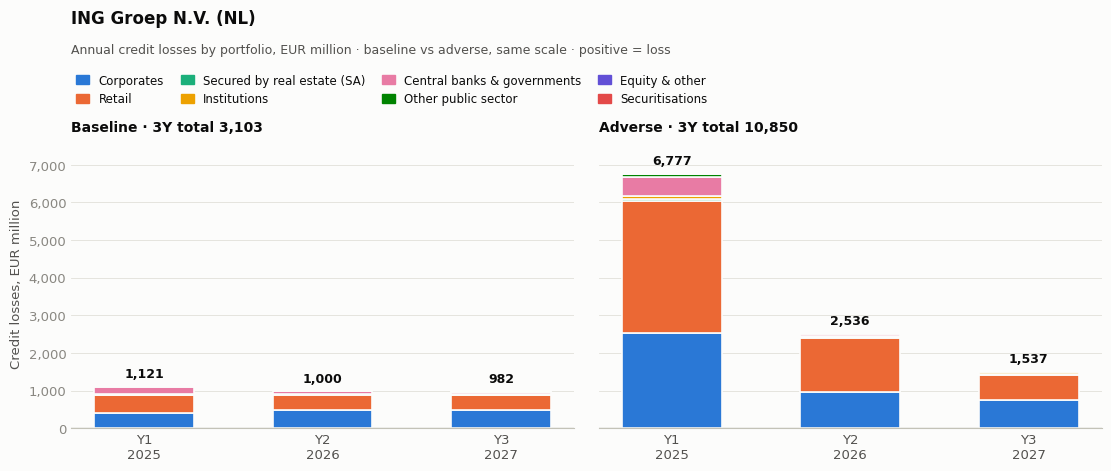

In [65]:
report_bank('549300NYKK9MWM7GGW15')  # NL · ING Groep N.V.

Under the **adverse** scenario, credit losses total **EUR 3,339 m** over 2025–2027 (1.33% of 2024 exposure), against EUR 578 m in the baseline. Year 1 accounts for 76% of the adverse total (Y1 2,539, Y2 481, Y3 319). Largest adverse contributors: Corporates EUR 2,712 m (81%, loss rate 2.83%); Retail EUR 527 m (16%, loss rate 0.53%).

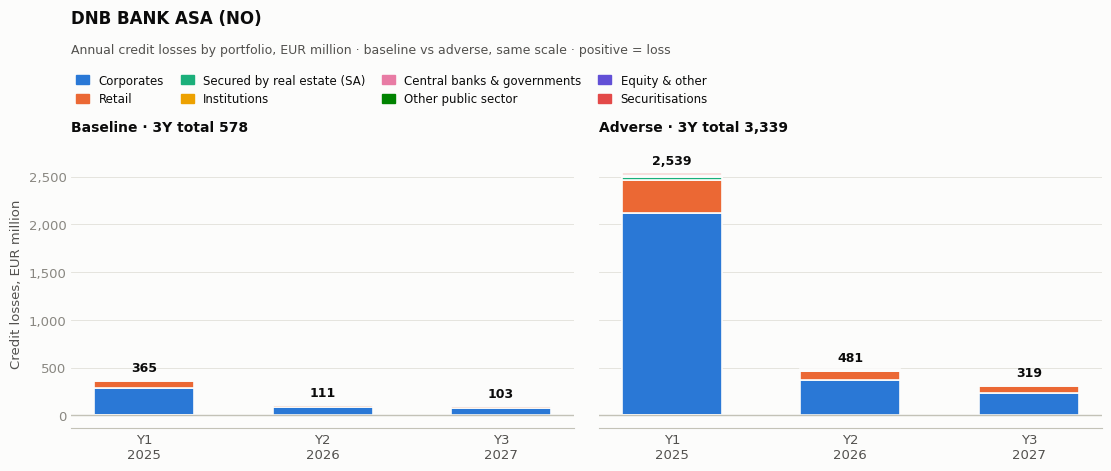

In [66]:
report_bank('549300GKFG0RYRRQ1414')  # NO · DNB BANK ASA

Under the **adverse** scenario, credit losses total **EUR 1,506 m** over 2025–2027 (1.89% of 2024 exposure), against EUR 736 m in the baseline. Year 1 accounts for 55% of the adverse total (Y1 821, Y2 362, Y3 323). Largest adverse contributors: Corporates EUR 710 m (47%, loss rate 3.45%); Secured by real estate (SA) EUR 321 m (21%, loss rate 1.73%).

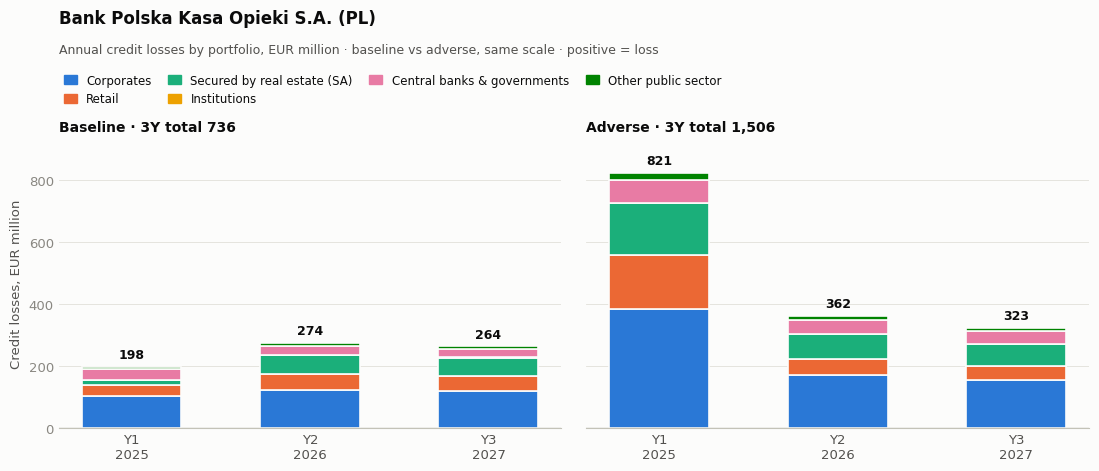

In [67]:
report_bank('5493000LKS7B3UTF7H35')  # PL · Bank Polska Kasa Opieki S.A.

Under the **adverse** scenario, credit losses total **EUR 2,042 m** over 2025–2027 (2.82% of 2024 exposure), against EUR 846 m in the baseline. Year 1 accounts for 34% of the adverse total (Y1 684, Y2 721, Y3 636). Largest adverse contributors: Retail EUR 1,408 m (69%, loss rate 7.38%); Secured by real estate (SA) EUR 343 m (17%, loss rate 1.12%).

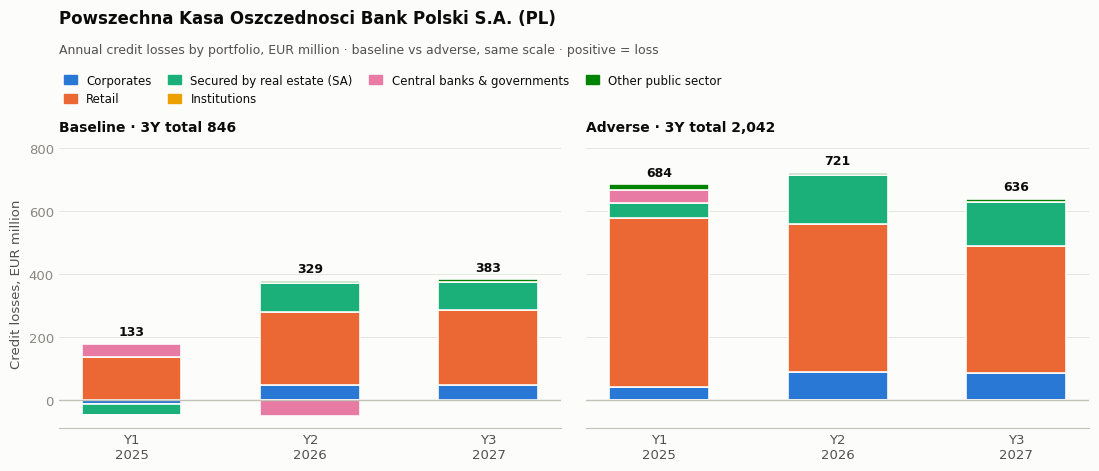

In [68]:
report_bank('P4GTT6GF1W40CVIMFR43')  # PL · Powszechna Kasa Oszczednosci Bank Polski S.A.

Under the **adverse** scenario, credit losses total **EUR 2,572 m** over 2025–2027 (2.90% of 2024 exposure), against EUR 846 m in the baseline. Year 1 accounts for 55% of the adverse total (Y1 1,413, Y2 647, Y3 512). Largest adverse contributors: Retail EUR 1,409 m (55%, loss rate 3.74%); Corporates EUR 756 m (29%, loss rate 5.67%). The credit-template total differs from the P&L impairment line by up to EUR 44.2 m in a scenario-year (memo rows).

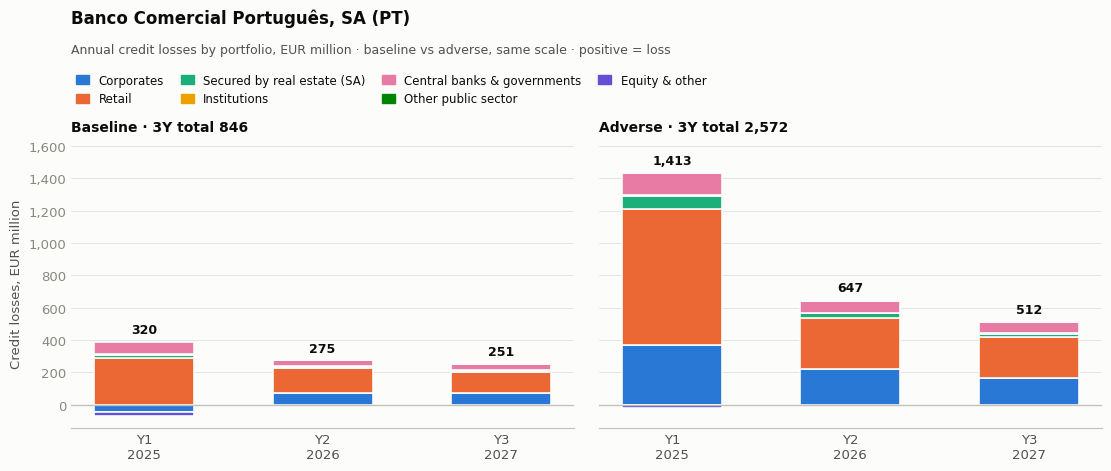

In [69]:
report_bank('JU1U6S0DG9YLT7N8ZV32')  # PT · Banco Comercial Português, SA

Under the **adverse** scenario, credit losses total **EUR 2,143 m** over 2025–2027 (2.15% of 2024 exposure), against EUR 166 m in the baseline. Year 1 accounts for 40% of the adverse total (Y1 853, Y2 716, Y3 574). Largest adverse contributors: Secured by real estate (SA) EUR 851 m (40%, loss rate 2.52%); Retail EUR 608 m (28%, loss rate 9.78%).

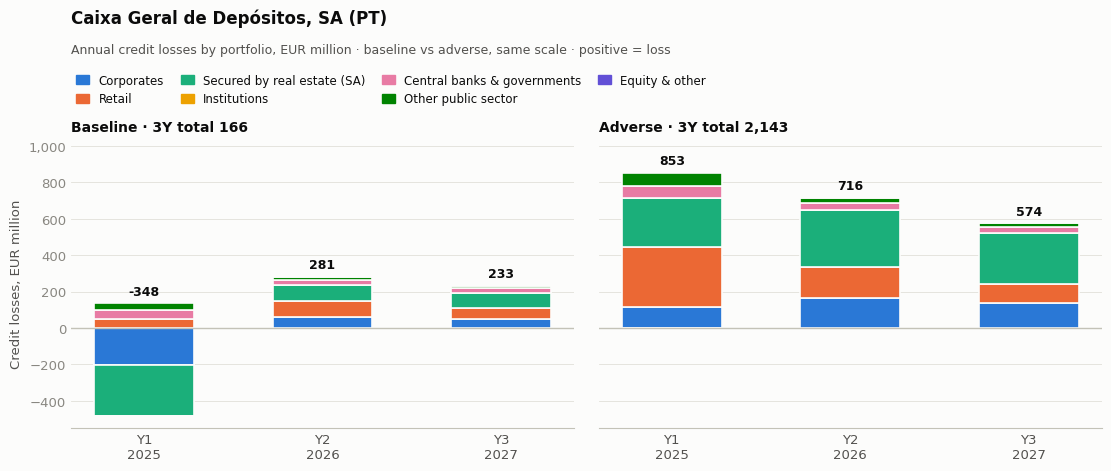

In [70]:
report_bank('TO822O0VT80V06K0FH57')  # PT · Caixa Geral de Depósitos, SA

Under the **adverse** scenario, credit losses total **EUR 1,365 m** over 2025–2027 (3.93% of 2024 exposure), against EUR 437 m in the baseline. Year 1 accounts for 31% of the adverse total (Y1 425, Y2 579, Y3 362). Largest adverse contributors: Secured by real estate (SA) EUR 577 m (42%, loss rate 6.60%); Central banks & governments EUR 266 m (19%, loss rate 2.25%).

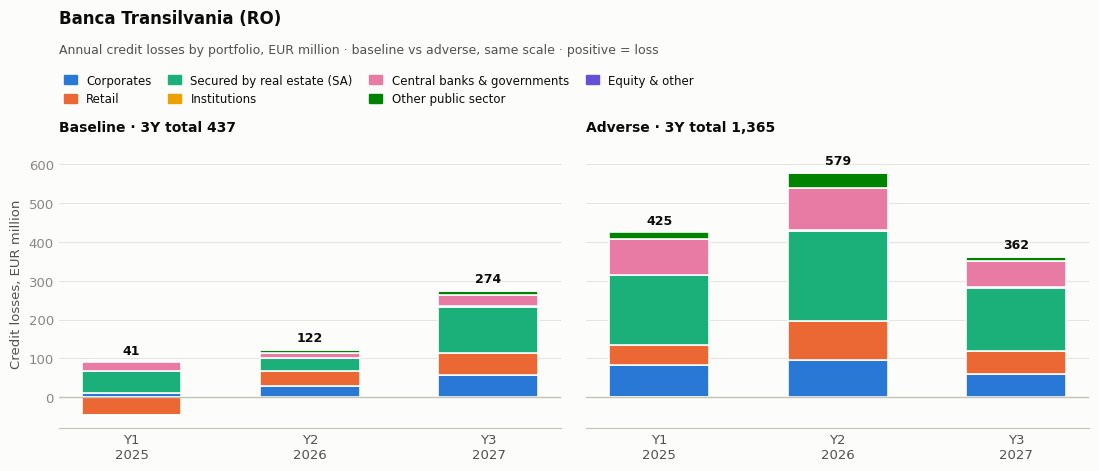

In [71]:
report_bank('549300RG3H390KEL8896')  # RO · Banca Transilvania

Under the **adverse** scenario, credit losses total **EUR 252 m** over 2025–2027 (0.68% of 2024 exposure), against EUR 53 m in the baseline. Year 1 accounts for 36% of the adverse total (Y1 92, Y2 73, Y3 88). Largest adverse contributors: Retail EUR 230 m (91%, loss rate 0.68%); Corporates EUR 21 m (8%, loss rate 0.67%).

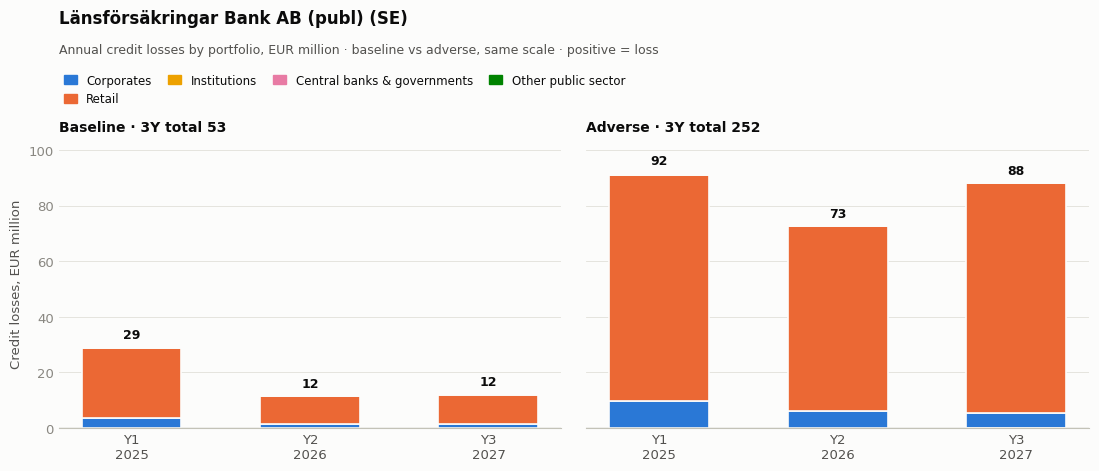

In [72]:
report_bank('549300C6TUMDXNOVXS82')  # SE · Länsförsäkringar Bank AB (publ)

Under the **adverse** scenario, credit losses total **EUR 765 m** over 2025–2027 (1.59% of 2024 exposure), against EUR 22 m in the baseline. Year 1 accounts for 36% of the adverse total (Y1 274, Y2 217, Y3 274). Largest adverse contributors: Retail EUR 489 m (64%, loss rate 1.48%); Corporates EUR 276 m (36%, loss rate 1.84%).

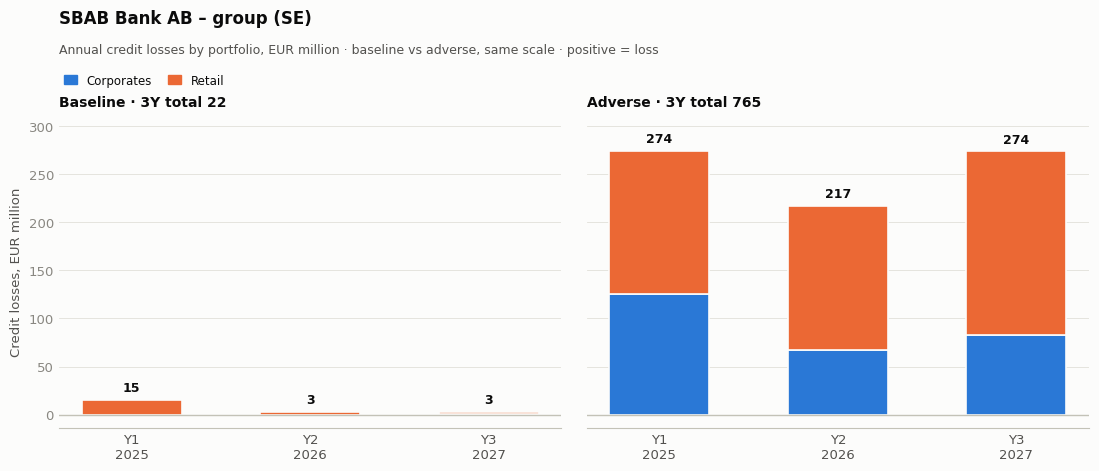

In [73]:
report_bank('H0YX5LBGKDVOWCXBZ594')  # SE · SBAB Bank AB – group

Under the **adverse** scenario, credit losses total **EUR 5,271 m** over 2025–2027 (2.27% of 2024 exposure), against EUR 345 m in the baseline. Year 1 accounts for 59% of the adverse total (Y1 3,121, Y2 1,222, Y3 928). Largest adverse contributors: Corporates EUR 4,068 m (77%, loss rate 3.35%); Retail EUR 976 m (19%, loss rate 1.51%). The credit-template total differs from the P&L impairment line by up to EUR 350.0 m in a scenario-year (memo rows).

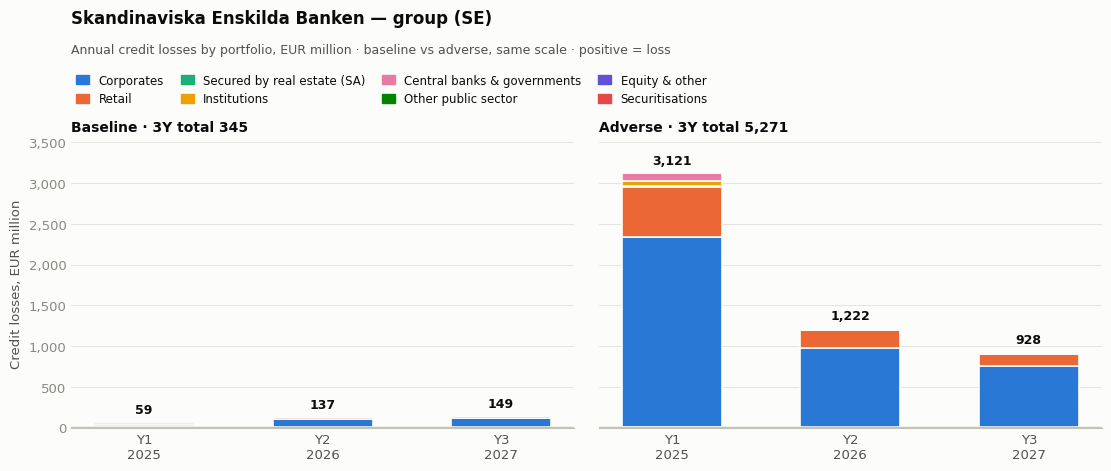

In [74]:
report_bank('F3JS33DEI6XQ4ZBPTN86')  # SE · Skandinaviska Enskilda Banken — group

Under the **adverse** scenario, credit losses total **EUR 4,711 m** over 2025–2027 (1.64% of 2024 exposure), against EUR -35 m in the baseline. Year 1 accounts for 54% of the adverse total (Y1 2,564, Y2 1,087, Y3 1,059). Largest adverse contributors: Corporates EUR 2,199 m (47%, loss rate 2.54%); Retail EUR 2,145 m (46%, loss rate 2.19%). The credit-template total differs from the P&L impairment line by up to EUR 7.3 m in a scenario-year (memo rows).

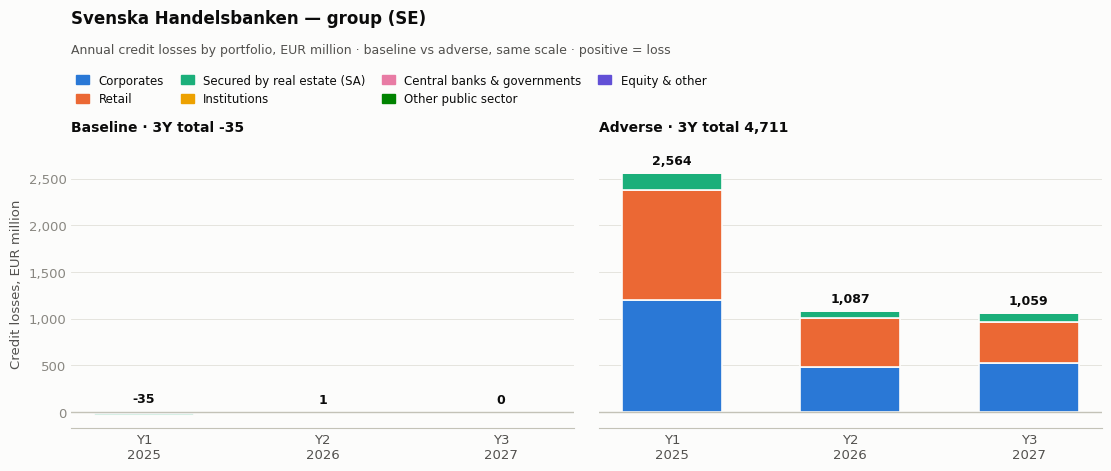

In [75]:
report_bank('NHBDILHZTYCNBV5UYZ31')  # SE · Svenska Handelsbanken — group

Under the **adverse** scenario, credit losses total **EUR 4,078 m** over 2025–2027 (1.88% of 2024 exposure), against EUR 1,220 m in the baseline. Year 1 accounts for 54% of the adverse total (Y1 2,218, Y2 1,322, Y3 538). Largest adverse contributors: Corporates EUR 2,254 m (55%, loss rate 3.72%); Retail EUR 1,817 m (45%, loss rate 1.71%).

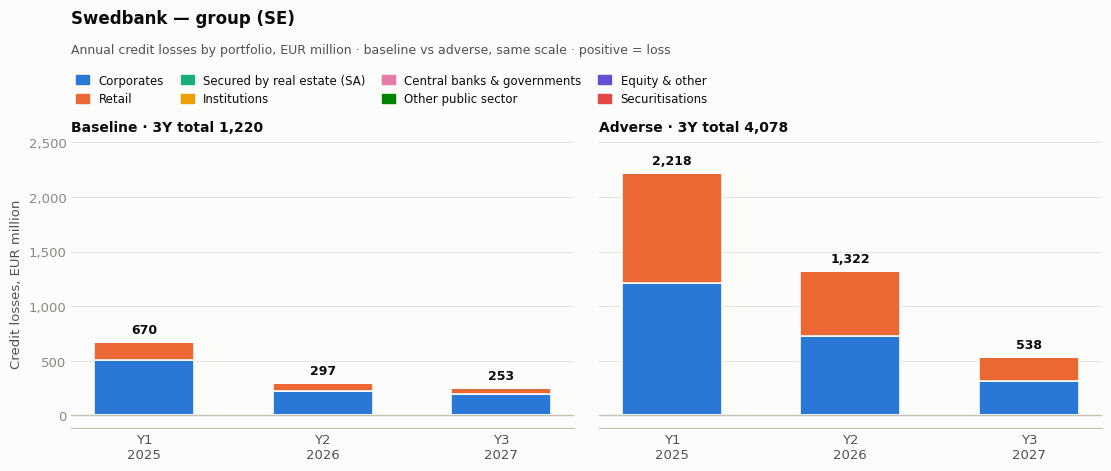

In [76]:
report_bank('M312WZV08Y7LYUC71685')  # SE · Swedbank — group

## 8. Reuse, exports and limitations

Objects available for further work: `losses` (bank × approach × portfolio × segment × stage, columns
scenario × year), `exposure_2024`, `bank_losses`, `pl_losses`, `recon_diff`, `summary`, `adverse_rates`,
`rate_points_all` (bank × portfolio exposure, three-year losses and loss rates for all credit losses and for
new defaults, bank size, region and size group, exclusion flags), `rules` and `size_rules` (rules of thumb
by region and by size).
`report_bank(lei)` regenerates one report. Set `EXPORT_RESULTS = True` in the setup cell to write CSVs.

**Limitations.** Credit losses per portfolio are measured as changes in the published provision stocks.
This equals the impairment charge under the methodology's static balance sheet, and the bank totals
reconcile to the P&L for most banks; where they do not, the difference is shown in each report's memo
rows and is not allocated to portfolios. Securitisation impairments are not split by stage or by
underlying portfolio. Stage-level changes include stage migration and are not P&L flows by themselves.
Loss rates use the restated end-2024 exposure as denominator. The figures are hypothetical outcomes of
prescribed scenarios; for official results the bank-level EBA PDFs take precedence.

In [77]:
if report_count != EXPECTED_BANKS:
    raise ValueError(f'Expected {EXPECTED_BANKS} bank reports, generated {report_count}')
if EXPORT_RESULTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    long = losses.stack(['scenario', 'year'], future_stack=True).rename('credit_loss_eur_m').reset_index()
    long['scenario'] = long['scenario'].map(SCENARIO_NAME)
    long.to_csv(OUTPUT_DIR / 'credit_losses_by_segment.csv', index=False, encoding='utf-8-sig')
    exposure_2024.rename('exposure_2024_eur_m').to_csv(OUTPUT_DIR / 'exposure_2024_by_segment.csv', encoding='utf-8-sig')
    summary.to_csv(OUTPUT_DIR / 'bank_summary.csv', index_label='lei_code', encoding='utf-8-sig')
    recon_diff.to_csv(OUTPUT_DIR / 'reconciliation_differences.csv', encoding='utf-8-sig')
    rate_points_all.to_csv(OUTPUT_DIR / 'loss_rates_by_bank_portfolio.csv', index=False, encoding='utf-8-sig')
    print(f'Exports written to {OUTPUT_DIR.resolve()}')
print(f'Completed: {report_count} bank reports; {matched} of {len(recon_max)} banks reconcile to the P&L within EUR {RECON_TOL} m.')

Completed: 64 bank reports; 52 of 64 banks reconcile to the P&L within EUR 0.5 m.
